# PDAC Mets Visium Modular Clean

This notebook is the clean starting point for the PDAC Visium metastasis dataset using the processed flat export from `PDAC_Updated.rds`.

Scope of this notebook:
- load a patient-8 triad across primary tumor, lymph-node metastasis, and liver sample
- summarize the sample composition and spot-level count scale
- train baseline continuous fields per sample
- train one shared profile autoencoder across the triad for splat seeding

Initial patient-8 triad:
- `IU_PDA_T8`: primary pancreas tumor
- `IU_PDA_LNM8`: lymph-node metastasis
- `IU_PDA_HM8`: liver sample with potential infiltration structure


In [1]:
from pathlib import Path
import os
import sys
import random

os.environ.setdefault('NUMBA_CACHE_DIR', '/tmp/numba_cache')
os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import (
    AmplitudeSplatField,
    DataConfig,
    SplatConfig,
    build_cell_only_targets,
    composition_cosine_loss,
    create_amplitude_splat_optimizer,
    evaluate_count_model,
    farthest_point_sample_indices,
    compute_splat_weights,
    usage_statistics,
    log_total_count_loss,
    mae_count_loss,
    sample_tissue_support,
    GeneProfileAutoencoder,
    evaluate_profile_autoencoder,
    train_profile_autoencoder,
)
from spatsplat.baselines import CountMLP, KNNCountRegressor, MeanProfileBaseline
from paper.data_loaders.pdac_mets_visium import load_pdac_mets_visium_dataset


from PIL import Image

FIGURE_EXPORT_DIR = PROJECT_ROOT / 'figures' / 'pdac_mets_visium_modular_clean'
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def _slugify_figure_name(text: str) -> str:
    text = (text or '').strip().lower()
    text = ''.join(ch if ch.isalnum() else '_' for ch in text)
    while '__' in text:
        text = text.replace('__', '_')
    return text.strip('_') or 'figure'


def export_figure_axes(fig, fallback_prefix: str = "figure", dpi: int = 300, canvas_px: int = 2200):
    from PIL import Image

    titled_axes = []
    for ax in fig.axes:
        title = ax.get_title().strip() if hasattr(ax, "get_title") else ""
        if title:
            titled_axes.append((ax, title))
    if not titled_axes:
        return []

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width, height = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8).reshape(height, width, 4)
    all_bboxes = {ax: ax.get_tightbbox(renderer) for ax in fig.axes}
    saved_paths = []

    def _merge_with_adjacent_colorbars(main_ax, main_bbox):
        merged = main_bbox
        main_w = max(float(main_bbox.width), 1.0)
        main_h = max(float(main_bbox.height), 1.0)
        for other_ax in fig.axes:
            if other_ax is main_ax:
                continue
            other_bbox = all_bboxes.get(other_ax)
            if other_bbox is None:
                continue
            other_title = other_ax.get_title().strip() if hasattr(other_ax, "get_title") else ""
            if other_title:
                continue

            horiz_gap = min(abs(other_bbox.x1 - merged.x0), abs(other_bbox.x0 - merged.x1))
            vert_gap = min(abs(other_bbox.y1 - merged.y0), abs(other_bbox.y0 - merged.y1))
            y_overlap = max(0.0, min(merged.y1, other_bbox.y1) - max(merged.y0, other_bbox.y0))
            x_overlap = max(0.0, min(merged.x1, other_bbox.x1) - max(merged.x0, other_bbox.x0))

            is_vertical_bar = (
                other_bbox.width < 0.22 * main_w
                and y_overlap > 0.55 * min(main_h, float(other_bbox.height))
                and horiz_gap < 0.08 * main_w
                and other_bbox.x0 >= merged.x1
            )
            is_horizontal_bar = (
                other_bbox.height < 0.22 * main_h
                and x_overlap > 0.55 * min(main_w, float(other_bbox.width))
                and vert_gap < 0.08 * main_h
                and other_bbox.y1 <= merged.y0
            )
            if is_vertical_bar or is_horizontal_bar:
                merged = merged.union([merged, other_bbox])
        return merged

    for idx, (ax, title) in enumerate(titled_axes, start=1):
        base = _slugify_figure_name(f"{fallback_prefix}_{title}")
        if not base:
            base = _slugify_figure_name(f"{fallback_prefix}_{idx}")
        out_path = FIGURE_EXPORT_DIR / f"{base}.png"

        bbox = _merge_with_adjacent_colorbars(ax, all_bboxes[ax]).expanded(1.03, 1.08)
        x0 = max(0, int(np.floor(bbox.x0)))
        y0 = max(0, int(np.floor(bbox.y0)))
        x1 = min(width, int(np.ceil(bbox.x1)))
        y1 = min(height, int(np.ceil(bbox.y1)))
        if x1 <= x0 or y1 <= y0:
            continue

        crop = buf[height - y1:height - y0, x0:x1].copy()
        crop_img = Image.fromarray(crop)
        side = max(crop_img.width, crop_img.height)
        square = Image.new("RGBA", (side, side), (255, 255, 255, 255))
        offset = ((side - crop_img.width) // 2, (side - crop_img.height) // 2)
        square.paste(crop_img, offset)
        if side != canvas_px:
            square = square.resize((canvas_px, canvas_px), Image.Resampling.LANCZOS)
        square.save(out_path)
        saved_paths.append(str(out_path))
    return saved_paths


In [2]:
patient8_samples = {
    'primary': 'IU_PDA_T8',
    'lymph_node_met': 'IU_PDA_LNM8',
    'liver_sample': 'IU_PDA_HM8',
}

random_seed = 1023
device = 'cuda' if torch.cuda.is_available() else 'cpu'
plot_point_size = 0.5

baseline_val_fraction = 0.1
baseline_test_fraction = 0.1
baseline_mlp_hidden_dim = 128
baseline_mlp_epochs = 100
baseline_mlp_batch_size = 4096
baseline_mlp_lr = 1e-3
baseline_knn_k = 32

shared_ae_hidden_dim = 128
shared_ae_latent_dim = 32
shared_ae_epochs = 150
shared_ae_batch_size = 1024
shared_ae_lr = 1e-3

splat_init_log_amplitude = 6.0
splat_spots_per_component = 8
splat_min_components = 256
splat_max_components = 640
section_splat_epochs = 150
section_splat_batch_size = 2048
section_splat_means_lr = 5e-3
section_splat_log_scales_lr = 1e-3
section_splat_rotation_lr = 1e-3
section_splat_opacity_lr = 1e-3
section_splat_latents_lr = 1e-3
section_splat_log_theta_lr = 1e-3
section_splat_decoder_lr = 1e-3
section_splat_amplitude_lr = 1e-3
section_composition_loss_weight = 1.0
section_total_count_loss_weight = 0.2
section_mae_refine_weight = 1.0
section_mae_refine_fraction = 0.25
section_seed_neighbor_k = 16
section_off_tissue_batch_size = 2048
section_off_tissue_weight = 1e-6
section_center_support_weight = 0.001


data_cfg = DataConfig(mask_grid_size=128, cell_mask_min_radius=2.5)
display_sig_digits = 4


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.{display_sig_digits}g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)


sample_seed_offsets = {sample_name: idx for idx, sample_name in enumerate(sorted(patient8_samples.values()))}


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def sample_seed(sample_name: str, *, base_seed: int = random_seed) -> int:
    return int(base_seed + 1000 * sample_seed_offsets[str(sample_name)])


def choose_num_splats(n_spots: int) -> int:
    raw_value = int(round(n_spots / splat_spots_per_component))
    return int(np.clip(raw_value, splat_min_components, splat_max_components))


def make_section_splat_config(num_splats: int) -> SplatConfig:
    return SplatConfig(
        num_splats=int(num_splats),
        latent_dim=shared_ae_latent_dim,
        hidden_dim=shared_ae_hidden_dim,
        init_log_scale=-4.5,
        kernel_sharpness=1.0,
    )


set_seed(random_seed)


In [3]:
def load_sample_bundle(sample_name: str):
    loaded = load_pdac_mets_visium_dataset(sample_name=sample_name)
    dataset = build_cell_only_targets(loaded, data_cfg)
    adata = loaded.adata

    counts = dataset.cell_targets.detach().cpu().numpy().astype(np.float32)
    total_counts = counts.sum(axis=1, keepdims=True)
    profiles = counts / np.clip(total_counts, 1e-6, None)
    num_splats = choose_num_splats(int(adata.n_obs))

    bundle = {
        'sample_name': sample_name,
        'loaded': loaded,
        'dataset': dataset,
        'adata': adata,
        'counts': torch.tensor(counts, dtype=torch.float32),
        'total_counts': torch.tensor(total_counts, dtype=torch.float32),
        'profiles': torch.tensor(profiles, dtype=torch.float32),
        'xy_norm': dataset.cell_features.detach().cpu(),
        'xy_raw': adata.obs[['x_centroid', 'y_centroid']].to_numpy(dtype=np.float32),
        'gene_names': list(map(str, adata.var_names)),
        'origin': adata.obs['Origin'].astype(str).mode().iat[0],
        'patient': adata.obs['patient'].astype(str).mode().iat[0],
        'sample_id2': adata.obs['Sample_ID2'].astype(str).mode().iat[0],
        'image_name': adata.obs['image_name'].astype(str).mode().iat[0],
        'off_tissue_points': dataset.off_tissue_points.detach().cpu(),
        'tissue_mask_tensor': dataset.tissue_mask_tensor.detach().cpu(),
        'num_splats': num_splats,
        'splat_cfg': make_section_splat_config(num_splats),
        'split_seed': sample_seed(sample_name),
    }
    return bundle


sample_bundles = {label: load_sample_bundle(sample_name) for label, sample_name in patient8_samples.items()}

sample_dataset_summary = {
    label: {
        'sample_name': bundle['sample_name'],
        'origin': bundle['origin'],
        'patient': bundle['patient'],
        'sample_id2': bundle['sample_id2'],
        'n_spots': int(bundle['adata'].n_obs),
        'n_genes': int(bundle['adata'].n_vars),
        'mean_total_count': float(bundle['counts'].sum(dim=1).mean().item()),
        'median_total_count': float(torch.median(bundle['counts'].sum(dim=1)).item()),
        'q90_total_count': float(torch.quantile(bundle['counts'].sum(dim=1), 0.9).item()),
        'num_splats': int(bundle['num_splats']),
    }
    for label, bundle in sample_bundles.items()
}

print('Patient-8 sample summary')
print(format_for_display(sample_dataset_summary))



Patient-8 sample summary
{'primary': {'sample_name': 'IU_PDA_T8', 'origin': 'Pancreas', 'patient': 'PT_8', 'sample_id2': 'S20-11446_B9', 'n_spots': 3779, 'n_genes': 17893, 'mean_total_count': 2661.0, 'median_total_count': 1899.0, 'q90_total_count': 5803.0, 'num_splats': 472}, 'lymph_node_met': {'sample_name': 'IU_PDA_LNM8', 'origin': 'Lymph node', 'patient': 'PT_8', 'sample_id2': 'S20-11446_B15', 'n_spots': 3407, 'n_genes': 17893, 'mean_total_count': 4093.0, 'median_total_count': 3606.0, 'q90_total_count': 8228.0, 'num_splats': 426}, 'liver_sample': {'sample_name': 'IU_PDA_HM8', 'origin': 'Liver', 'patient': 'PT_8', 'sample_id2': 'S20-11446_A1', 'n_spots': 4032, 'n_genes': 17893, 'mean_total_count': 1490.0, 'median_total_count': 1001.0, 'q90_total_count': 2936.0, 'num_splats': 504}}


## Sample Composition

Inspect the spot-type composition across the patient-8 triad before training any fields.


In [4]:
def summarize_sample_composition(bundle):
    obs = bundle['adata'].obs
    return {
        'Origin_counts': obs['Origin'].astype(str).value_counts().to_dict(),
        'spot_class_top10': obs['spot_class'].astype(str).value_counts().head(10).to_dict(),
        'first_type_top10': obs['first_type'].astype(str).value_counts().head(10).to_dict(),
        'second_type_top10': obs['second_type'].astype(str).value_counts().head(10).to_dict(),
        'first_class_counts': obs['first_class'].astype(str).value_counts().to_dict(),
        'second_class_counts': obs['second_class'].astype(str).value_counts().to_dict(),
    }

composition_summary = {label: summarize_sample_composition(bundle) for label, bundle in sample_bundles.items()}
print('Composition summary')
print(format_for_display(composition_summary))


Composition summary
{'primary': {'Origin_counts': {'Pancreas': 3779}, 'spot_class_top10': {'doublet_certain': 2351, 'singlet': 964, 'doublet_uncertain': 441, 'reject': 23}, 'first_type_top10': {'Tumor Epithelial cells': 2577, 'myCAF': 641, 'Normal Epithelial cells': 456, 'SPP1-TAM': 50, 'B cells': 32, 'iCAF': 10, 'C1Q-TAM': 7, 'DCs': 4, 'FCN1-TAM': 1, 'PVL': 1}, 'second_type_top10': {'myCAF': 1444, 'Tumor Epithelial cells': 847, 'Normal Epithelial cells': 545, 'SPP1-TAM': 350, 'iCAF': 183, 'Proliferative T cells': 129, 'B cells': 100, 'C1Q-TAM': 70, 'FCN1-TAM': 63, 'DCs': 26}, 'first_class_counts': {'False': 3779}, 'second_class_counts': {'False': 3779}}, 'lymph_node_met': {'Origin_counts': {'Lymph node': 3407}, 'spot_class_top10': {'doublet_certain': 2252, 'singlet': 787, 'doublet_uncertain': 328, 'reject': 40}, 'first_type_top10': {'Tumor Epithelial cells': 1345, 'B cells': 1075, 'Normal Epithelial cells': 711, 'DCs': 88, 'SPP1-TAM': 45, 'CD4+ cells': 40, 'myCAF': 35, 'iCAF': 32, 'C1

## Tissue Views

Compare the three patient-8 samples in normalized coordinates. Spots are colored by total counts and by the dominant first-type labels.


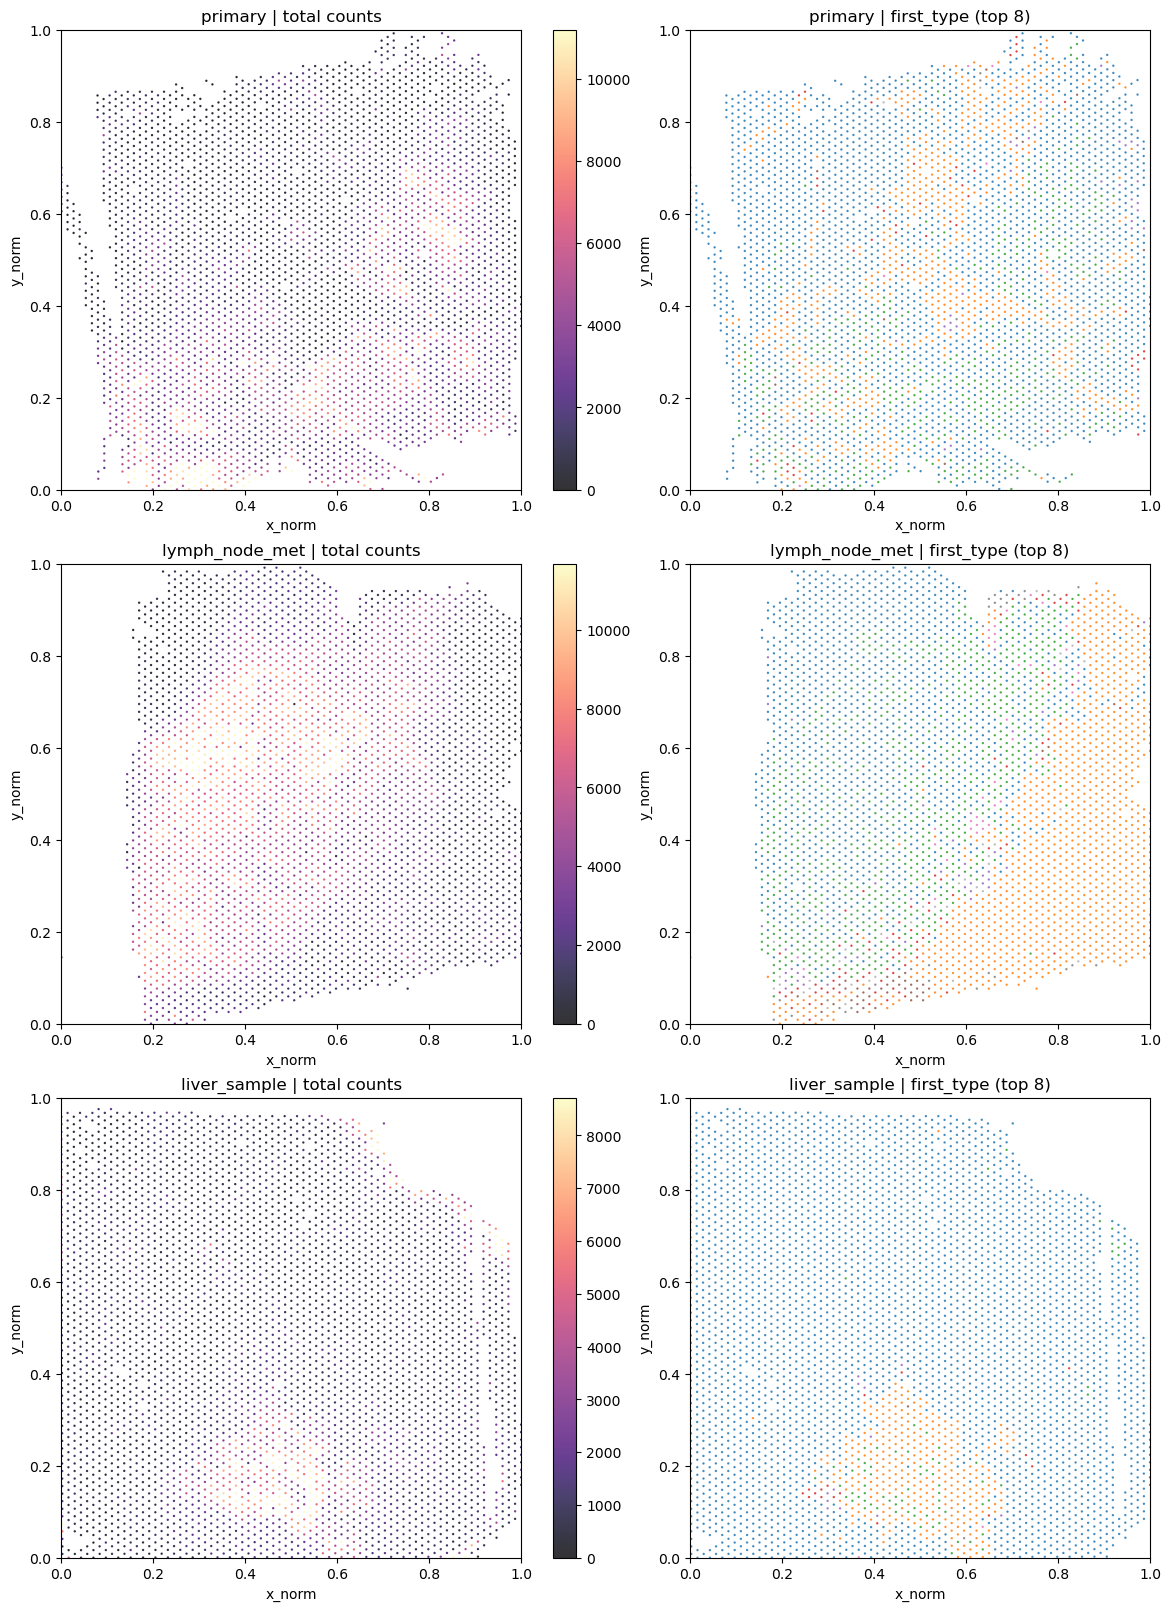

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 16), constrained_layout=True)
for row, (label, bundle) in enumerate(sample_bundles.items()):
    cell_points_np = bundle['dataset'].cell_features.detach().cpu().numpy()
    cell_total_counts_np = bundle['dataset'].cell_targets.sum(dim=1).detach().cpu().numpy()
    first_type_np = bundle['adata'].obs['first_type'].astype(str).to_numpy()

    vmax = np.quantile(cell_total_counts_np, 0.99) if len(cell_total_counts_np) else 1.0
    sc = axes[row, 0].scatter(
        cell_points_np[:, 0],
        cell_points_np[:, 1],
        c=cell_total_counts_np,
        s=plot_point_size,
        cmap='magma',
        alpha=0.8,
        vmin=0.0,
        vmax=vmax,
    )
    axes[row, 0].set_title(f'{label} | total counts')

    unique_types = pd.Index(first_type_np).value_counts().head(8).index.tolist()
    color_map = {name: plt.cm.tab10(i % 10) for i, name in enumerate(unique_types)}
    colors = [color_map.get(name, (0.7, 0.7, 0.7, 0.35)) for name in first_type_np]
    axes[row, 1].scatter(cell_points_np[:, 0], cell_points_np[:, 1], c=colors, s=plot_point_size, alpha=0.8)
    axes[row, 1].set_title(f'{label} | first_type (top 8)')

    for col in range(2):
        ax = axes[row, col]
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')

    fig.colorbar(sc, ax=axes[row, 0], fraction=0.046, pad=0.04)

export_figure_axes(fig, fallback_prefix='tissue_overview')
plt.show()


## Mask Diagnostics

Confirm that the support masks are sensible for each sample before training.


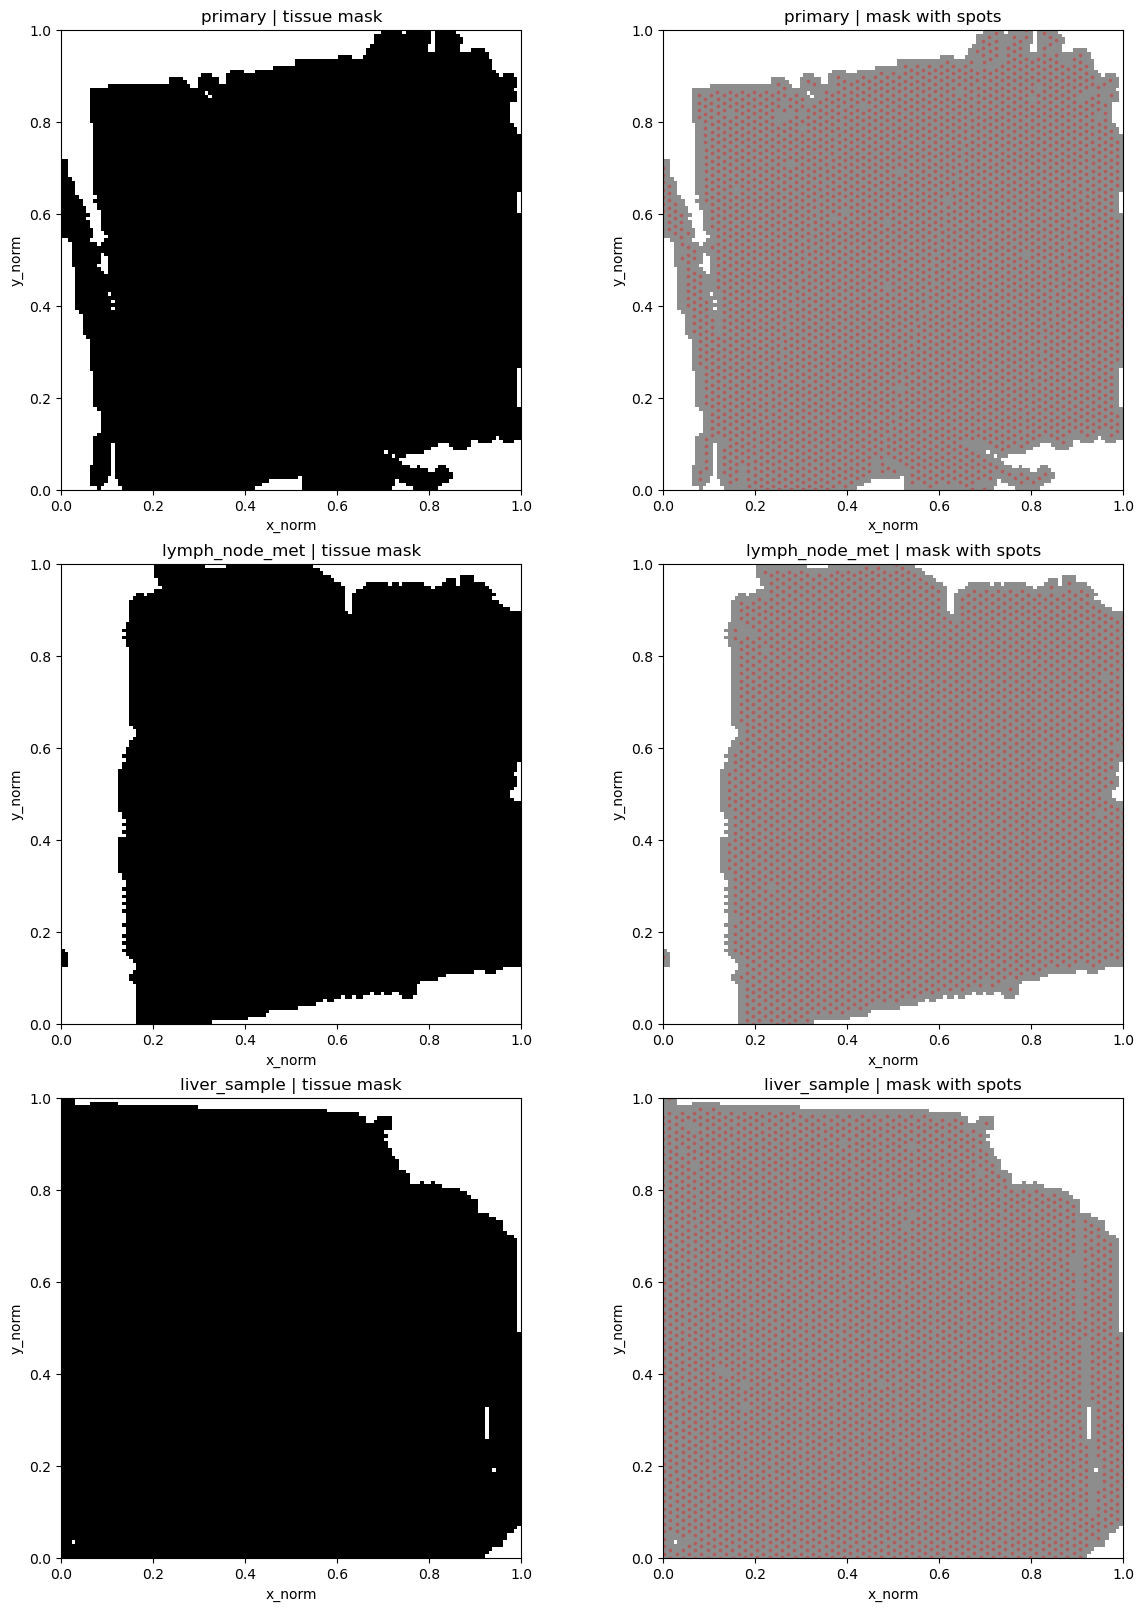

Mask summary
{'primary': {'mask_shape': (128, 128), 'mask_mean': 0.8508, 'off_tissue_points': 2444}, 'lymph_node_met': {'mask_shape': (128, 128), 'mask_mean': 0.7883, 'off_tissue_points': 3468}, 'liver_sample': {'mask_shape': (128, 128), 'mask_mean': 0.9185, 'off_tissue_points': 1335}}


In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 16), constrained_layout=True)
for row, (label, bundle) in enumerate(sample_bundles.items()):
    mask_np = bundle['dataset'].tissue_mask_tensor.squeeze().detach().cpu().numpy()
    cell_points_np = bundle['dataset'].cell_features.detach().cpu().numpy()

    axes[row, 0].imshow(mask_np, origin='lower', extent=[0, 1, 0, 1], cmap='gray_r')
    axes[row, 0].set_title(f'{label} | tissue mask')

    axes[row, 1].imshow(mask_np, origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.45)
    axes[row, 1].scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=3, alpha=0.25, color='red')
    axes[row, 1].set_title(f'{label} | mask with spots')

    for col in range(2):
        ax = axes[row, col]
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='tissue_masks')
plt.show()

mask_summary = {
    label: {
        'mask_shape': tuple(bundle['dataset'].tissue_mask_tensor.squeeze().shape),
        'mask_mean': float(bundle['dataset'].tissue_mask_tensor.mean().item()),
        'off_tissue_points': int(bundle['dataset'].off_tissue_points.shape[0]),
    }
    for label, bundle in sample_bundles.items()
}
print('Mask summary')
print(format_for_display(mask_summary))


## Split Setup

Create reproducible train/validation/test splits per sample for baselines and later splat fields.


In [7]:
def make_section_split_indices(n: int, val_fraction: float = baseline_val_fraction, test_fraction: float = baseline_test_fraction, seed: int = random_seed):
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    n_test = int(round(test_fraction * n))
    n_val = int(round(val_fraction * n))
    n_test = min(max(n_test, 1), max(1, n - 2))
    n_val = min(max(n_val, 1), max(1, n - n_test - 1))
    test_idx = perm[:n_test]
    val_idx = perm[n_test:n_test + n_val]
    train_idx = perm[n_test + n_val:]
    return {
        'train': torch.tensor(train_idx, dtype=torch.long),
        'val': torch.tensor(val_idx, dtype=torch.long),
        'test': torch.tensor(test_idx, dtype=torch.long),
    }

sample_splits = {
    label: make_section_split_indices(bundle['xy_norm'].shape[0], seed=bundle['split_seed'])
    for label, bundle in sample_bundles.items()
}

print('Split summary')
print(format_for_display({label: {k: int(v.numel()) for k, v in split_idx.items()} for label, split_idx in sample_splits.items()}))


Split summary
{'primary': {'train': 3023, 'val': 378, 'test': 378}, 'lymph_node_met': {'train': 2725, 'val': 341, 'test': 341}, 'liver_sample': {'train': 3226, 'val': 403, 'test': 403}}


## Baseline Fields

Train or build simple per-sample continuous-field baselines before adding splats.


In [8]:
def train_section_mlp(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor], *, hidden_dim: int = baseline_mlp_hidden_dim, epochs: int = baseline_mlp_epochs, batch_size: int = baseline_mlp_batch_size, lr: float = baseline_mlp_lr, seed: int = random_seed):
    set_seed(seed)
    model = CountMLP(input_dim=2, hidden_dim=hidden_dim, output_dim=section_counts.shape[1]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    xy = section_xy.to(device)
    counts = section_counts.to(device)
    train_idx = split_idx['train'].to(device)
    val_idx = split_idx['val'].to(device)
    test_idx = split_idx['test'].to(device)

    history = {'train_loss': [], 'val_loss': [], 'val_mae': []}
    for epoch in range(epochs):
        model.train()
        perm = train_idx[torch.randperm(len(train_idx), device=device)]
        running_loss = 0.0
        seen = 0
        for start in range(0, len(perm), batch_size):
            idx = perm[start:start + batch_size]
            pred_log_rate = model(xy[idx])
            loss = mae_count_loss(pred_log_rate, counts[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            running_loss += loss.item() * idx.numel()
            seen += idx.numel()
        train_loss = running_loss / max(seen, 1)
        val_summary = evaluate_count_model(model, xy, counts, val_idx, loss_fn=mae_count_loss)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_summary['loss'])
        history['val_mae'].append(val_summary['mae'])

    summary = {
        'train': evaluate_count_model(model, xy, counts, train_idx, loss_fn=mae_count_loss),
        'val': evaluate_count_model(model, xy, counts, val_idx, loss_fn=mae_count_loss),
        'test': evaluate_count_model(model, xy, counts, test_idx, loss_fn=mae_count_loss),
    }
    return {'model': model, 'history': history, 'summary': summary}


def build_section_knn(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor], *, k: int = baseline_knn_k):
    # Keep the KNN baseline on CPU; full-reference distance evaluation is memory-heavy on GPU.
    xy = section_xy.detach().cpu()
    counts = section_counts.detach().cpu()
    train_idx = split_idx['train'].detach().cpu()
    split_idx_cpu = {name: idx.detach().cpu() for name, idx in split_idx.items()}
    model = KNNCountRegressor(xy[train_idx], counts[train_idx], k=k)
    summary = {
        split_name: evaluate_count_model(model, xy, counts, idx, loss_fn=mae_count_loss)
        for split_name, idx in split_idx_cpu.items()
    }
    return {'model': model, 'summary': summary}


def build_section_mean_baseline(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor]):
    xy = section_xy.to(device)
    counts = section_counts.to(device)
    train_idx = split_idx['train'].to(device)
    split_idx_device = {name: idx.to(device) for name, idx in split_idx.items()}
    train_targets = counts[train_idx]
    model = MeanProfileBaseline(train_targets)
    summary = {
        split_name: evaluate_count_model(model, xy, counts, idx, loss_fn=mae_count_loss)
        for split_name, idx in split_idx_device.items()
    }
    return {'model': model, 'summary': summary}


In [9]:
baseline_field_results = {}
for offset, (label, bundle) in enumerate(sample_bundles.items()):
    mlp_result = train_section_mlp(bundle['xy_norm'], bundle['counts'], sample_splits[label], seed=random_seed + 100 + offset)
    mean_result = build_section_mean_baseline(bundle['xy_norm'], bundle['counts'], sample_splits[label])
    knn_result = build_section_knn(bundle['xy_norm'], bundle['counts'], sample_splits[label])
    baseline_field_results[label] = {
        'Mean baseline': mean_result,
        'MLP-MAE': mlp_result,
        'KNN': knn_result,
    }

baseline_summary = {
    label: {name: result['summary'] for name, result in results.items()}
    for label, results in baseline_field_results.items()
}
print('Baseline field summary')
print(format_for_display(baseline_summary))


Baseline field summary
{'primary': {'Mean baseline': {'train': {'loss': 0.2016, 'mae': 0.2016, 'n': 3023}, 'val': {'loss': 0.1885, 'mae': 0.1885, 'n': 378}, 'test': {'loss': 0.2097, 'mae': 0.2097, 'n': 378}}, 'MLP-MAE': {'train': {'loss': 0.1419, 'mae': 0.1419, 'n': 3023}, 'val': {'loss': 0.1232, 'mae': 0.1232, 'n': 378}, 'test': {'loss': 0.1539, 'mae': 0.1539, 'n': 378}}, 'KNN': {'train': {'loss': 0.002939, 'mae': 0.002939, 'n': 3023}, 'val': {'loss': 0.1605, 'mae': 0.1605, 'n': 378}, 'test': {'loss': 0.1845, 'mae': 0.1845, 'n': 378}}}, 'lymph_node_met': {'Mean baseline': {'train': {'loss': 0.2787, 'mae': 0.2787, 'n': 2725}, 'val': {'loss': 0.2797, 'mae': 0.2797, 'n': 341}, 'test': {'loss': 0.2871, 'mae': 0.2871, 'n': 341}}, 'MLP-MAE': {'train': {'loss': 0.2109, 'mae': 0.2109, 'n': 2725}, 'val': {'loss': 0.2132, 'mae': 0.2132, 'n': 341}, 'test': {'loss': 0.2261, 'mae': 0.2261, 'n': 341}}, 'KNN': {'train': {'loss': 0.004304, 'mae': 0.004304, 'n': 2725}, 'val': {'loss': 0.2278, 'mae': 0

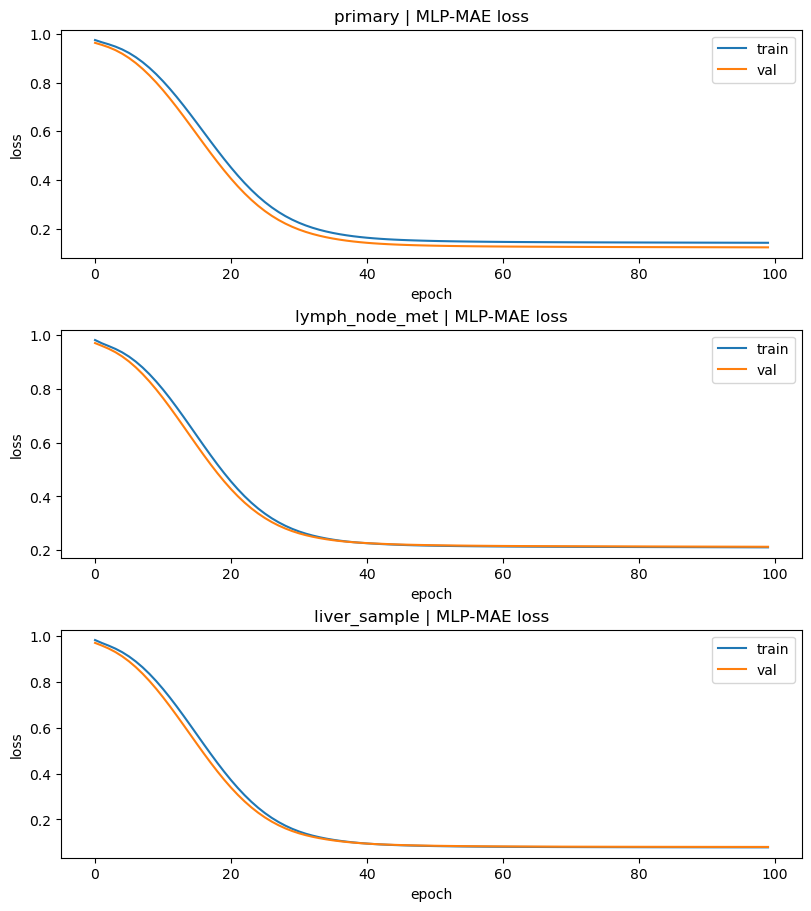

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(8, 9), constrained_layout=True)
for row, (label, results) in enumerate(baseline_field_results.items()):
    history = results['MLP-MAE']['history']
    axes[row].plot(history['train_loss'], label='train')
    axes[row].plot(history['val_loss'], label='val')
    axes[row].set_title(f'{label} | MLP-MAE loss')
    axes[row].set_xlabel('epoch')
    axes[row].set_ylabel('loss')
    axes[row].legend()
export_figure_axes(fig, fallback_prefix='mlp_training')
plt.show()


## Shared AE For Splat Seeding

Train one profile autoencoder on the union of the three patient-8 samples, then use that shared latent space for the later splat models.


In [11]:
combined_profiles = torch.cat([bundle['profiles'] for bundle in sample_bundles.values()], dim=0)
combined_counts = torch.cat([bundle['counts'] for bundle in sample_bundles.values()], dim=0)
combined_split_idx = make_section_split_indices(combined_profiles.shape[0], seed=random_seed + 300)


In [12]:
set_seed(random_seed + 301)
shared_profile_autoencoder = GeneProfileAutoencoder(
    num_genes=combined_profiles.shape[1],
    hidden_dim=shared_ae_hidden_dim,
    latent_dim=shared_ae_latent_dim,
).to(device)

opt = torch.optim.Adam(shared_profile_autoencoder.parameters(), lr=shared_ae_lr)
train_idx = combined_split_idx['train']
val_idx = combined_split_idx['val']
test_idx = combined_split_idx['test']

shared_ae_history = train_profile_autoencoder(
    shared_profile_autoencoder,
    combined_profiles,
    train_idx,
    val_idx,
    epochs=shared_ae_epochs,
    batch_size=shared_ae_batch_size,
    optimizer=opt,
    max_grad_norm=5.0,
)

shared_ae_summary = {
    'train': evaluate_profile_autoencoder(shared_profile_autoencoder, combined_profiles, train_idx, batch_size=shared_ae_batch_size),
    'val': evaluate_profile_autoencoder(shared_profile_autoencoder, combined_profiles, val_idx, batch_size=shared_ae_batch_size),
    'test': evaluate_profile_autoencoder(shared_profile_autoencoder, combined_profiles, test_idx, batch_size=shared_ae_batch_size),
}
print('Shared AE summary')
print(format_for_display(shared_ae_summary))


Shared AE summary
{'train': {'loss': 8.339, 'mae': 7.036e-05, 'cosine': 0.7973, 'n': 8974}, 'val': {'loss': 8.358, 'mae': 7.03e-05, 'cosine': 0.7948, 'n': 1122}, 'test': {'loss': 8.316, 'mae': 7.094e-05, 'cosine': 0.795, 'n': 1122}}


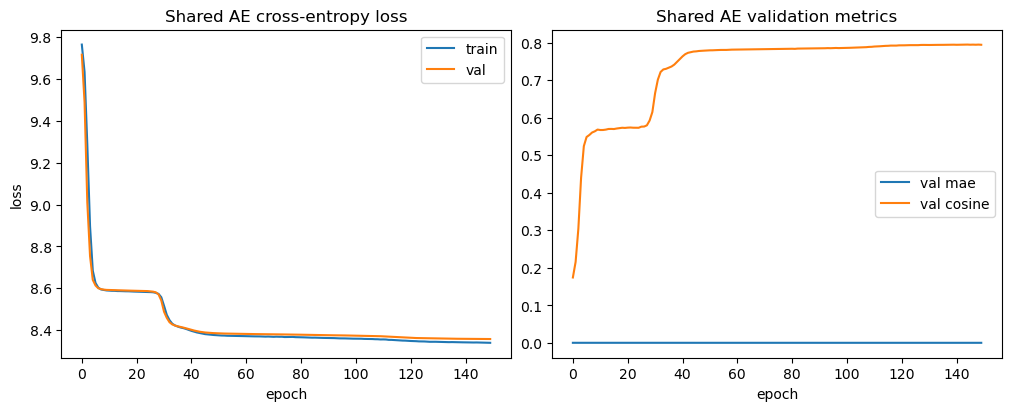

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(shared_ae_history['train_loss'], label='train')
axes[0].plot(shared_ae_history['val_loss'], label='val')
axes[0].set_title('Shared AE cross-entropy loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()

axes[1].plot(shared_ae_history['val_mae'], label='val mae')
axes[1].plot(shared_ae_history['val_cosine'], label='val cosine')
axes[1].set_title('Shared AE validation metrics')
axes[1].set_xlabel('epoch')
axes[1].legend()
export_figure_axes(fig, fallback_prefix='shared_ae_training')
plt.show()


## Per-Sample Splat Fields

Train one AE-neighbor splat field per patient-8 sample. The shared AE stays fixed across tissues, while the number of splats scales with sample size so the primary, lymph-node metastasis, and liver samples are not forced to use the same component budget.


In [14]:
def init_section_splat_model(section_xy: torch.Tensor, section_profiles: torch.Tensor, section_total_counts: torch.Tensor, *, splat_cfg: SplatConfig):
    num_splats = int(splat_cfg.num_splats)
    with torch.no_grad():
        xy = section_xy.to(device)
        profiles = section_profiles.to(device)
        total_counts = section_total_counts.to(device)
        seed_idx = farthest_point_sample_indices(xy, num_splats)
        seed_xy = xy[seed_idx]
        pairwise_dist = torch.cdist(seed_xy, xy)
        neighbor_k = min(section_seed_neighbor_k, xy.shape[0])
        _, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)

        neighbor_profiles = profiles[neighbor_idx]
        neighbor_totals = total_counts[neighbor_idx]
        avg_profiles = neighbor_profiles.mean(dim=1)
        avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
        avg_totals = neighbor_totals.mean(dim=1)
        encoded_seed_latents = shared_profile_autoencoder.encoder(avg_profiles)

    model = AmplitudeSplatField(
        num_splats=splat_cfg.num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=section_profiles.shape[1],
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        top_k_splats=splat_cfg.top_k_splats,
        init_log_amplitude=splat_init_log_amplitude,
    ).to(device)

    with torch.no_grad():
        model.means.copy_(seed_xy)
        model.latents.copy_(encoded_seed_latents)
        model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
        model.log_scales.fill_(splat_cfg.init_log_scale)
        model.rotation.zero_()
        model.opacity_logits.zero_()
        model.decoder.load_state_dict(shared_profile_autoencoder.decoder.state_dict())

    return model


def clone_splat_model(model):
    cloned = AmplitudeSplatField(
        num_splats=model.num_splats,
        latent_dim=model.latent_dim,
        hidden_dim=model.hidden_dim,
        num_genes=model.num_genes,
        init_log_scale=model.init_log_scale,
        kernel_sharpness=model.kernel_sharpness,
        init_log_amplitude=float(model.log_amplitudes.detach().mean().item()),
    ).to(model.means.device)
    cloned.load_state_dict({k: v.detach().clone() for k, v in model.state_dict().items()})
    cloned.eval()
    return cloned


def evaluate_section_splat_model(model, section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: torch.Tensor, batch_size: int = 2048):
    was_training = model.training
    model.eval()
    total_loss = 0.0
    total_mae = 0.0
    total_seen = 0
    xy = section_xy.to(device)
    counts = section_counts.to(device)
    with torch.no_grad():
        for start in range(0, len(split_idx), batch_size):
            idx = split_idx[start:start + batch_size].to(device)
            pred_log_rate = model(xy[idx])
            loss = mae_count_loss(pred_log_rate, counts[idx])
            pred_counts = torch.exp(pred_log_rate)
            mae = (pred_counts - counts[idx]).abs().mean()
            total_loss += loss.item() * len(idx)
            total_mae += mae.item() * len(idx)
            total_seen += len(idx)
    if was_training:
        model.train()
    return {'loss': total_loss / total_seen, 'mae': total_mae / total_seen, 'n': total_seen}


def train_section_splat_model(section_xy: torch.Tensor, section_counts: torch.Tensor, split_idx: dict[str, torch.Tensor], initial_model, *, seed: int, off_tissue_points: torch.Tensor, tissue_mask_tensor: torch.Tensor):
    set_seed(seed)
    model = clone_splat_model(initial_model)
    optimizer = create_amplitude_splat_optimizer(
        model,
        means_lr=section_splat_means_lr,
        log_scales_lr=section_splat_log_scales_lr,
        rotation_lr=section_splat_rotation_lr,
        opacity_lr=section_splat_opacity_lr,
        latents_lr=section_splat_latents_lr,
        log_theta_lr=section_splat_log_theta_lr,
        decoder_lr=section_splat_decoder_lr,
        amplitude_lr=section_splat_amplitude_lr,
    )
    history = {
        'train_joint_loss': [],
        'train_composition_loss': [],
        'train_total_count_loss': [],
        'train_cell_loss': [],
        'train_off_tissue_loss': [],
        'train_center_support_loss': [],
        'val_loss': [],
        'val_mae': [],
        'val_phase': [],
    }
    train_idx = split_idx['train'].to(device)
    val_idx = split_idx['val']
    xy = section_xy.to(device)
    counts = section_counts.to(device)
    off_tissue_points = off_tissue_points.to(device)
    tissue_mask_tensor = tissue_mask_tensor.to(device)
    mae_refine_start_epoch = max(0, int(round((1.0 - section_mae_refine_fraction) * section_splat_epochs)))

    for epoch in range(section_splat_epochs):
        model.train()
        mae_refine_active = epoch >= mae_refine_start_epoch
        perm = train_idx[torch.randperm(len(train_idx), device=device)]
        off_perm = torch.randperm(len(off_tissue_points), device=device) if len(off_tissue_points) > 0 else None
        running = {
            'joint_loss': 0.0,
            'cell_loss': 0.0,
            'composition_loss': 0.0,
            'total_count_loss': 0.0,
            'off_tissue_loss': 0.0,
            'center_support_loss': 0.0,
        }
        steps = 0
        for step, start in enumerate(range(0, len(perm), section_splat_batch_size)):
            idx = perm[start:start + section_splat_batch_size]
            pred_log_rate = model(xy[idx])
            cell_loss = mae_count_loss(pred_log_rate, counts[idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(torch.exp(pred_log_rate), counts[idx])
            total_count_loss = log_total_count_loss(pred_log_rate, counts[idx])
            if off_perm is not None and len(off_tissue_points) > 0:
                off_start = (step * section_off_tissue_batch_size) % len(off_perm)
                off_idx = off_perm[off_start:off_start + section_off_tissue_batch_size]
                if len(off_idx) == 0:
                    off_idx = off_perm[:section_off_tissue_batch_size]
                off_tissue_loss = model.total_intensity(off_tissue_points[off_idx]).mean()
            else:
                off_tissue_loss = pred_log_rate.new_tensor(0.0)
            center_support_loss = (1.0 - sample_tissue_support(model.means, tissue_mask_tensor)).mean()
            loss = (
                section_mae_refine_weight * cell_loss
                + section_composition_loss_weight * composition_loss
                + section_total_count_loss_weight * total_count_loss
                + section_off_tissue_weight * off_tissue_loss
                + section_center_support_weight * center_support_loss
            )
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            with torch.no_grad():
                model.means.clamp_(0.0, 1.0)
                model.log_scales.clamp_(-8.0, -2.0)

            running['joint_loss'] += loss.item()
            running['cell_loss'] += cell_loss.item()
            running['composition_loss'] += composition_loss.item()
            running['total_count_loss'] += total_count_loss.item()
            running['off_tissue_loss'] += off_tissue_loss.item()
            running['center_support_loss'] += center_support_loss.item()
            steps += 1

        train_metrics = {key: value / max(steps, 1) for key, value in running.items()}
        val_summary = evaluate_section_splat_model(model, section_xy, section_counts, val_idx)
        history['train_joint_loss'].append(train_metrics['joint_loss'])
        history['train_composition_loss'].append(train_metrics['composition_loss'])
        history['train_total_count_loss'].append(train_metrics['total_count_loss'])
        history['train_cell_loss'].append(train_metrics['cell_loss'])
        history['train_off_tissue_loss'].append(train_metrics['off_tissue_loss'])
        history['train_center_support_loss'].append(train_metrics['center_support_loss'])
        history['val_loss'].append(val_summary['loss'])
        history['val_mae'].append(val_summary['mae'])
        history['val_phase'].append('mae_refine' if mae_refine_active else 'composition')

    summary = {
        split_name: evaluate_section_splat_model(model, section_xy, section_counts, idx)
        for split_name, idx in split_idx.items()
    }
    return {'model': model, 'history': history, 'summary': summary}


In [15]:
section_splat_results = {}
splat_field_summary = {}

for sample_idx, (label, bundle) in enumerate(sample_bundles.items()):
    split_idx = sample_splits[label]
    splat_cfg = bundle['splat_cfg']
    num_splats = int(splat_cfg.num_splats)
    init_model = init_section_splat_model(
        bundle['xy_norm'],
        bundle['profiles'],
        bundle['total_counts'],
        splat_cfg=splat_cfg,
    )
    result = train_section_splat_model(
        bundle['xy_norm'],
        bundle['counts'],
        split_idx,
        init_model,
        seed=random_seed + 700 + sample_idx * 100,
        off_tissue_points=bundle['off_tissue_points'],
        tissue_mask_tensor=bundle['tissue_mask_tensor'],
    )
    section_splat_results[label] = result
    splat_field_summary[label] = {
        'sample_name': bundle['sample_name'],
        'origin': bundle['origin'],
        'num_splats': num_splats,
        'AE-neighbor splat': result['summary'],
    }

print('Splat field summary')
print(format_for_display(splat_field_summary))


Splat field summary
{'primary': {'sample_name': 'IU_PDA_T8', 'origin': 'Pancreas', 'num_splats': 472, 'AE-neighbor splat': {'train': {'loss': 0.1466, 'mae': 0.1466, 'n': 3023}, 'val': {'loss': 0.1402, 'mae': 0.1402, 'n': 378}, 'test': {'loss': 0.1645, 'mae': 0.1645, 'n': 378}}}, 'lymph_node_met': {'sample_name': 'IU_PDA_LNM8', 'origin': 'Lymph node', 'num_splats': 426, 'AE-neighbor splat': {'train': {'loss': 0.1981, 'mae': 0.1981, 'n': 2725}, 'val': {'loss': 0.2047, 'mae': 0.2047, 'n': 341}, 'test': {'loss': 0.2138, 'mae': 0.2138, 'n': 341}}}, 'liver_sample': {'sample_name': 'IU_PDA_HM8', 'origin': 'Liver', 'num_splats': 504, 'AE-neighbor splat': {'train': {'loss': 0.08928, 'mae': 0.08928, 'n': 3226}, 'val': {'loss': 0.09295, 'mae': 0.09295, 'n': 403}, 'test': {'loss': 0.09288, 'mae': 0.09288, 'n': 403}}}}


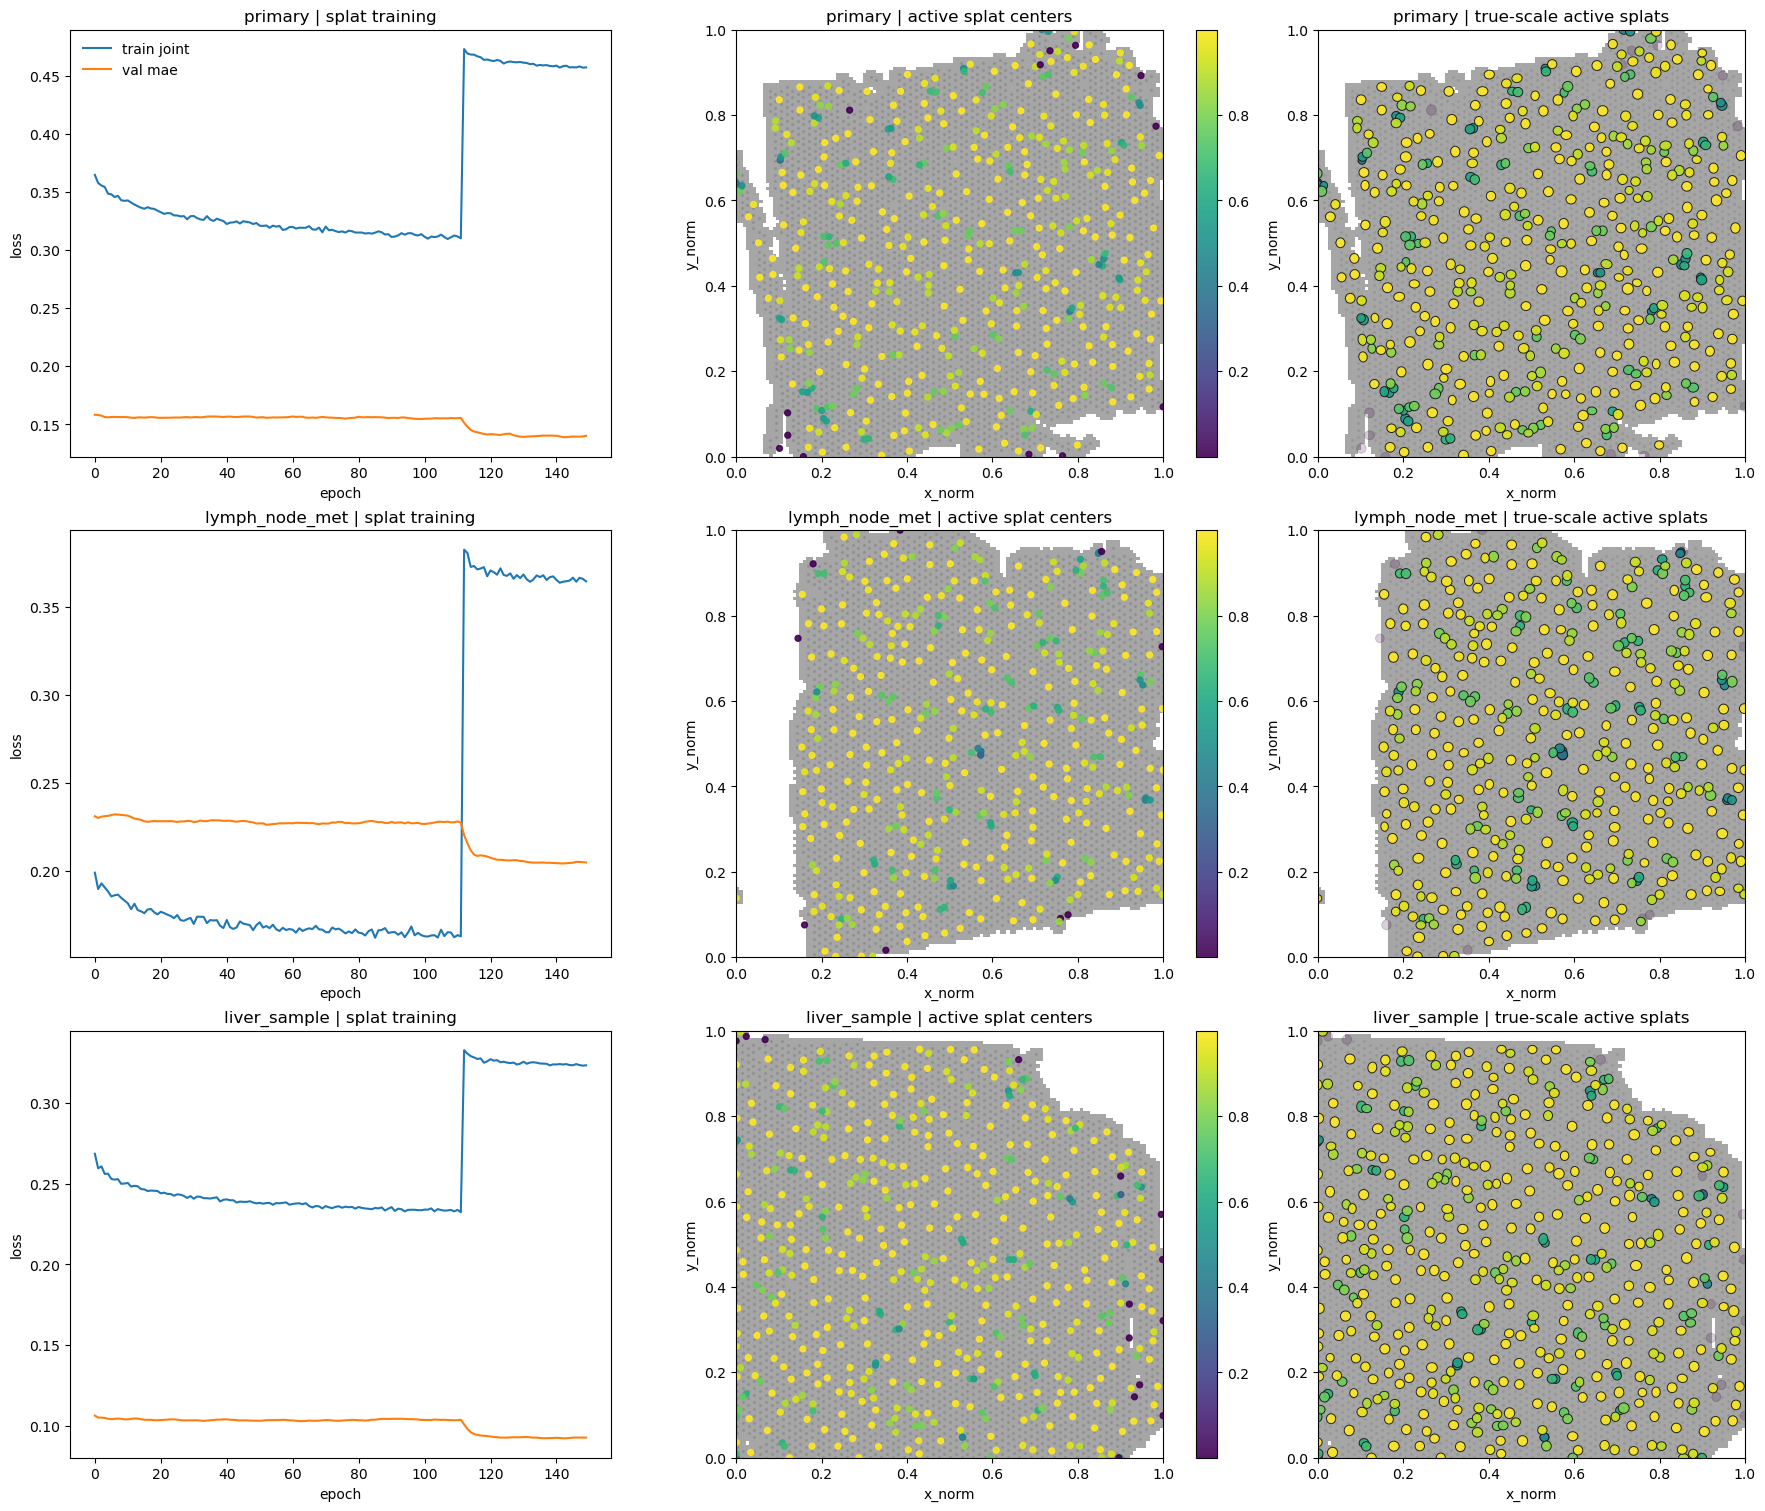

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15), constrained_layout=True)
for row, (label, bundle) in enumerate(sample_bundles.items()):
    result = section_splat_results[label]
    history = result['history']
    model = result['model']
    mask_np = bundle['tissue_mask_tensor'].squeeze().numpy()
    xy_norm = bundle['xy_norm']
    xy_norm_np = xy_norm.numpy()

    with torch.no_grad():
        weights = compute_splat_weights(model, xy_norm.to(device))
        mean_usage = weights.mean(dim=0).detach().cpu().numpy()
        full_weights = weights.detach().cpu().numpy()
        means_np = model.means.detach().cpu().numpy()
        scales_xy_np = torch.exp(model.log_scales).detach().cpu().numpy()
        rotation_np = model.rotation.detach().cpu().numpy().reshape(-1)

    active_idx = np.flatnonzero(mean_usage > 1e-4)
    overlap_usage = np.zeros(len(mean_usage), dtype=np.float64)
    overlap_counts = np.zeros(len(mean_usage), dtype=np.int64)
    for splat_idx in active_idx:
        dx = xy_norm_np[:, 0] - means_np[splat_idx, 0]
        dy = xy_norm_np[:, 1] - means_np[splat_idx, 1]
        theta = -float(rotation_np[splat_idx])
        c, s = np.cos(theta), np.sin(theta)
        x_rot = c * dx - s * dy
        y_rot = s * dx + c * dy
        sx = max(float(scales_xy_np[splat_idx, 0]), 1e-8)
        sy = max(float(scales_xy_np[splat_idx, 1]), 1e-8)
        inside_mask = (x_rot / sx) ** 2 + (y_rot / sy) ** 2 <= 1.0
        overlap_counts[splat_idx] = int(inside_mask.sum())
        if inside_mask.any():
            overlap_usage[splat_idx] = float(full_weights[inside_mask, splat_idx].mean())
        else:
            overlap_usage[splat_idx] = float(mean_usage[splat_idx])

    axes[row, 0].plot(history['train_joint_loss'], label='train joint')
    axes[row, 0].plot(history['val_loss'], label='val mae')
    axes[row, 0].set_title(f'{label} | splat training')
    axes[row, 0].set_xlabel('epoch')
    axes[row, 0].set_ylabel('loss')
    if row == 0:
        axes[row, 0].legend(frameon=False)

    axes[row, 1].imshow(mask_np, origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.35)
    axes[row, 1].scatter(xy_norm_np[:, 0], xy_norm_np[:, 1], s=2, alpha=0.08, color='black')
    if len(active_idx):
        sc = axes[row, 1].scatter(
            means_np[active_idx, 0],
            means_np[active_idx, 1],
            s=18.0,
            c=overlap_usage[active_idx],
            cmap='viridis',
            alpha=0.9,
        )
        fig.colorbar(sc, ax=axes[row, 1], fraction=0.046, pad=0.04)
    axes[row, 1].set_title(f'{label} | active splat centers')
    axes[row, 1].set_xlim(0, 1)
    axes[row, 1].set_ylim(0, 1)
    axes[row, 1].set_aspect('equal')
    axes[row, 1].set_xlabel('x_norm')
    axes[row, 1].set_ylabel('y_norm')

    axes[row, 2].imshow(mask_np, origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.35)
    axes[row, 2].scatter(xy_norm_np[:, 0], xy_norm_np[:, 1], s=2, alpha=0.05, color='black')
    draw_order = np.argsort(overlap_usage[active_idx]) if len(active_idx) else np.array([], dtype=np.int64)
    overlap_max = float(overlap_usage[active_idx].max()) if len(active_idx) else 1.0
    for local_pos in draw_order:
        splat_idx = active_idx[local_pos]
        ellipse = Ellipse(
            xy=means_np[splat_idx],
            width=2.0 * scales_xy_np[splat_idx, 0],
            height=2.0 * scales_xy_np[splat_idx, 1],
            angle=float(np.degrees(rotation_np[splat_idx])),
            facecolor=plt.cm.viridis(min(1.0, max(0.0, overlap_usage[splat_idx] / (overlap_max + 1e-8)))),
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * overlap_usage[splat_idx], 0.18, 0.92)),
        )
        axes[row, 2].add_patch(ellipse)
    axes[row, 2].set_title(f'{label} | true-scale active splats')
    axes[row, 2].set_xlim(0, 1)
    axes[row, 2].set_ylim(0, 1)
    axes[row, 2].set_aspect('equal')
    axes[row, 2].set_xlabel('x_norm')
    axes[row, 2].set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='splat_training_and_layout')
plt.show()


## Splat Utilization Diagnostics

Summarize how many splats are actually active and how strongly they are used on the spots they geometrically cover. This is the quickest way to tell whether the current component budget is too large for any of the three tissues.


In [17]:
utilization_query_cap = 2048
coverage_eval_batch_size = 4096
active_mean_usage_threshold = 1e-4
covered_usage_threshold = 0.01


def coverage_mask_for_points(model, points: torch.Tensor, ellipse_threshold: float = 1.0) -> torch.Tensor:
    points = points.to(model.means.device)
    means = model.means
    scales = torch.exp(model.log_scales).clamp_min(1e-8)
    theta = model.rotation.squeeze(-1)

    dx = points[:, None, 0] - means[None, :, 0]
    dy = points[:, None, 1] - means[None, :, 1]
    cos_t = torch.cos(theta)[None, :]
    sin_t = torch.sin(theta)[None, :]
    x_local = cos_t * dx + sin_t * dy
    y_local = -sin_t * dx + cos_t * dy
    norm_sq = (x_local / scales[None, :, 0]) ** 2 + (y_local / scales[None, :, 1]) ** 2
    return norm_sq <= float(ellipse_threshold ** 2)


def summarize_covered_usage(model, features: torch.Tensor, active_mask_np: np.ndarray, usage_threshold: float = covered_usage_threshold, batch_size: int = coverage_eval_batch_size):
    num_splats = model.num_splats
    covered_count = np.zeros(num_splats, dtype=np.int64)
    covered_usage_sum = np.zeros(num_splats, dtype=np.float64)
    covered_usage_values = [[] for _ in range(num_splats)]
    covered_usage_gt_thresh = np.zeros(num_splats, dtype=np.int64)
    covered_top1 = np.zeros(num_splats, dtype=np.int64)

    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            batch_points = features[start:start + batch_size].to(device)
            batch_weights = compute_splat_weights(model, batch_points)
            batch_top1 = batch_weights.argmax(dim=1)
            batch_cover = coverage_mask_for_points(model, batch_points)

            batch_cover_np = batch_cover.detach().cpu().numpy()
            batch_weights_np = batch_weights.detach().cpu().numpy()
            batch_top1_np = batch_top1.detach().cpu().numpy()

            for splat_idx in range(num_splats):
                covered = batch_cover_np[:, splat_idx]
                if not np.any(covered):
                    continue
                usage_vals = batch_weights_np[covered, splat_idx]
                covered_count[splat_idx] += int(covered.sum())
                covered_usage_sum[splat_idx] += float(usage_vals.sum())
                covered_usage_values[splat_idx].append(usage_vals)
                covered_usage_gt_thresh[splat_idx] += int(np.sum(usage_vals > usage_threshold))
                covered_top1[splat_idx] += int(np.sum(batch_top1_np[covered] == splat_idx))

    covered_mean = np.full(num_splats, np.nan, dtype=np.float64)
    covered_median = np.full(num_splats, np.nan, dtype=np.float64)
    covered_frac_gt = np.full(num_splats, np.nan, dtype=np.float64)
    covered_frac_top1 = np.full(num_splats, np.nan, dtype=np.float64)

    valid_mask = covered_count > 0
    for splat_idx in np.flatnonzero(valid_mask):
        vals = np.concatenate(covered_usage_values[splat_idx]) if covered_usage_values[splat_idx] else np.empty(0, dtype=np.float64)
        if len(vals) == 0:
            continue
        covered_mean[splat_idx] = covered_usage_sum[splat_idx] / float(covered_count[splat_idx])
        covered_median[splat_idx] = float(np.median(vals))
        covered_frac_gt[splat_idx] = covered_usage_gt_thresh[splat_idx] / float(covered_count[splat_idx])
        covered_frac_top1[splat_idx] = covered_top1[splat_idx] / float(covered_count[splat_idx])

    active_and_valid = active_mask_np & valid_mask
    return {
        'covered_count': covered_count,
        'covered_mean_usage': covered_mean,
        'covered_median_usage': covered_median,
        'covered_fraction_gt_1pct': covered_frac_gt,
        'covered_fraction_top1': covered_frac_top1,
        'active_and_valid_mask': active_and_valid,
    }


splat_utilization_summary = {}
for label, bundle in sample_bundles.items():
    model = section_splat_results[label]['model']
    features = bundle['xy_norm']
    query_count = min(utilization_query_cap, len(features))
    with torch.no_grad():
        query_idx = torch.randperm(len(features), device=features.device)[:query_count]
        query_points = features[query_idx].to(device)
        weights = compute_splat_weights(model, query_points)
        usage = usage_statistics(weights)
        mean_usage_np = weights.mean(dim=0).detach().cpu().numpy()
        peak_usage_np = weights.max(dim=0).values.detach().cpu().numpy()
        active_mask_np = mean_usage_np > active_mean_usage_threshold

        means_np = model.means.detach().cpu().numpy()
        pairwise = np.linalg.norm(means_np[:, None, :] - means_np[None, :, :], axis=-1)
        pairwise[pairwise == 0.0] = np.inf
        nearest_center_dist = pairwise.min(axis=1)
        active_nearest = nearest_center_dist[active_mask_np] if np.any(active_mask_np) else np.array([], dtype=np.float64)

    covered_usage = summarize_covered_usage(model, features, active_mask_np)
    active_valid = covered_usage['active_and_valid_mask']

    splat_utilization_summary[label] = {
        'num_splats': int(model.num_splats),
        'active_splats': int(active_mask_np.sum()),
        'active_fraction_gt_1e4': float(usage['active_fraction']),
        'dominant_splat_fraction_gt_5pct': float(usage['dominant_fraction']),
        'avg_splats_per_query_gt_1pct': float(usage['avg_splats_per_query_gt_1pct']),
        'mean_usage_active': float(np.mean(mean_usage_np[active_mask_np])) if np.any(active_mask_np) else float('nan'),
        'median_peak_usage_active': float(np.median(peak_usage_np[active_mask_np])) if np.any(active_mask_np) else float('nan'),
        'median_nearest_center_distance_active': float(np.median(active_nearest)) if len(active_nearest) else float('nan'),
        'mean_covered_spot_count_active': float(np.mean(covered_usage['covered_count'][active_valid])) if np.any(active_valid) else float('nan'),
        'median_covered_spot_count_active': float(np.median(covered_usage['covered_count'][active_valid])) if np.any(active_valid) else float('nan'),
        'mean_usage_covered_active': float(np.nanmean(covered_usage['covered_mean_usage'][active_valid])) if np.any(active_valid) else float('nan'),
        'median_usage_covered_active': float(np.nanmedian(covered_usage['covered_median_usage'][active_valid])) if np.any(active_valid) else float('nan'),
        'fraction_covered_usage_gt_1pct_active': float(np.nanmean(covered_usage['covered_fraction_gt_1pct'][active_valid])) if np.any(active_valid) else float('nan'),
        'fraction_covered_top1_active': float(np.nanmean(covered_usage['covered_fraction_top1'][active_valid])) if np.any(active_valid) else float('nan'),
    }

print('Splat utilization summary')
print(format_for_display(splat_utilization_summary))


Splat utilization summary
{'primary': {'num_splats': 472, 'active_splats': 470, 'active_fraction_gt_1e4': 0.9958, 'dominant_splat_fraction_gt_5pct': 0.9958, 'avg_splats_per_query_gt_1pct': 1.782, 'mean_usage_active': 0.002116, 'median_peak_usage_active': 0.9987, 'median_nearest_center_distance_active': 0.02502, 'mean_covered_spot_count_active': 1.785, 'median_covered_spot_count_active': 2.0, 'mean_usage_covered_active': 0.9081, 'median_usage_covered_active': 0.983, 'fraction_covered_usage_gt_1pct_active': 1.0, 'fraction_covered_top1_active': 0.9627}, 'lymph_node_met': {'num_splats': 426, 'active_splats': 422, 'active_fraction_gt_1e4': 0.9906, 'dominant_splat_fraction_gt_5pct': 0.9977, 'avg_splats_per_query_gt_1pct': 1.759, 'mean_usage_active': 0.00236, 'median_peak_usage_active': 0.9987, 'median_nearest_center_distance_active': 0.02582, 'mean_covered_spot_count_active': 1.786, 'median_covered_spot_count_active': 2.0, 'mean_usage_covered_active': 0.9126, 'median_usage_covered_active': 0

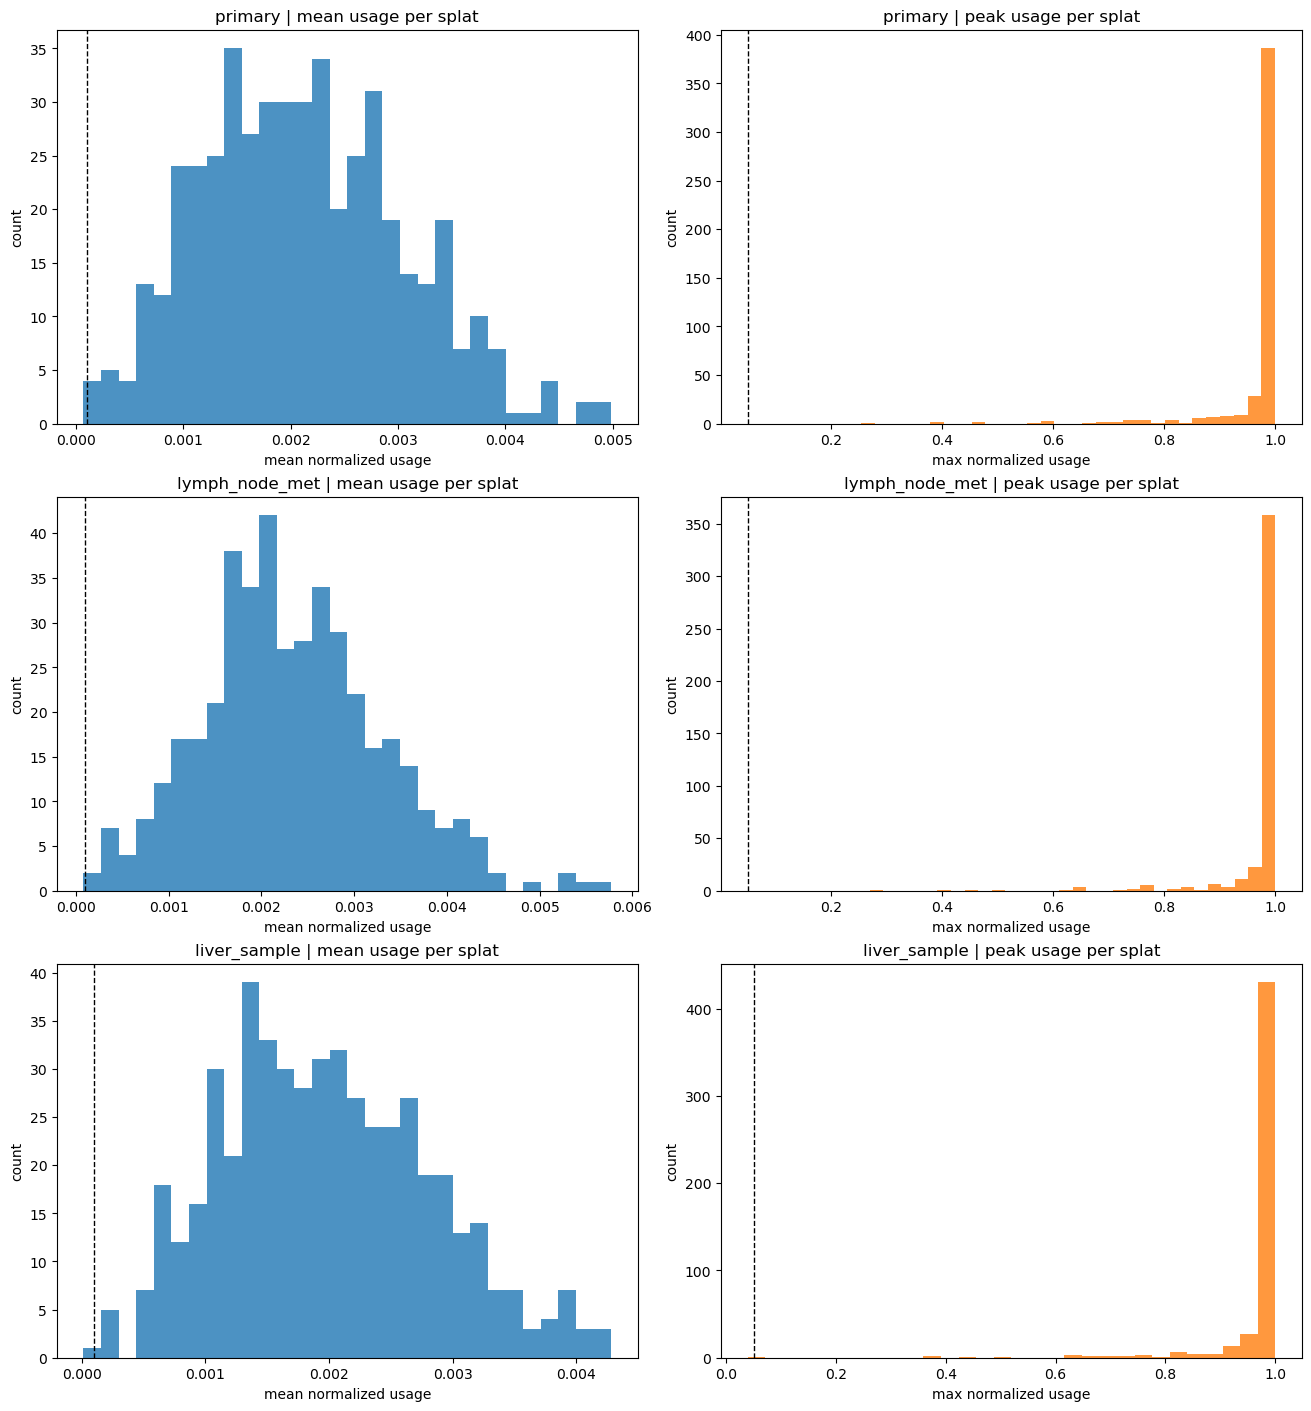

In [18]:
fig, axes = plt.subplots(3, 2, figsize=(13, 14), constrained_layout=True)
for row, (label, bundle) in enumerate(sample_bundles.items()):
    model = section_splat_results[label]['model']
    features = bundle['xy_norm'].to(device)
    with torch.no_grad():
        weights = compute_splat_weights(model, features)
        mean_usage = weights.mean(dim=0).detach().cpu().numpy()
        peak_usage = weights.max(dim=0).values.detach().cpu().numpy()

    axes[row, 0].hist(mean_usage, bins=30, color='tab:blue', alpha=0.8)
    axes[row, 0].axvline(active_mean_usage_threshold, color='black', linestyle='--', linewidth=1)
    axes[row, 0].set_title(f'{label} | mean usage per splat')
    axes[row, 0].set_xlabel('mean normalized usage')
    axes[row, 0].set_ylabel('count')

    axes[row, 1].hist(peak_usage, bins=30, color='tab:orange', alpha=0.8)
    axes[row, 1].axvline(0.05, color='black', linestyle='--', linewidth=1)
    axes[row, 1].set_title(f'{label} | peak usage per splat')
    axes[row, 1].set_xlabel('max normalized usage')
    axes[row, 1].set_ylabel('count')

export_figure_axes(fig, fallback_prefix='splat_usage')
plt.show()


## Primary Tumor-Rich Spot Definition

Start with the provided spot annotations in `IU_PDA_T8` rather than decoded splat programs. The strict tumor-rich reference uses spots whose `first_type` is `Tumor Epithelial cells`, excludes `reject` spots, and keeps adjacent tumor-labeled spots as a looser tumor-interface set for later comparison.


In [19]:
primary_bundle = sample_bundles['primary']
primary_obs = primary_bundle['adata'].obs.copy()

tumor_label = 'Tumor Epithelial cells'
strict_tumor_rich_mask = (
    primary_obs['first_type'].astype(str).eq(tumor_label)
    & ~primary_obs['spot_class'].astype(str).eq('reject')
)

tumor_interface_mask = (
    primary_obs['first_type'].astype(str).eq(tumor_label)
    | primary_obs['second_type'].astype(str).eq(tumor_label)
) & ~primary_obs['spot_class'].astype(str).eq('reject')

non_tumor_control_mask = (
    ~primary_obs['first_type'].astype(str).eq(tumor_label)
    & ~primary_obs['second_type'].astype(str).eq(tumor_label)
    & ~primary_obs['spot_class'].astype(str).eq('reject')
)

primary_reference_regions = {
    'strict_tumor_rich_mask': strict_tumor_rich_mask.to_numpy(),
    'tumor_interface_mask': tumor_interface_mask.to_numpy(),
    'non_tumor_control_mask': non_tumor_control_mask.to_numpy(),
    'strict_tumor_rich_indices': np.flatnonzero(strict_tumor_rich_mask.to_numpy()),
    'tumor_interface_indices': np.flatnonzero(tumor_interface_mask.to_numpy()),
    'non_tumor_control_indices': np.flatnonzero(non_tumor_control_mask.to_numpy()),
}

primary_tumor_reference_summary = {
    'sample_name': primary_bundle['sample_name'],
    'n_spots_total': int(primary_bundle['adata'].n_obs),
    'n_strict_tumor_rich': int(strict_tumor_rich_mask.sum()),
    'fraction_strict_tumor_rich': float(strict_tumor_rich_mask.mean()),
    'n_tumor_interface': int(tumor_interface_mask.sum()),
    'fraction_tumor_interface': float(tumor_interface_mask.mean()),
    'n_non_tumor_control': int(non_tumor_control_mask.sum()),
    'fraction_non_tumor_control': float(non_tumor_control_mask.mean()),
    'strict_tumor_top_second_type': primary_obs.loc[strict_tumor_rich_mask, 'second_type'].astype(str).value_counts().head(10).to_dict(),
    'non_tumor_control_top_first_type': primary_obs.loc[non_tumor_control_mask, 'first_type'].astype(str).value_counts().head(10).to_dict(),
}

print('Primary tumor-rich spot summary')
print(format_for_display(primary_tumor_reference_summary))


Primary tumor-rich spot summary
{'sample_name': 'IU_PDA_T8', 'n_spots_total': 3779, 'n_strict_tumor_rich': 2577, 'fraction_strict_tumor_rich': 0.6819, 'n_tumor_interface': 3411, 'fraction_tumor_interface': 0.9026, 'n_non_tumor_control': 345, 'fraction_non_tumor_control': 0.09129, 'strict_tumor_top_second_type': {'myCAF': 1344, 'Normal Epithelial cells': 519, 'SPP1-TAM': 253, 'iCAF': 167, 'Proliferative T cells': 129, 'B cells': 66, 'FCN1-TAM': 51, 'C1Q-TAM': 18, 'DCs': 13, 'CD4+ cells': 6}, 'non_tumor_control_top_first_type': {'myCAF': 199, 'Normal Epithelial cells': 79, 'SPP1-TAM': 29, 'B cells': 28, 'C1Q-TAM': 4, 'iCAF': 4, 'FCN1-TAM': 1, 'DCs': 1}}


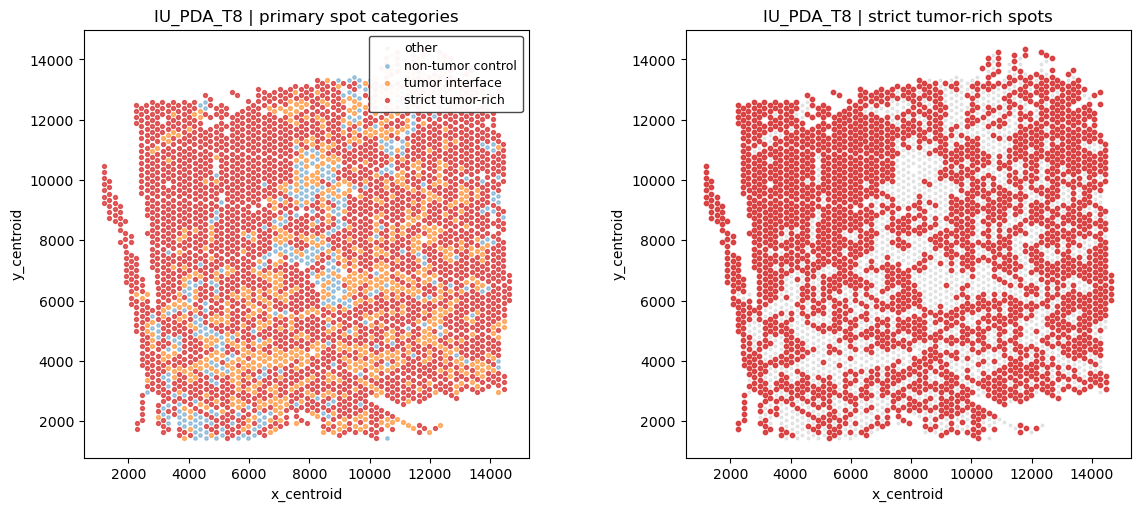

In [20]:
xy_raw = primary_bundle['xy_raw']
strict_mask = primary_reference_regions['strict_tumor_rich_mask']
interface_only_mask = primary_reference_regions['tumor_interface_mask'] & ~strict_mask
control_mask = primary_reference_regions['non_tumor_control_mask']
other_mask = ~(strict_mask | interface_only_mask | control_mask)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

axes[0].scatter(xy_raw[other_mask, 0], xy_raw[other_mask, 1], s=4, alpha=0.15, color='lightgray', label='other')
axes[0].scatter(xy_raw[control_mask, 0], xy_raw[control_mask, 1], s=6, alpha=0.35, color='tab:blue', label='non-tumor control')
axes[0].scatter(xy_raw[interface_only_mask, 0], xy_raw[interface_only_mask, 1], s=8, alpha=0.55, color='tab:orange', label='tumor interface')
axes[0].scatter(xy_raw[strict_mask, 0], xy_raw[strict_mask, 1], s=8, alpha=0.7, color='tab:red', label='strict tumor-rich')
axes[0].set_aspect('equal')
axes[0].set_title('IU_PDA_T8 | primary spot categories')
axes[0].set_xlabel('x_centroid')
axes[0].set_ylabel('y_centroid')
axes[0].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=9, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

axes[1].scatter(xy_raw[:, 0], xy_raw[:, 1], s=4, alpha=0.08, color='black')
axes[1].scatter(xy_raw[strict_mask, 0], xy_raw[strict_mask, 1], s=10, alpha=0.8, color='tab:red')
axes[1].set_aspect('equal')
axes[1].set_title('IU_PDA_T8 | strict tumor-rich spots')
axes[1].set_xlabel('x_centroid')
axes[1].set_ylabel('y_centroid')

export_figure_axes(fig, fallback_prefix='primary_spot_categories')
plt.show()


## Primary Pancreatic Program Bank

Treat `IU_PDA_T8` as the source pancreas sample, but do not prefilter for tumor-associated splats. Instead, use all active primary splats to define a bank of pancreatic program families, then ask which of those families transfer into the lymph-node and liver samples and align with downstream tumor annotations.


In [21]:
primary_model = section_splat_results['primary']['model']
primary_features = primary_bundle['xy_norm'].to(device)
primary_gene_names = np.asarray(primary_bundle['gene_names'], dtype=object)
primary_tumor_spot_mask = primary_obs['first_type'].astype(str).eq(tumor_label).to_numpy()
primary_tumor_interface_spot_mask = (
    primary_obs['first_type'].astype(str).eq(tumor_label)
    | primary_obs['second_type'].astype(str).eq(tumor_label)
).to_numpy()
primary_reject_mask = primary_obs['spot_class'].astype(str).eq('reject').to_numpy()
primary_reference_spot_mask = primary_tumor_spot_mask & ~primary_reject_mask

with torch.no_grad():
    primary_weights = compute_splat_weights(primary_model, primary_features).detach().cpu()
    primary_composition = primary_model.splat_composition().detach().cpu()
    primary_amplitudes = primary_model.splat_amplitudes().detach().cpu().squeeze(-1)
    primary_coverage_mask = coverage_mask_for_points(primary_model, primary_features).detach().cpu().numpy()

primary_weights_np = primary_weights.numpy()
reference_mask_np = primary_reference_spot_mask.astype(bool)
non_reference_mask_np = (~primary_reference_spot_mask) & (~primary_reject_mask)
primary_mean_usage = primary_weights_np.mean(axis=0)
primary_peak_usage = primary_weights_np.max(axis=0)
reference_weight_sum = primary_weights_np[reference_mask_np].sum(axis=0) if reference_mask_np.any() else np.zeros(primary_model.num_splats, dtype=np.float64)
all_weight_sum = primary_weights_np[~primary_reject_mask].sum(axis=0) if (~primary_reject_mask).any() else np.ones(primary_model.num_splats, dtype=np.float64)
reference_weight_fraction = reference_weight_sum / np.clip(all_weight_sum, 1e-8, None)
reference_weight_mean = primary_weights_np[reference_mask_np].mean(axis=0) if reference_mask_np.any() else np.zeros(primary_model.num_splats, dtype=np.float64)
non_reference_weight_mean = primary_weights_np[non_reference_mask_np].mean(axis=0) if non_reference_mask_np.any() else np.zeros(primary_model.num_splats, dtype=np.float64)
reference_enrichment = reference_weight_mean - non_reference_weight_mean
covered_spot_count = primary_coverage_mask.sum(axis=0).astype(np.int64)
covered_tumor_purity = np.full(primary_model.num_splats, np.nan, dtype=np.float64)
covered_tumor_interface_purity = np.full(primary_model.num_splats, np.nan, dtype=np.float64)
for splat_idx in np.flatnonzero(covered_spot_count > 0):
    covered = primary_coverage_mask[:, splat_idx]
    covered_tumor_purity[splat_idx] = float(primary_tumor_spot_mask[covered].mean())
    covered_tumor_interface_purity[splat_idx] = float(primary_tumor_interface_spot_mask[covered].mean())

primary_active_mask = primary_mean_usage > active_mean_usage_threshold
active_primary_splat_indices = np.flatnonzero(primary_active_mask)
active_order = active_primary_splat_indices[np.lexsort((
    primary_peak_usage[active_primary_splat_indices],
    primary_mean_usage[active_primary_splat_indices],
))[::-1]]

def top_gene_labels(comp_row: np.ndarray, gene_names: np.ndarray, k: int = 10):
    idx = np.argsort(comp_row)[::-1][:k]
    return [str(gene_names[i]) for i in idx]

primary_active_examples = {}
for rank, splat_idx in enumerate(active_order[:10]):
    primary_active_examples[f'splat_{rank}'] = {
        'splat_index': int(splat_idx),
        'mean_usage': float(primary_mean_usage[splat_idx]),
        'peak_usage': float(primary_peak_usage[splat_idx]),
        'reference_weight_fraction': float(reference_weight_fraction[splat_idx]),
        'reference_enrichment': float(reference_enrichment[splat_idx]),
        'covered_spot_count': int(covered_spot_count[splat_idx]),
        'covered_tumor_purity': float(covered_tumor_purity[splat_idx]) if np.isfinite(covered_tumor_purity[splat_idx]) else float('nan'),
        'covered_tumor_interface_purity': float(covered_tumor_interface_purity[splat_idx]) if np.isfinite(covered_tumor_interface_purity[splat_idx]) else float('nan'),
        'amplitude': float(primary_amplitudes[splat_idx].item()),
        'top_genes': top_gene_labels(primary_composition[splat_idx].numpy(), primary_gene_names, k=10),
    }

primary_active_splat_summary = {
    'n_primary_spots': int(primary_bundle['adata'].n_obs),
    'n_tumor_first_spots': int(reference_mask_np.sum()),
    'tumor_first_spot_fraction': float(reference_mask_np.mean()),
    'active_primary_splats': int(primary_active_mask.sum()),
    'active_mean_usage_threshold': float(active_mean_usage_threshold),
    'median_mean_usage_active': float(np.median(primary_mean_usage[primary_active_mask])) if np.any(primary_active_mask) else float('nan'),
    'median_peak_usage_active': float(np.median(primary_peak_usage[primary_active_mask])) if np.any(primary_active_mask) else float('nan'),
    'median_reference_weight_fraction_active': float(np.median(reference_weight_fraction[primary_active_mask])) if np.any(primary_active_mask) else float('nan'),
    'median_reference_enrichment_active': float(np.median(reference_enrichment[primary_active_mask])) if np.any(primary_active_mask) else float('nan'),
    'median_covered_spot_count_active': float(np.median(covered_spot_count[primary_active_mask])) if np.any(primary_active_mask) else float('nan'),
    'median_covered_tumor_purity_active': float(np.nanmedian(covered_tumor_purity[primary_active_mask])) if np.any(primary_active_mask) else float('nan'),
    'median_covered_tumor_interface_purity_active': float(np.nanmedian(covered_tumor_interface_purity[primary_active_mask])) if np.any(primary_active_mask) else float('nan'),
}

print('Primary active pancreatic splat summary')
print(format_for_display(primary_active_splat_summary))
print('Example active pancreatic splats')
print(format_for_display(primary_active_examples))


Primary active pancreatic splat summary
{'n_primary_spots': 3779, 'n_tumor_first_spots': 2577, 'tumor_first_spot_fraction': 0.6819, 'active_primary_splats': 471, 'active_mean_usage_threshold': 0.0001, 'median_mean_usage_active': 0.002053, 'median_peak_usage_active': 0.9994, 'median_reference_weight_fraction_active': 0.7488, 'median_reference_enrichment_active': 0.0004867, 'median_covered_spot_count_active': 2.0, 'median_covered_tumor_purity_active': 1.0, 'median_covered_tumor_interface_purity_active': 1.0}
Example active pancreatic splats
{'splat_0': {'splat_index': 360, 'mean_usage': 0.004986, 'peak_usage': 1.0, 'reference_weight_fraction': 0.3383, 'reference_enrichment': -0.008102, 'covered_spot_count': 2, 'covered_tumor_purity': 0.0, 'covered_tumor_interface_purity': 1.0, 'amplitude': 726.3, 'top_genes': ['FN1', 'FTL', 'COL1A2', 'UBC', 'ACTB', 'COL1A1', 'TMSB4X', 'COL3A1', 'S100A6', 'MT2A']}, 'splat_1': {'splat_index': 166, 'mean_usage': 0.004849, 'peak_usage': 1.0, 'reference_weigh

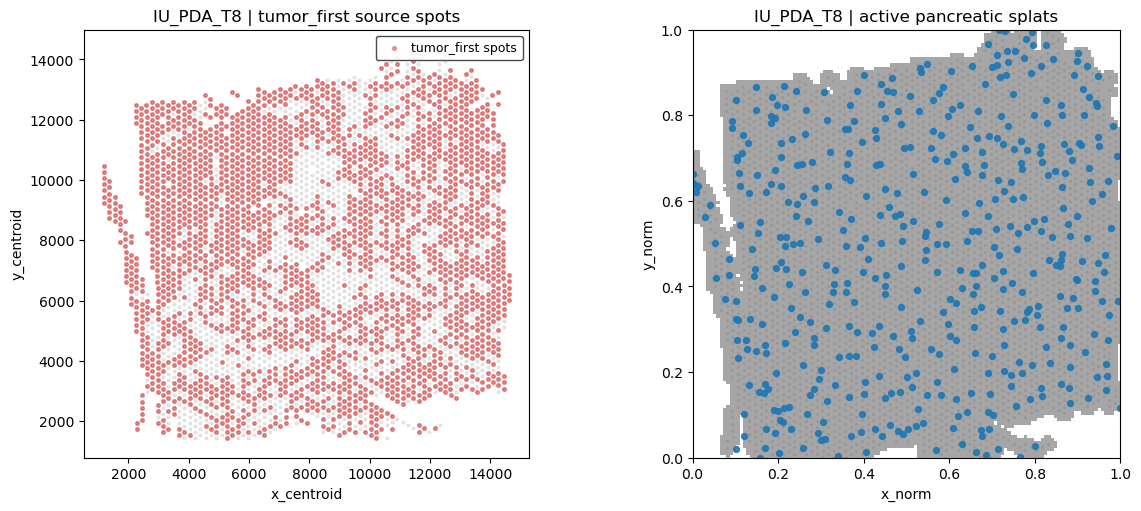

In [22]:
primary_means_np = primary_model.means.detach().cpu().numpy()
primary_xy_raw = primary_bundle['xy_raw']
primary_xy_norm_np = primary_bundle['xy_norm'].numpy()
selected_mask = np.zeros(primary_model.num_splats, dtype=bool)
selected_mask[active_primary_splat_indices] = True

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

axes[0].scatter(primary_xy_raw[:, 0], primary_xy_raw[:, 1], s=4, alpha=0.08, color='black')
axes[0].scatter(primary_xy_raw[reference_mask_np, 0], primary_xy_raw[reference_mask_np, 1], s=7, alpha=0.45, color='tab:red', label='tumor_first spots')
axes[0].set_aspect('equal')
axes[0].set_title('IU_PDA_T8 | tumor_first source spots')
axes[0].set_xlabel('x_centroid')
axes[0].set_ylabel('y_centroid')
axes[0].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=9, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

axes[1].imshow(primary_bundle['tissue_mask_tensor'].squeeze().numpy(), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.35)
axes[1].scatter(primary_xy_norm_np[:, 0], primary_xy_norm_np[:, 1], s=2, alpha=0.05, color='black')
axes[1].scatter(primary_means_np[~selected_mask, 0], primary_means_np[~selected_mask, 1], s=10, alpha=0.12, color='lightgray')
axes[1].scatter(primary_means_np[selected_mask, 0], primary_means_np[selected_mask, 1], s=18, alpha=0.9, color='tab:blue')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_aspect('equal')
axes[1].set_title('IU_PDA_T8 | active pancreatic splats')
axes[1].set_xlabel('x_norm')
axes[1].set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='active_pancreatic_splats')
plt.show()


## Primary Pancreatic Program Families

Group all active primary splats by decoded program similarity. This removes the primary tumor-selection gate and asks a broader question: which recurring pancreatic programs, learned directly from the source tissue, transfer coherently into the lymph-node and liver samples?


In [23]:
primary_family_cosine_threshold = 0.95
max_primary_families_report = 8
primary_family_min_size = 3

active_primary_comp = primary_composition[active_primary_splat_indices]
active_primary_comp = active_primary_comp / active_primary_comp.norm(dim=1, keepdim=True).clamp_min(1e-8)
primary_pairwise_cosine = (active_primary_comp @ active_primary_comp.T).detach().cpu().numpy()

remaining = list(range(len(active_primary_splat_indices)))
primary_program_families = []
while remaining:
    seed_local_idx = remaining[0]
    seed_sim = primary_pairwise_cosine[seed_local_idx]
    family_local = [idx for idx in remaining if seed_sim[idx] >= primary_family_cosine_threshold]
    primary_program_families.append(family_local)
    remaining = [idx for idx in remaining if idx not in family_local]

all_family_records = []
active_primary_family_ids = np.full(len(active_primary_splat_indices), -1, dtype=np.int64)
for family_id, family_local in enumerate(primary_program_families):
    for local_idx in family_local:
        active_primary_family_ids[local_idx] = family_id

    family_splat_idx = active_primary_splat_indices[family_local]
    family_comp = primary_composition[family_splat_idx].mean(dim=0).detach().cpu().numpy()
    family_gene_labels = top_gene_labels(family_comp, primary_gene_names, k=10)
    family_usage = primary_mean_usage[family_splat_idx]
    family_peak = primary_peak_usage[family_splat_idx]

    # Diagnostic-only annotation summaries. These are not used for family selection.
    family_reference_fraction = reference_weight_fraction[family_splat_idx]
    family_reference_enrichment = reference_enrichment[family_splat_idx]
    family_purity = covered_tumor_purity[family_splat_idx]
    family_interface_purity = covered_tumor_interface_purity[family_splat_idx]

    all_family_records.append({
        'family_id': int(family_id),
        'size': int(len(family_local)),
        'representative_splat_index': int(family_splat_idx[0]),
        'median_mean_usage': float(np.median(family_usage)),
        'median_peak_usage': float(np.median(family_peak)),
        'median_reference_weight_fraction_diagnostic': float(np.median(family_reference_fraction)),
        'median_reference_enrichment_diagnostic': float(np.median(family_reference_enrichment)),
        'median_covered_tumor_purity_diagnostic': float(np.nanmedian(family_purity)),
        'median_covered_tumor_interface_purity_diagnostic': float(np.nanmedian(family_interface_purity)),
        'top_genes': family_gene_labels,
    })

all_family_records = sorted(
    all_family_records,
    key=lambda rec: (
        -rec['size'],
        -rec['median_mean_usage'],
        -rec['median_peak_usage'],
    ),
)

family_records = [rec for rec in all_family_records if rec['size'] >= primary_family_min_size]
if not family_records:
    family_records = all_family_records[:min(max_primary_families_report, len(all_family_records))]

family_rank_map = {rec['family_id']: rank for rank, rec in enumerate(family_records)}
ordered_family_ids = np.array([family_rank_map.get(fid, -1) for fid in active_primary_family_ids], dtype=np.int64)

primary_program_family_summary = {
    'selection_uses_primary_annotations': False,
    'selection_uses_gene_marker_filters': False,
    'n_active_primary_splats': int(len(active_primary_splat_indices)),
    'n_primary_program_families_total': int(len(all_family_records)),
    'n_primary_program_families_retained': int(len(family_records)),
    'family_cosine_threshold': float(primary_family_cosine_threshold),
    'primary_family_min_size': int(primary_family_min_size),
    'largest_retained_family_size': int(max((rec['size'] for rec in family_records), default=0)),
    'median_retained_family_size': float(np.median([rec['size'] for rec in family_records])) if family_records else float('nan'),
}
primary_program_family_examples = {
    f'family_{rank}': rec
    for rank, rec in enumerate(family_records[:max_primary_families_report])
}

print('Primary pancreatic program family summary')
print(format_for_display(primary_program_family_summary))
print('Example retained primary pancreatic program families')
print(format_for_display(primary_program_family_examples))


Primary pancreatic program family summary
{'selection_uses_primary_annotations': False, 'selection_uses_gene_marker_filters': False, 'n_active_primary_splats': 471, 'n_primary_program_families_total': 25, 'n_primary_program_families_retained': 18, 'family_cosine_threshold': 0.95, 'primary_family_min_size': 3, 'largest_retained_family_size': 84, 'median_retained_family_size': 17.5}
Example retained primary pancreatic program families
{'family_0': {'family_id': 5, 'size': 84, 'representative_splat_index': 10, 'median_mean_usage': 0.002183, 'median_peak_usage': 0.9997, 'median_reference_weight_fraction_diagnostic': 0.7205, 'median_reference_enrichment_diagnostic': 0.0001999, 'median_covered_tumor_purity_diagnostic': 1.0, 'median_covered_tumor_interface_purity_diagnostic': 1.0, 'top_genes': ['IGKC', 'UBC', 'OLFM4', 'S100A6', 'TMSB4X', 'FTL', 'ACTB', 'LYZ', 'SPINK1', 'B2M']}, 'family_1': {'family_id': 1, 'size': 73, 'representative_splat_index': 2, 'median_mean_usage': 0.001937, 'median_pea

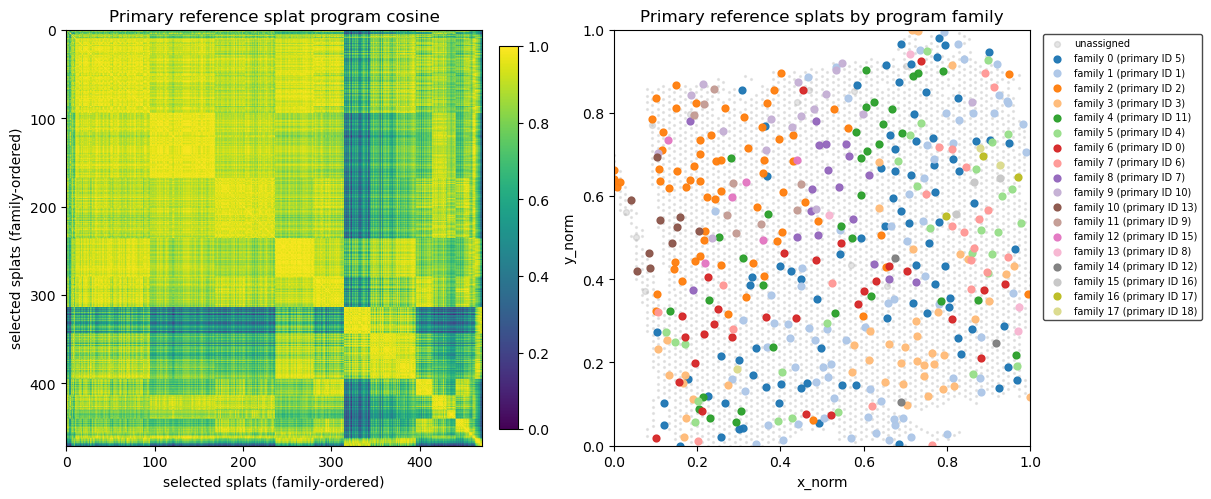

In [24]:
order = np.argsort(ordered_family_ids)
ordered_cosine = primary_pairwise_cosine[order][:, order]
ordered_family_ids_plot = ordered_family_ids[order]
selected_means_np = primary_means_np[selected_mask]
selected_means_ordered = selected_means_np[order]

shared_family_ranks = list(range(len(family_records)))
shared_family_palette = list(plt.get_cmap('tab20').colors)
family_rank_to_color = {
    family_rank: shared_family_palette[family_rank % len(shared_family_palette)]
    for family_rank in shared_family_ranks
}
family_rank_to_color.setdefault(-1, (0.7, 0.7, 0.7, 1.0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

im = axes[0].imshow(ordered_cosine, cmap='viridis', vmin=0.0, vmax=1.0)
axes[0].set_title('Primary reference splat program cosine')
axes[0].set_xlabel('selected splats (family-ordered)')
axes[0].set_ylabel('selected splats (family-ordered)')
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].scatter(primary_xy_norm_np[:, 0], primary_xy_norm_np[:, 1], s=2, alpha=0.08, color='black')
unassigned_mask = ordered_family_ids == -1
if np.any(unassigned_mask):
    axes[1].scatter(selected_means_np[unassigned_mask, 0], selected_means_np[unassigned_mask, 1], s=18, alpha=0.35, color=family_rank_to_color[-1], label='unassigned')
for family_rank, rec in enumerate(family_records):
    family_mask = ordered_family_ids == family_rank
    if np.any(family_mask):
        axes[1].scatter(
            selected_means_np[family_mask, 0],
            selected_means_np[family_mask, 1],
            s=24,
            alpha=0.96,
            color=family_rank_to_color[family_rank],
            label=f'family {family_rank} (primary ID {rec["family_id"]})',
        )
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_aspect('equal')
axes[1].set_title('Primary reference splats by program family')
axes[1].set_xlabel('x_norm')
axes[1].set_ylabel('y_norm')
axes[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=7)

export_figure_axes(fig, fallback_prefix='primary_reference_families')
plt.show()


## Lymph-Node Transfer

Use the primary program families as prototypes and score the easier metastatic sample `IU_PDA_LNM8` against them. This is the first downstream transfer check: if the primary-derived families are meaningful, the lymph-node sample should show coherent family matches and spatial concentration in tumor-associated regions.


In [25]:
lnm_bundle = sample_bundles['lymph_node_met']
lnm_model = section_splat_results['lymph_node_met']['model']
lnm_obs = lnm_bundle['adata'].obs.copy()
lnm_features = lnm_bundle['xy_norm'].to(device)
lnm_gene_names = np.asarray(lnm_bundle['gene_names'], dtype=object)

# Build family prototypes from the active pancreatic family bank.
family_prototypes = []
family_metadata = []
for rec in family_records:
    family_id = rec['family_id']
    family_local = np.flatnonzero(active_primary_family_ids == family_id)
    family_splat_idx = active_primary_splat_indices[family_local]
    family_proto = primary_composition[family_splat_idx].mean(dim=0)
    family_proto = family_proto / family_proto.norm().clamp_min(1e-8)
    family_prototypes.append(family_proto)
    family_metadata.append(rec)
family_prototypes = torch.stack(family_prototypes, dim=0)

with torch.no_grad():
    lnm_composition = lnm_model.splat_composition().detach().cpu()
    lnm_comp_norm = lnm_composition / lnm_composition.norm(dim=1, keepdim=True).clamp_min(1e-8)
    family_cosine = lnm_comp_norm @ family_prototypes.T
    lnm_top2_family_score, lnm_top2_family_rank = torch.topk(family_cosine, k=min(2, family_cosine.shape[1]), dim=1)
    lnm_best_family_score = lnm_top2_family_score[:, 0]
    lnm_best_family_rank = lnm_top2_family_rank[:, 0]
    lnm_weights = compute_splat_weights(lnm_model, lnm_features).detach().cpu()

lnm_best_family_score_np = lnm_best_family_score.numpy()
lnm_best_family_rank_np = lnm_best_family_rank.numpy()
lnm_second_family_score_np = lnm_top2_family_score[:, 1].numpy() if lnm_top2_family_score.shape[1] > 1 else np.zeros_like(lnm_best_family_score_np)
lnm_assignment_margin_np = lnm_best_family_score_np - lnm_second_family_score_np
lnm_spot_family_scores = (lnm_weights.numpy() * lnm_best_family_score_np[None, :]).sum(axis=1)
lnm_spot_top_family = (lnm_weights.numpy() @ np.eye(len(family_records))[lnm_best_family_rank_np]).argmax(axis=1)

lnm_family_summary = {}
for family_rank, rec in enumerate(family_records):
    splat_mask = lnm_best_family_rank_np == family_rank
    spot_mask = lnm_spot_top_family == family_rank
    lnm_family_summary[f'family_{family_rank}'] = {
        'primary_family_id': int(rec['family_id']),
        'size_in_primary': int(rec['size']),
        'top_genes': rec['top_genes'],
        'matched_lnm_splats': int(splat_mask.sum()),
        'median_lnm_splat_score': float(np.median(lnm_best_family_score_np[splat_mask])) if np.any(splat_mask) else float('nan'),
        'matched_lnm_spots': int(spot_mask.sum()),
        'fraction_lnm_spots': float(spot_mask.mean()),
        'median_assignment_margin': float(np.median(lnm_assignment_margin_np[splat_mask])) if np.any(splat_mask) else float('nan'),
        'tumor_first_fraction_in_matched_spots': float(lnm_obs.loc[spot_mask, 'first_type'].astype(str).eq(tumor_label).mean()) if np.any(spot_mask) else float('nan'),
        'tumor_second_fraction_in_matched_spots': float(lnm_obs.loc[spot_mask, 'second_type'].astype(str).eq(tumor_label).mean()) if np.any(spot_mask) else float('nan'),
    }

lnm_transfer_summary = {
    'n_lnm_splats': int(lnm_model.num_splats),
    'median_best_family_score': float(np.median(lnm_best_family_score_np)),
    'q90_best_family_score': float(np.quantile(lnm_best_family_score_np, 0.9)),
    'mean_spot_family_score': float(np.mean(lnm_spot_family_scores)),
    'q90_spot_family_score': float(np.quantile(lnm_spot_family_scores, 0.9)),
    'tumor_first_fraction_overall': float(lnm_obs['first_type'].astype(str).eq(tumor_label).mean()),
    'tumor_second_fraction_overall': float(lnm_obs['second_type'].astype(str).eq(tumor_label).mean()),
}

lnm_family_summary_display = {
    key: lnm_family_summary[key]
    for key in list(lnm_family_summary.keys())[:max_primary_families_report]
}

print('Lymph-node transfer summary')
print(format_for_display(lnm_transfer_summary))
print('Example lymph-node family matches')
print(format_for_display(lnm_family_summary_display))


Lymph-node transfer summary
{'n_lnm_splats': 426, 'median_best_family_score': 0.9532, 'q90_best_family_score': 0.9746, 'mean_spot_family_score': 0.9412, 'q90_spot_family_score': 0.9731, 'tumor_first_fraction_overall': 0.3948, 'tumor_second_fraction_overall': 0.1843}
Example lymph-node family matches
{'family_0': {'primary_family_id': 5, 'size_in_primary': 84, 'top_genes': ['IGKC', 'UBC', 'OLFM4', 'S100A6', 'TMSB4X', 'FTL', 'ACTB', 'LYZ', 'SPINK1', 'B2M'], 'matched_lnm_splats': 0, 'median_lnm_splat_score': nan, 'matched_lnm_spots': 0, 'fraction_lnm_spots': 0.0, 'median_assignment_margin': nan, 'tumor_first_fraction_in_matched_spots': nan, 'tumor_second_fraction_in_matched_spots': nan}, 'family_1': {'primary_family_id': 1, 'size_in_primary': 73, 'top_genes': ['OLFM4', 'S100A6', 'UBC', 'LYZ', 'TMSB4X', 'SPINK1', 'FTL', 'ACTB', 'IGKC', 'B2M'], 'matched_lnm_splats': 0, 'median_lnm_splat_score': nan, 'matched_lnm_spots': 0, 'fraction_lnm_spots': 0.0, 'median_assignment_margin': nan, 'tumor_f

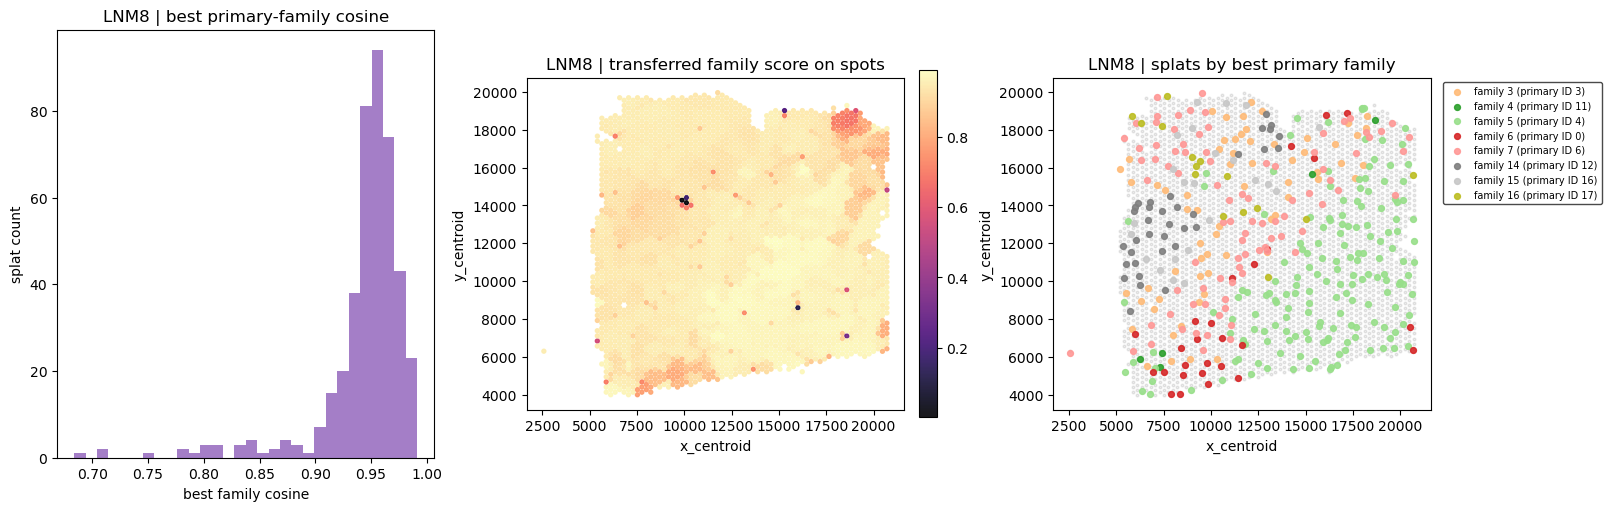

In [26]:
lnm_means_np = lnm_model.means.detach().cpu().numpy()
lnm_xy_raw = lnm_bundle['xy_raw']
lnm_xy_norm_np = lnm_bundle['xy_norm'].numpy()
lnm_xmin, lnm_xmax = float(lnm_xy_raw[:, 0].min()), float(lnm_xy_raw[:, 0].max())
lnm_ymin, lnm_ymax = float(lnm_xy_raw[:, 1].min()), float(lnm_xy_raw[:, 1].max())
lnm_means_raw = np.column_stack([
    lnm_means_np[:, 0] * (lnm_xmax - lnm_xmin) + lnm_xmin,
    lnm_means_np[:, 1] * (lnm_ymax - lnm_ymin) + lnm_ymin,
])
lnm_display_family_ranks = sorted(int(rank) for rank in np.unique(lnm_best_family_rank_np))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

axes[0].hist(lnm_best_family_score_np, bins=30, color='tab:purple', alpha=0.85)
axes[0].set_title('LNM8 | best primary-family cosine')
axes[0].set_xlabel('best family cosine')
axes[0].set_ylabel('splat count')

scatter = axes[1].scatter(lnm_xy_raw[:, 0], lnm_xy_raw[:, 1], c=lnm_spot_family_scores, s=8, cmap='magma', alpha=0.9)
axes[1].set_aspect('equal')
axes[1].set_title('LNM8 | transferred family score on spots')
axes[1].set_xlabel('x_centroid')
axes[1].set_ylabel('y_centroid')
plt.colorbar(scatter, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].scatter(lnm_xy_raw[:, 0], lnm_xy_raw[:, 1], s=4, alpha=0.08, color='black')
for family_rank in lnm_display_family_ranks:
    splat_mask = lnm_best_family_rank_np == family_rank
    if np.any(splat_mask):
        primary_family_id = int(family_records[family_rank]['family_id'])
        axes[2].scatter(lnm_means_raw[splat_mask, 0], lnm_means_raw[splat_mask, 1], s=18, alpha=0.9, color=family_rank_to_color[family_rank], label=f'family {family_rank} (primary ID {primary_family_id})')
axes[2].set_aspect('equal')
axes[2].set_title('LNM8 | splats by best primary family')
axes[2].set_xlabel('x_centroid')
axes[2].set_ylabel('y_centroid')
axes[2].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=7)

export_figure_axes(fig, fallback_prefix='lymph_node_transfer')
plt.show()


## Unsupervised Lymph-Node Family Filtering

Use the lymph-node sample to identify pancreatic program families that transfer with confident and separated family matches. This selection uses only family-match score, assignment margin, and matched-splat support. Lymph-node annotations are retained only as diagnostics after the role assignment.


In [27]:
lnm_family_min_splats_for_support = 3
lnm_family_score_threshold = 0.9
lnm_family_margin_threshold = 0.01
lnm_ig_gene_prefixes = ('IGH', 'IGK', 'IGL')
lnm_ig_topk = 10
lnm_ig_top_gene_fraction_threshold = 0.4

family_role_records = []
for family_rank, rec in enumerate(family_records):
    splat_mask = lnm_best_family_rank_np == family_rank
    spot_mask = lnm_spot_top_family == family_rank
    matched_splats = int(splat_mask.sum())
    matched_spots = int(spot_mask.sum())
    median_score = float(np.median(lnm_best_family_score_np[splat_mask])) if matched_splats > 0 else float('nan')
    q75_assignment_margin = float(np.quantile(lnm_assignment_margin_np[splat_mask], 0.75)) if matched_splats > 0 else float('nan')
    tumor_first_fraction = float(
        lnm_obs.loc[spot_mask, 'first_type'].astype(str).eq(tumor_label).mean()
    ) if matched_spots > 0 else float('nan')
    tumor_second_fraction = float(
        lnm_obs.loc[spot_mask, 'second_type'].astype(str).eq(tumor_label).mean()
    ) if matched_spots > 0 else float('nan')
    ig_top_gene_fraction = float(np.mean([
        str(g).upper().startswith(lnm_ig_gene_prefixes)
        for g in rec['top_genes'][:lnm_ig_topk]
    ])) if rec['top_genes'] else 0.0
    is_ig_dominant = ig_top_gene_fraction >= lnm_ig_top_gene_fraction_threshold

    if (
        not is_ig_dominant
        and matched_splats >= lnm_family_min_splats_for_support
        and np.isfinite(median_score)
        and median_score >= lnm_family_score_threshold
        and np.isfinite(q75_assignment_margin)
        and q75_assignment_margin >= lnm_family_margin_threshold
    ):
        role = 'transfer_supported'
    else:
        role = 'background_like'

    family_role_records.append({
        'family_rank': int(family_rank),
        'primary_family_id': int(rec['family_id']),
        'role': role,
        'matched_lnm_splats': matched_splats,
        'matched_lnm_spots': matched_spots,
        'median_lnm_splat_score': median_score,
        'q75_lnm_assignment_margin': q75_assignment_margin,
        'ig_top_gene_fraction': ig_top_gene_fraction,
        'is_ig_dominant': bool(is_ig_dominant),
        'tumor_first_fraction_in_matched_spots': tumor_first_fraction,
        'tumor_second_fraction_in_matched_spots': tumor_second_fraction,
        'top_genes': rec['top_genes'],
    })

positive_family_ranks = np.array(
    [rec['family_rank'] for rec in family_role_records if rec['role'] == 'transfer_supported'],
    dtype=np.int64,
)
background_family_ranks = np.array(
    [rec['family_rank'] for rec in family_role_records if rec['role'] != 'transfer_supported'],
    dtype=np.int64,
)
if len(positive_family_ranks) == 0:
    raise RuntimeError('No transfer-supported family ranks identified; lower the score or margin threshold after inspecting diagnostics.')
if len(background_family_ranks) == 0:
    raise RuntimeError('No background-like family ranks identified; the role split is degenerate.')

positive_family_score = family_cosine[:, positive_family_ranks].max(dim=1).values.detach().cpu().numpy()
background_family_score = family_cosine[:, background_family_ranks].max(dim=1).values.detach().cpu().numpy()
lnm_family_margin = positive_family_score - background_family_score
lnm_spot_family_margin = (lnm_weights.numpy() * lnm_family_margin[None, :]).sum(axis=1)

positive_family_vote = np.eye(len(family_records), dtype=np.float32)[positive_family_ranks].sum(axis=0)
lnm_spot_positive_vote = lnm_weights.numpy() @ positive_family_vote[lnm_best_family_rank_np]
lnm_spot_positive_mask = lnm_spot_positive_vote >= 0.5

lnm_margin_summary = {
    'selection_uses_lnm_annotations': False,
    'family_score_threshold': float(lnm_family_score_threshold),
    'family_margin_threshold': float(lnm_family_margin_threshold),
    'family_min_splats_for_support': int(lnm_family_min_splats_for_support),
    'ig_topk': int(lnm_ig_topk),
    'ig_top_gene_fraction_threshold': float(lnm_ig_top_gene_fraction_threshold),
    'n_ig_dominant_excluded_families': int(sum(rec['is_ig_dominant'] for rec in family_role_records)),
    'ig_dominant_excluded_family_ranks': [int(rec['family_rank']) for rec in family_role_records if rec['is_ig_dominant']],
    'n_transfer_supported_family_ranks': int(len(positive_family_ranks)),
    'transfer_supported_family_ranks': [int(x) for x in positive_family_ranks.tolist()],
    'n_background_family_ranks': int(len(background_family_ranks)),
    'background_family_ranks': [int(x) for x in background_family_ranks.tolist()],
    'median_positive_family_score': float(np.median(positive_family_score)),
    'median_background_family_score': float(np.median(background_family_score)),
    'median_family_margin': float(np.median(lnm_family_margin)),
    'q90_family_margin': float(np.quantile(lnm_family_margin, 0.9)),
    'mean_spot_family_margin': float(np.mean(lnm_spot_family_margin)),
    'q90_spot_family_margin': float(np.quantile(lnm_spot_family_margin, 0.9)),
    'positive_vote_spot_fraction': float(lnm_spot_positive_mask.mean()),
    'tumor_first_fraction_in_positive_vote_spots_diagnostic': float(
        lnm_obs.loc[lnm_spot_positive_mask, 'first_type'].astype(str).eq(tumor_label).mean()
    ) if np.any(lnm_spot_positive_mask) else float('nan'),
    'tumor_second_fraction_in_positive_vote_spots_diagnostic': float(
        lnm_obs.loc[lnm_spot_positive_mask, 'second_type'].astype(str).eq(tumor_label).mean()
    ) if np.any(lnm_spot_positive_mask) else float('nan'),
}
lnm_family_role_summary = {
    f'family_{rec["family_rank"]}': rec
    for rec in family_role_records[:max_primary_families_report]
}

print('Unsupervised lymph-node family role summary')
print(format_for_display(lnm_family_role_summary))
print('Lymph-node transfer-supported family margin summary')
print(format_for_display(lnm_margin_summary))


Unsupervised lymph-node family role summary
{'family_0': {'family_rank': 0, 'primary_family_id': 5, 'role': 'background_like', 'matched_lnm_splats': 0, 'matched_lnm_spots': 0, 'median_lnm_splat_score': nan, 'q75_lnm_assignment_margin': nan, 'ig_top_gene_fraction': 0.1, 'is_ig_dominant': False, 'tumor_first_fraction_in_matched_spots': nan, 'tumor_second_fraction_in_matched_spots': nan, 'top_genes': ['IGKC', 'UBC', 'OLFM4', 'S100A6', 'TMSB4X', 'FTL', 'ACTB', 'LYZ', 'SPINK1', 'B2M']}, 'family_1': {'family_rank': 1, 'primary_family_id': 1, 'role': 'background_like', 'matched_lnm_splats': 0, 'matched_lnm_spots': 0, 'median_lnm_splat_score': nan, 'q75_lnm_assignment_margin': nan, 'ig_top_gene_fraction': 0.1, 'is_ig_dominant': False, 'tumor_first_fraction_in_matched_spots': nan, 'tumor_second_fraction_in_matched_spots': nan, 'top_genes': ['OLFM4', 'S100A6', 'UBC', 'LYZ', 'TMSB4X', 'SPINK1', 'FTL', 'ACTB', 'IGKC', 'B2M']}, 'family_2': {'family_rank': 2, 'primary_family_id': 2, 'role': 'backgro

Lymph-node family confidence table


,family_rank,primary_family_id,role,matched_lnm_splats,matched_lnm_spots,tumor_first_fraction_in_matched_spots,tumor_second_fraction_in_matched_spots,median_splat_score,q90_splat_score,median_splat_margin,q90_splat_margin,median_spot_score,q90_spot_score,median_spot_margin,q90_spot_margin,top_genes
0,5,4,background_like,168,1340,0.078358,0.179104,0.969101,0.982921,-0.137568,-0.029088,0.967381,0.980834,-0.139908,-0.032249,"[IGKC, IGHA1, IGHG1, UBC, S100A6, IGHG3, TMSB4..."
1,7,6,transfer_supported,88,719,0.602225,0.164117,0.954402,0.961717,0.012693,0.028863,0.953570,0.961416,0.011817,0.024316,"[IGKC, UBC, S100A6, IGHA1, FTL, OLFM4, TMSB4X,..."
2,3,3,transfer_supported,65,556,0.647482,0.214029,0.942816,0.951123,0.012468,0.026658,0.942092,0.951244,0.013793,0.026670,"[IGKC, FTL, S100A6, UBC, TMSB4X, OLFM4, ACTB, ..."
3,14,12,transfer_supported,35,276,0.684783,0.307971,0.931126,0.946575,0.036215,0.075969,0.931616,0.946055,0.032206,0.071905,"[S100A6, FTL, UBC, TMSB4X, ACTB, SPINK1, LYZ, ..."
4,6,0,transfer_supported,27,195,0.153846,0.092308,0.917690,0.953787,0.033412,0.050946,0.929717,0.953595,0.026066,0.052454,"[IGKC, IGHA1, UBC, ACTB, TMSB4X, FTL, COL1A2, ..."
5,15,16,background_like,23,178,0.848315,0.134831,0.946090,0.952877,-0.003763,-0.001070,0.943268,0.951882,-0.002918,0.000051,"[IGKC, S100A6, LYZ, UBC, TMSB4X, IGHG3, SPINK1..."
6,16,17,background_like,15,106,0.688679,0.160377,0.951920,0.956262,-0.003543,-0.000807,0.950976,0.957424,-0.002672,-0.000441,"[IGKC, S100A6, IGHG3, LYZ, UBC, TMSB4X, IGHA1,..."
7,4,11,transfer_supported,5,37,0.108108,0.189189,0.928550,0.933396,0.010921,0.026808,0.928400,0.934706,0.008558,0.017376,"[UBC, FTL, IGKC, ACTB, S100A6, TMSB4X, OLFM4, ..."
8,0,5,background_like,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[IGKC, UBC, OLFM4, S100A6, TMSB4X, FTL, ACTB, ..."
9,1,1,background_like,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[OLFM4, S100A6, UBC, LYZ, TMSB4X, SPINK1, FTL,..."


High-confidence lymph-node positive summary
{'score_threshold': 0.9, 'margin_threshold': 0.02, 'high_conf_positive_splat_fraction': 0.1643, 'high_conf_positive_spot_fraction': 0.1509, 'selection_uses_lnm_annotations': False, 'tumor_first_fraction_in_high_conf_positive_spots': 0.5156, 'tumor_second_fraction_in_high_conf_positive_spots': 0.2315}


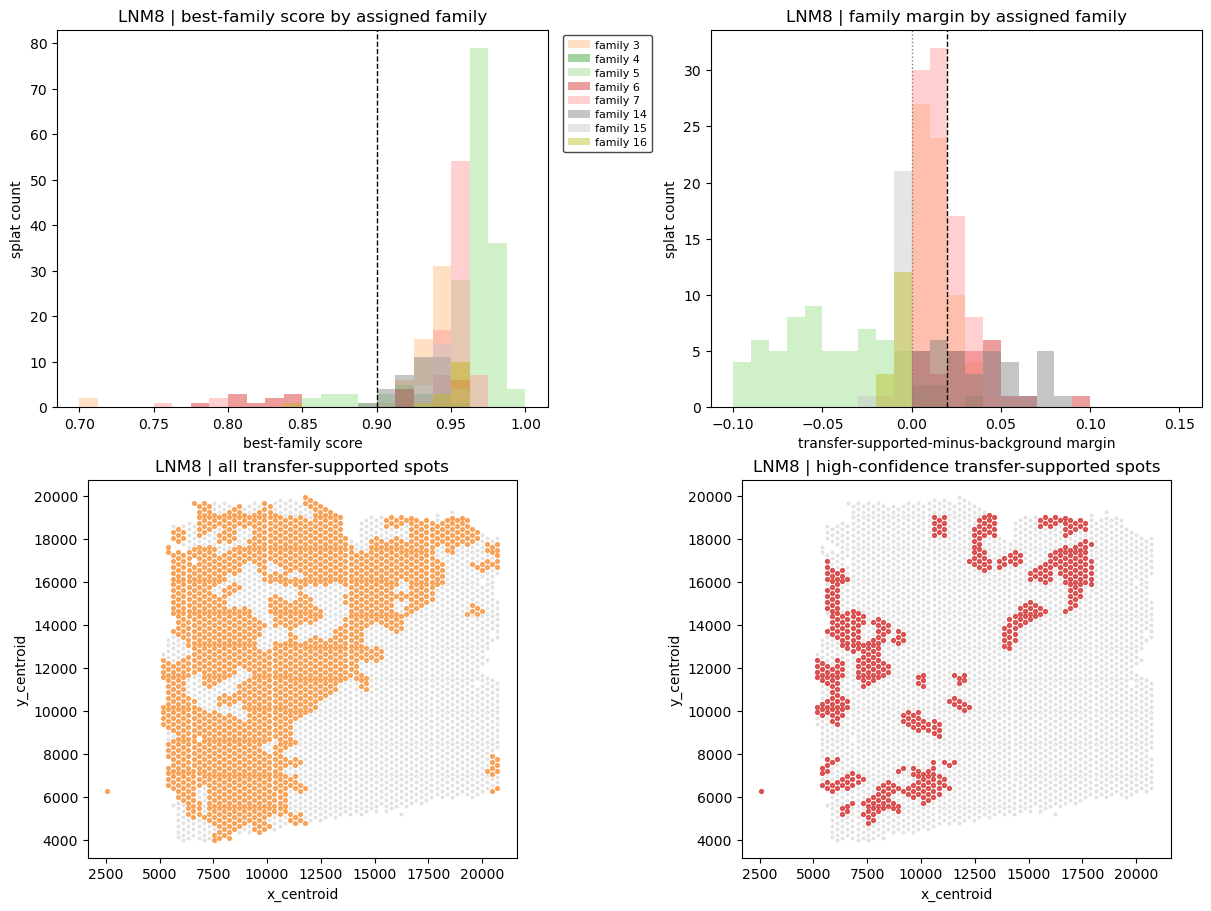

In [28]:
family_confidence_records = []
for family_rank, rec in enumerate(family_records):
    splat_mask = lnm_best_family_rank_np == family_rank
    spot_mask = lnm_spot_top_family == family_rank
    splat_scores = lnm_best_family_score_np[splat_mask]
    splat_margins = lnm_family_margin[splat_mask]
    spot_scores = lnm_spot_family_scores[spot_mask]
    spot_margins = lnm_spot_family_margin[spot_mask]
    family_confidence_records.append({
        'family_rank': int(family_rank),
        'primary_family_id': int(rec['family_id']),
        'role': family_role_records[family_rank]['role'],
        'matched_lnm_splats': int(splat_mask.sum()),
        'matched_lnm_spots': int(spot_mask.sum()),
        'tumor_first_fraction_in_matched_spots': family_role_records[family_rank]['tumor_first_fraction_in_matched_spots'],
        'tumor_second_fraction_in_matched_spots': family_role_records[family_rank]['tumor_second_fraction_in_matched_spots'],
        'median_splat_score': float(np.median(splat_scores)) if splat_scores.size else float('nan'),
        'q90_splat_score': float(np.quantile(splat_scores, 0.9)) if splat_scores.size else float('nan'),
        'median_splat_margin': float(np.median(splat_margins)) if splat_margins.size else float('nan'),
        'q90_splat_margin': float(np.quantile(splat_margins, 0.9)) if splat_margins.size else float('nan'),
        'median_spot_score': float(np.median(spot_scores)) if spot_scores.size else float('nan'),
        'q90_spot_score': float(np.quantile(spot_scores, 0.9)) if spot_scores.size else float('nan'),
        'median_spot_margin': float(np.median(spot_margins)) if spot_margins.size else float('nan'),
        'q90_spot_margin': float(np.quantile(spot_margins, 0.9)) if spot_margins.size else float('nan'),
        'top_genes': rec['top_genes'],
    })

family_confidence_table = pd.DataFrame(family_confidence_records).sort_values(
    ['matched_lnm_spots', 'median_splat_score'],
    ascending=[False, False],
).reset_index(drop=True)

lnm_high_conf_score_threshold = 0.9
lnm_high_conf_margin_threshold = 0.02
lnm_high_conf_splat_mask = (
    np.isin(lnm_best_family_rank_np, positive_family_ranks)
    & (lnm_best_family_score_np >= lnm_high_conf_score_threshold)
    & (lnm_family_margin >= lnm_high_conf_margin_threshold)
)
lnm_high_conf_spot_mask = (
    (lnm_spot_positive_vote >= 0.5)
    & (lnm_spot_family_scores >= lnm_high_conf_score_threshold)
    & (lnm_spot_family_margin >= lnm_high_conf_margin_threshold)
)

lnm_high_conf_summary = {
    'score_threshold': float(lnm_high_conf_score_threshold),
    'margin_threshold': float(lnm_high_conf_margin_threshold),
    'high_conf_positive_splat_fraction': float(lnm_high_conf_splat_mask.mean()),
    'high_conf_positive_spot_fraction': float(lnm_high_conf_spot_mask.mean()),
    'selection_uses_lnm_annotations': False,
    'tumor_first_fraction_in_high_conf_positive_spots': float(lnm_obs.loc[lnm_high_conf_spot_mask, 'first_type'].astype(str).eq(tumor_label).mean()),
    'tumor_second_fraction_in_high_conf_positive_spots': float(lnm_obs.loc[lnm_high_conf_spot_mask, 'second_type'].astype(str).eq(tumor_label).mean()),
}

print('Lymph-node family confidence table')
display(family_confidence_table)
print('High-confidence lymph-node positive summary')
print(format_for_display(lnm_high_conf_summary))

lnm_confidence_family_ranks = sorted(int(rank) for rank in np.unique(lnm_best_family_rank_np))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)

for family_rank in lnm_confidence_family_ranks:
    splat_mask = lnm_best_family_rank_np == family_rank
    if np.any(splat_mask):
        axes[0, 0].hist(
            lnm_best_family_score_np[splat_mask],
            bins=np.linspace(0.7, 1.0, 25),
            alpha=0.45,
            color=family_rank_to_color[family_rank],
            label=f'family {family_rank}',
        )
axes[0, 0].axvline(lnm_high_conf_score_threshold, color='black', linestyle='--', linewidth=1)
axes[0, 0].set_title('LNM8 | best-family score by assigned family')
axes[0, 0].set_xlabel('best-family score')
axes[0, 0].set_ylabel('splat count')
axes[0, 0].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

for family_rank in lnm_confidence_family_ranks:
    splat_mask = lnm_best_family_rank_np == family_rank
    if np.any(splat_mask):
        axes[0, 1].hist(
            lnm_family_margin[splat_mask],
            bins=np.linspace(-0.1, 0.15, 26),
            alpha=0.45,
            color=family_rank_to_color[family_rank],
        )
axes[0, 1].axvline(lnm_high_conf_margin_threshold, color='black', linestyle='--', linewidth=1)
axes[0, 1].axvline(0.0, color='gray', linestyle=':', linewidth=1)
axes[0, 1].set_title('LNM8 | family margin by assigned family')
axes[0, 1].set_xlabel('transfer-supported-minus-background margin')
axes[0, 1].set_ylabel('splat count')

axes[1, 0].scatter(lnm_xy_raw[:, 0], lnm_xy_raw[:, 1], s=4, alpha=0.08, color='black')
axes[1, 0].scatter(
    lnm_xy_raw[lnm_spot_positive_mask, 0],
    lnm_xy_raw[lnm_spot_positive_mask, 1],
    s=8,
    alpha=0.55,
    color='tab:orange',
)
axes[1, 0].set_aspect('equal')
axes[1, 0].set_title('LNM8 | all transfer-supported spots')
axes[1, 0].set_xlabel('x_centroid')
axes[1, 0].set_ylabel('y_centroid')

axes[1, 1].scatter(lnm_xy_raw[:, 0], lnm_xy_raw[:, 1], s=4, alpha=0.08, color='black')
axes[1, 1].scatter(
    lnm_xy_raw[lnm_high_conf_spot_mask, 0],
    lnm_xy_raw[lnm_high_conf_spot_mask, 1],
    s=8,
    alpha=0.7,
    color='tab:red',
)
axes[1, 1].set_aspect('equal')
axes[1, 1].set_title('LNM8 | high-confidence transfer-supported spots')
axes[1, 1].set_xlabel('x_centroid')
axes[1, 1].set_ylabel('y_centroid')

export_figure_axes(fig, fallback_prefix='lymph_node_family_confidence')
plt.show()


LNM post-filter leftover family-splat summary
{'n_lnm_splats': 426, 'n_leftover_transfer_supported_splats': 220, 'leftover_family_ranks': [3, 4, 6, 7, 14], 'n_removed_splats_total': 206, 'n_removed_by_ig_dominant_family': 168, 'n_removed_by_support_score_or_margin_family_gate': 38, 'removed_family_ranks': [0, 1, 2, 5, 8, 9, 10, 11, 12, 13, 15, 16, 17], 'ig_removed_family_ranks': [5, 17]}


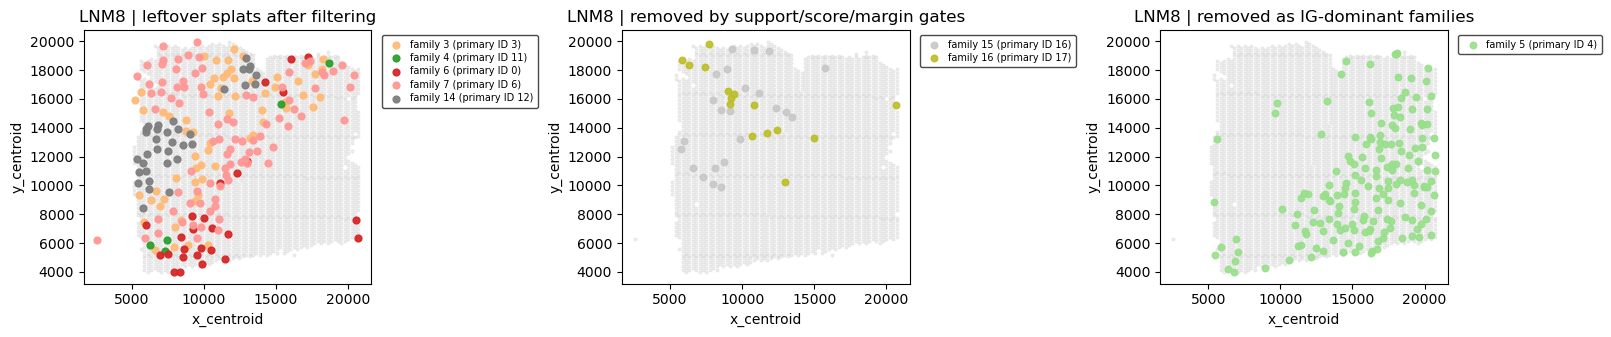

In [29]:
# Diagnostic: which LNM splats remain after family confidence and IG-dominance filtering?
removed_family_ranks = np.array(
    [rec['family_rank'] for rec in family_role_records if rec['role'] != 'transfer_supported'],
    dtype=np.int64,
)
ig_removed_family_ranks = np.array(
    [rec['family_rank'] for rec in family_role_records if rec.get('is_ig_dominant', False)],
    dtype=np.int64,
)

lnm_removed_splat_mask = np.isin(lnm_best_family_rank_np, removed_family_ranks)
lnm_ig_removed_splat_mask = np.isin(lnm_best_family_rank_np, ig_removed_family_ranks)
lnm_gate_removed_splat_mask = lnm_removed_splat_mask & ~lnm_ig_removed_splat_mask
lnm_retained_splat_mask = np.isin(lnm_best_family_rank_np, positive_family_ranks)

leftover_family_summary = {
    'n_lnm_splats': int(len(lnm_best_family_rank_np)),
    'n_leftover_transfer_supported_splats': int(lnm_retained_splat_mask.sum()),
    'leftover_family_ranks': [int(x) for x in positive_family_ranks.tolist()],
    'n_removed_splats_total': int(lnm_removed_splat_mask.sum()),
    'n_removed_by_ig_dominant_family': int(lnm_ig_removed_splat_mask.sum()),
    'n_removed_by_support_score_or_margin_family_gate': int(lnm_gate_removed_splat_mask.sum()),
    'removed_family_ranks': [int(x) for x in removed_family_ranks.tolist()],
    'ig_removed_family_ranks': [int(x) for x in ig_removed_family_ranks.tolist()],
}
print('LNM post-filter leftover family-splat summary')
print(format_for_display(leftover_family_summary))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

for ax in axes:
    ax.scatter(lnm_xy_raw[:, 0], lnm_xy_raw[:, 1], s=4, alpha=0.06, color='black')
    ax.set_aspect('equal')
    ax.set_xlabel('x_centroid')
    ax.set_ylabel('y_centroid')

for family_rank in sorted(int(rank) for rank in np.unique(lnm_best_family_rank_np[lnm_retained_splat_mask])):
    splat_mask = lnm_retained_splat_mask & (lnm_best_family_rank_np == family_rank)
    primary_family_id = int(family_records[family_rank]['family_id'])
    axes[0].scatter(
        lnm_means_raw[splat_mask, 0],
        lnm_means_raw[splat_mask, 1],
        s=24,
        alpha=0.95,
        color=family_rank_to_color[family_rank],
        label=f'family {family_rank} (primary ID {primary_family_id})',
    )
axes[0].set_title('LNM8 | leftover splats after filtering')
if np.any(lnm_retained_splat_mask):
    axes[0].legend(
        loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
        frameon=True,
        facecolor='white',
        framealpha=0.95,
        edgecolor='0.25',
        fontsize=7,
        borderpad=0.45,
        handletextpad=0.4,
        labelspacing=0.35,
    )

for family_rank in sorted(int(rank) for rank in np.unique(lnm_best_family_rank_np[lnm_gate_removed_splat_mask])):
    splat_mask = lnm_gate_removed_splat_mask & (lnm_best_family_rank_np == family_rank)
    primary_family_id = int(family_records[family_rank]['family_id'])
    axes[1].scatter(
        lnm_means_raw[splat_mask, 0],
        lnm_means_raw[splat_mask, 1],
        s=22,
        alpha=0.9,
        color=family_rank_to_color[family_rank],
        label=f'family {family_rank} (primary ID {primary_family_id})',
    )
axes[1].set_title('LNM8 | removed by support/score/margin gates')
if np.any(lnm_gate_removed_splat_mask):
    axes[1].legend(
        loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
        frameon=True,
        facecolor='white',
        framealpha=0.95,
        edgecolor='0.25',
        fontsize=7,
        borderpad=0.45,
        handletextpad=0.4,
        labelspacing=0.35,
    )

for family_rank in sorted(int(rank) for rank in np.unique(lnm_best_family_rank_np[lnm_ig_removed_splat_mask])):
    splat_mask = lnm_ig_removed_splat_mask & (lnm_best_family_rank_np == family_rank)
    primary_family_id = int(family_records[family_rank]['family_id'])
    axes[2].scatter(
        lnm_means_raw[splat_mask, 0],
        lnm_means_raw[splat_mask, 1],
        s=22,
        alpha=0.9,
        color=family_rank_to_color[family_rank],
        label=f'family {family_rank} (primary ID {primary_family_id})',
    )
axes[2].set_title('LNM8 | removed as IG-dominant families')
if np.any(lnm_ig_removed_splat_mask):
    axes[2].legend(
        loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
        frameon=True,
        facecolor='white',
        framealpha=0.95,
        edgecolor='0.25',
        fontsize=7,
        borderpad=0.45,
        handletextpad=0.4,
        labelspacing=0.35,
    )

export_figure_axes(fig, fallback_prefix='lymph_node_post_filter_leftover_splats')
plt.show()



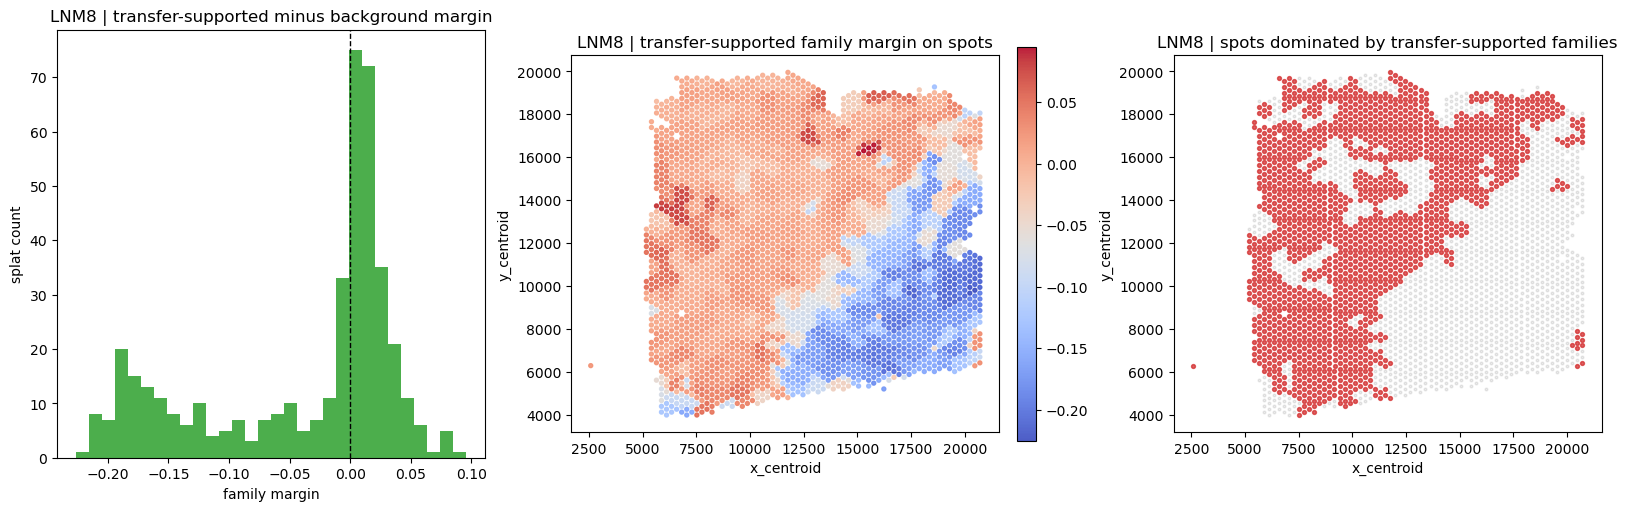

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

axes[0].hist(lnm_family_margin, bins=30, color='tab:green', alpha=0.85)
axes[0].axvline(0.0, color='black', linestyle='--', linewidth=1)
axes[0].set_title('LNM8 | transfer-supported minus background margin')
axes[0].set_xlabel('family margin')
axes[0].set_ylabel('splat count')

scatter = axes[1].scatter(lnm_xy_raw[:, 0], lnm_xy_raw[:, 1], c=lnm_spot_family_margin, s=8, cmap='coolwarm', alpha=0.9)
axes[1].set_aspect('equal')
axes[1].set_title('LNM8 | transfer-supported family margin on spots')
axes[1].set_xlabel('x_centroid')
axes[1].set_ylabel('y_centroid')
plt.colorbar(scatter, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].scatter(lnm_xy_raw[:, 0], lnm_xy_raw[:, 1], s=4, alpha=0.08, color='black')
axes[2].scatter(lnm_xy_raw[lnm_spot_positive_mask, 0], lnm_xy_raw[lnm_spot_positive_mask, 1], s=8, alpha=0.7, color='tab:red')
axes[2].set_aspect('equal')
axes[2].set_title('LNM8 | spots dominated by transfer-supported families')
axes[2].set_xlabel('x_centroid')
axes[2].set_ylabel('y_centroid')

export_figure_axes(fig, fallback_prefix='lymph_node_margin')
plt.show()


## Lymph-Node Internal Diagnostic

Compare the selected transfer-supported LNM regions with the `LNM8` annotations. The labels are not used to assign family roles here; this comparison is a diagnostic check of the unsupervised transfer-supported families.


In [31]:
lnm_tumor_first_mask = lnm_obs['first_type'].astype(str).eq(tumor_label).to_numpy()
lnm_tumor_interface_mask = (
    lnm_obs['first_type'].astype(str).eq(tumor_label)
    | lnm_obs['second_type'].astype(str).eq(tumor_label)
).to_numpy()
lnm_non_reject_mask = ~lnm_obs['spot_class'].astype(str).eq('reject').to_numpy()

verification_mask = lnm_non_reject_mask
pred_mask = lnm_spot_positive_mask & verification_mask
true_first_mask = lnm_tumor_first_mask & verification_mask
true_interface_mask = lnm_tumor_interface_mask & verification_mask


def binary_overlap_summary(pred: np.ndarray, truth: np.ndarray, *, label: str) -> dict:
    tp = int(np.sum(pred & truth))
    fp = int(np.sum(pred & ~truth))
    fn = int(np.sum(~pred & truth))
    tn = int(np.sum(~pred & ~truth))
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    specificity = tn / max(tn + fp, 1)
    baseline = float(truth.mean()) if len(truth) else float('nan')
    predicted_fraction = float(pred.mean()) if len(pred) else float('nan')
    enrichment = precision / baseline if baseline > 0 else float('nan')
    return {
        'label': label,
        'n_eval_spots': int(len(truth)),
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': float(precision),
        'recall': float(recall),
        'specificity': float(specificity),
        'baseline_positive_fraction': baseline,
        'predicted_positive_fraction': predicted_fraction,
        'precision_enrichment_over_baseline': enrichment,
    }

lnm_verification_summary = {
    'tumor_first': binary_overlap_summary(pred_mask, true_first_mask, label='tumor_first'),
    'tumor_interface': binary_overlap_summary(pred_mask, true_interface_mask, label='tumor_interface'),
}

print('Lymph-node verification summary')
print(format_for_display(lnm_verification_summary))


Lymph-node verification summary
{'tumor_first': {'label': 'tumor_first', 'n_eval_spots': 3407, 'tp': 1011, 'fp': 743, 'fn': 334, 'tn': 1319, 'precision': 0.5764, 'recall': 0.7517, 'specificity': 0.6397, 'baseline_positive_fraction': 0.3948, 'predicted_positive_fraction': 0.5148, 'precision_enrichment_over_baseline': 1.46}, 'tumor_interface': {'label': 'tumor_interface', 'n_eval_spots': 3407, 'tp': 1349, 'fp': 405, 'fn': 612, 'tn': 1041, 'precision': 0.7691, 'recall': 0.6879, 'specificity': 0.7199, 'baseline_positive_fraction': 0.5756, 'predicted_positive_fraction': 0.5148, 'precision_enrichment_over_baseline': 1.336}}


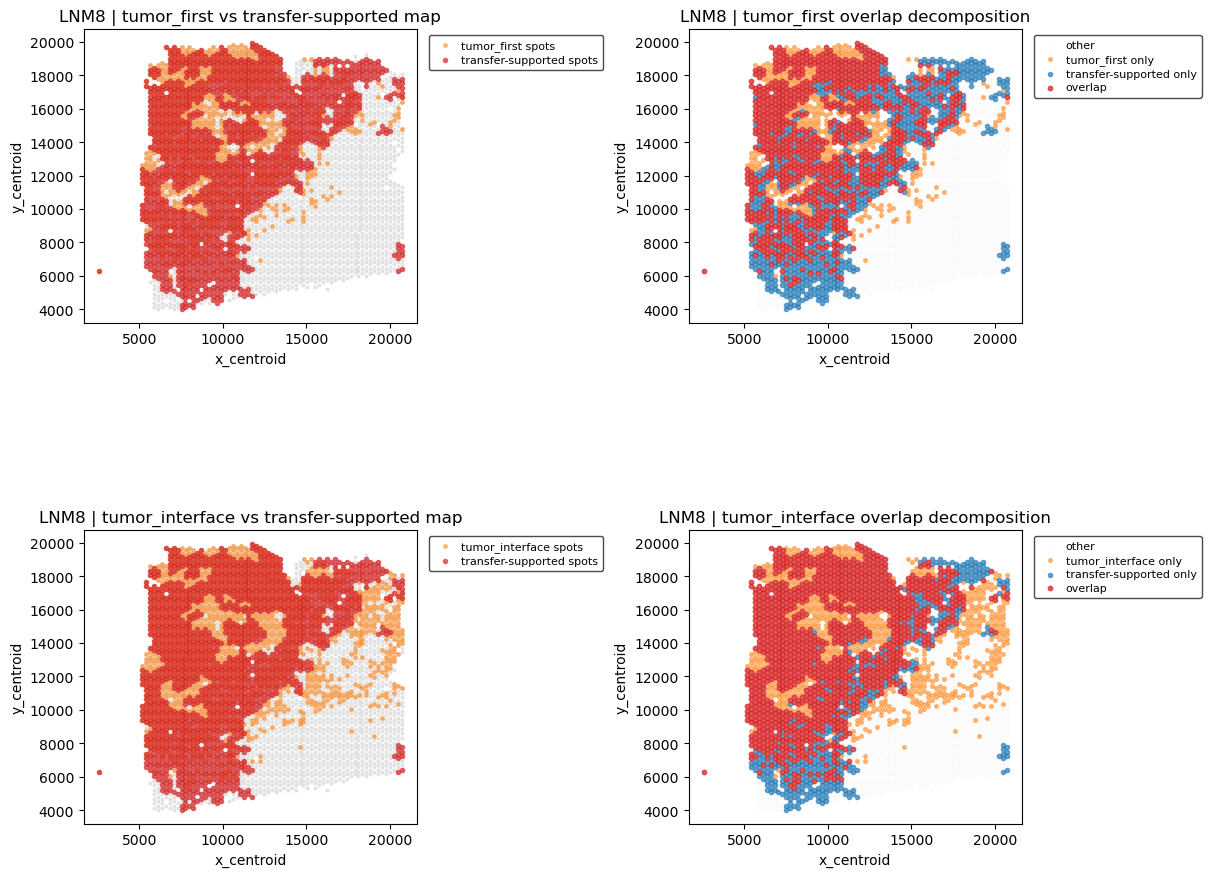

In [32]:
lnm_true_tumor_first_mask = true_first_mask
lnm_true_tumor_interface_mask = true_interface_mask

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

lnm_other_first_mask = ~(pred_mask | lnm_true_tumor_first_mask)
lnm_true_only_first_mask = lnm_true_tumor_first_mask & ~pred_mask
lnm_pred_only_first_mask = pred_mask & ~lnm_true_tumor_first_mask
lnm_overlap_first_mask = pred_mask & lnm_true_tumor_first_mask

axes[0, 0].scatter(lnm_xy_raw[verification_mask, 0], lnm_xy_raw[verification_mask, 1], s=4, alpha=0.08, color='black')
axes[0, 0].scatter(lnm_xy_raw[lnm_true_tumor_first_mask, 0], lnm_xy_raw[lnm_true_tumor_first_mask, 1], s=7, alpha=0.45, color='tab:orange', label='tumor_first spots')
axes[0, 0].scatter(lnm_xy_raw[pred_mask, 0], lnm_xy_raw[pred_mask, 1], s=9, alpha=0.65, color='tab:red', label='transfer-supported spots')
axes[0, 0].set_aspect('equal')
axes[0, 0].set_title('LNM8 | tumor_first vs transfer-supported map')
axes[0, 0].set_xlabel('x_centroid')
axes[0, 0].set_ylabel('y_centroid')
axes[0, 0].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

axes[0, 1].scatter(lnm_xy_raw[lnm_other_first_mask, 0], lnm_xy_raw[lnm_other_first_mask, 1], s=4, alpha=0.06, color='lightgray', label='other')
axes[0, 1].scatter(lnm_xy_raw[lnm_true_only_first_mask, 0], lnm_xy_raw[lnm_true_only_first_mask, 1], s=7, alpha=0.5, color='tab:orange', label='tumor_first only')
axes[0, 1].scatter(lnm_xy_raw[lnm_pred_only_first_mask, 0], lnm_xy_raw[lnm_pred_only_first_mask, 1], s=9, alpha=0.65, color='tab:blue', label='transfer-supported only')
axes[0, 1].scatter(lnm_xy_raw[lnm_overlap_first_mask, 0], lnm_xy_raw[lnm_overlap_first_mask, 1], s=10, alpha=0.75, color='tab:red', label='overlap')
axes[0, 1].set_aspect('equal')
axes[0, 1].set_title('LNM8 | tumor_first overlap decomposition')
axes[0, 1].set_xlabel('x_centroid')
axes[0, 1].set_ylabel('y_centroid')
axes[0, 1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

lnm_other_interface_mask = ~(pred_mask | lnm_true_tumor_interface_mask)
lnm_true_only_interface_mask = lnm_true_tumor_interface_mask & ~pred_mask
lnm_pred_only_interface_mask = pred_mask & ~lnm_true_tumor_interface_mask
lnm_overlap_interface_mask = pred_mask & lnm_true_tumor_interface_mask

axes[1, 0].scatter(lnm_xy_raw[verification_mask, 0], lnm_xy_raw[verification_mask, 1], s=4, alpha=0.08, color='black')
axes[1, 0].scatter(lnm_xy_raw[lnm_true_tumor_interface_mask, 0], lnm_xy_raw[lnm_true_tumor_interface_mask, 1], s=7, alpha=0.45, color='tab:orange', label='tumor_interface spots')
axes[1, 0].scatter(lnm_xy_raw[pred_mask, 0], lnm_xy_raw[pred_mask, 1], s=9, alpha=0.65, color='tab:red', label='transfer-supported spots')
axes[1, 0].set_aspect('equal')
axes[1, 0].set_title('LNM8 | tumor_interface vs transfer-supported map')
axes[1, 0].set_xlabel('x_centroid')
axes[1, 0].set_ylabel('y_centroid')
axes[1, 0].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

axes[1, 1].scatter(lnm_xy_raw[lnm_other_interface_mask, 0], lnm_xy_raw[lnm_other_interface_mask, 1], s=4, alpha=0.06, color='lightgray', label='other')
axes[1, 1].scatter(lnm_xy_raw[lnm_true_only_interface_mask, 0], lnm_xy_raw[lnm_true_only_interface_mask, 1], s=7, alpha=0.5, color='tab:orange', label='tumor_interface only')
axes[1, 1].scatter(lnm_xy_raw[lnm_pred_only_interface_mask, 0], lnm_xy_raw[lnm_pred_only_interface_mask, 1], s=9, alpha=0.65, color='tab:blue', label='transfer-supported only')
axes[1, 1].scatter(lnm_xy_raw[lnm_overlap_interface_mask, 0], lnm_xy_raw[lnm_overlap_interface_mask, 1], s=10, alpha=0.75, color='tab:red', label='overlap')
axes[1, 1].set_aspect('equal')
axes[1, 1].set_title('LNM8 | tumor_interface overlap decomposition')
axes[1, 1].set_xlabel('x_centroid')
axes[1, 1].set_ylabel('y_centroid')
axes[1, 1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

export_figure_axes(fig, fallback_prefix='lymph_node_verification')
plt.show()


## Liver Transfer

Apply the unsupervised transfer-supported versus background family split learned from `LNM8` match confidence to the liver sample `IU_PDA_HM8`. No lymph-node or liver annotation, tumor mask, or tumor-marker list is used to select families or generate liver predictions; annotations are reserved for diagnostics and final verification.


In [33]:
hm_bundle = sample_bundles['liver_sample']
hm_model = section_splat_results['liver_sample']['model']
hm_obs = hm_bundle['adata'].obs.copy()
hepatocyte_label = 'Hepatocytes'
hm_features = hm_bundle['xy_norm'].to(device)

with torch.no_grad():
    hm_composition = hm_model.splat_composition().detach().cpu()
    hm_comp_norm = hm_composition / hm_composition.norm(dim=1, keepdim=True).clamp_min(1e-8)
    hm_family_cosine = hm_comp_norm @ family_prototypes.T
    hm_best_family_score, hm_best_family_rank = hm_family_cosine.max(dim=1)
    hm_weights = compute_splat_weights(hm_model, hm_features).detach().cpu()

hm_best_family_score_np = hm_best_family_score.numpy()
hm_best_family_rank_np = hm_best_family_rank.numpy()
hm_positive_family_score = hm_family_cosine[:, positive_family_ranks].max(dim=1).values.detach().cpu().numpy()
hm_background_family_score = hm_family_cosine[:, background_family_ranks].max(dim=1).values.detach().cpu().numpy()
hm_family_margin = hm_positive_family_score - hm_background_family_score
hm_spot_family_margin = (hm_weights.numpy() * hm_family_margin[None, :]).sum(axis=1)

positive_family_vote = np.eye(len(family_records), dtype=np.float32)[positive_family_ranks].sum(axis=0)
hm_spot_positive_vote_ungated = hm_weights.numpy() @ positive_family_vote[hm_best_family_rank_np]

# Liver-side confidence gate: a splat can vote only if it confidently matches an allowed family.
# This uses family-match score and transfer-supported/background margin only, not liver annotations or marker genes.
hm_liver_score_threshold = 0.4
hm_liver_margin_threshold = 0.0
hm_confident_positive_splat_mask = (
    np.isin(hm_best_family_rank_np, positive_family_ranks)
    & (hm_best_family_score_np >= hm_liver_score_threshold)
    & (hm_family_margin >= hm_liver_margin_threshold)
)
hm_confident_positive_splat_vote = np.zeros(int(hm_model.num_splats), dtype=np.float32)
hm_confident_positive_splat_vote[hm_confident_positive_splat_mask] = 1.0
hm_spot_positive_vote = hm_weights.numpy() @ hm_confident_positive_splat_vote
hm_spot_positive_mask = hm_spot_positive_vote >= 0.5

hm_spot_top_family = (hm_weights.numpy() @ np.eye(len(family_records))[hm_best_family_rank_np]).argmax(axis=1)
hm_family_summary = {}
for family_rank, rec in enumerate(family_records):
    splat_mask = hm_best_family_rank_np == family_rank
    spot_mask = hm_spot_top_family == family_rank
    hm_family_summary[f'family_{family_rank}'] = {
        'primary_family_id': int(rec['family_id']),
        'role': family_role_records[family_rank]['role'],
        'top_genes': rec['top_genes'],
        'matched_hm_splats': int(splat_mask.sum()),
        'confident_positive_hm_splats': int((splat_mask & hm_confident_positive_splat_mask).sum()),
        'median_hm_splat_score': float(np.median(hm_best_family_score_np[splat_mask])) if np.any(splat_mask) else float('nan'),
        'matched_hm_spots': int(spot_mask.sum()),
        'fraction_hm_spots': float(spot_mask.mean()),
        'tumor_first_fraction_in_matched_spots': float(hm_obs.loc[spot_mask, 'first_type'].astype(str).eq(tumor_label).mean()) if np.any(spot_mask) else float('nan'),
        'tumor_second_fraction_in_matched_spots': float(hm_obs.loc[spot_mask, 'second_type'].astype(str).eq(tumor_label).mean()) if np.any(spot_mask) else float('nan'),
    }

hm_transfer_summary = {
    'n_hm_splats': int(hm_model.num_splats),
    'median_best_family_score': float(np.median(hm_best_family_score_np)),
    'q90_best_family_score': float(np.quantile(hm_best_family_score_np, 0.9)),
    'median_positive_family_score': float(np.median(hm_positive_family_score)),
    'median_background_family_score': float(np.median(hm_background_family_score)),
    'median_family_margin': float(np.median(hm_family_margin)),
    'q90_family_margin': float(np.quantile(hm_family_margin, 0.9)),
    'mean_spot_family_margin': float(np.mean(hm_spot_family_margin)),
    'q90_spot_family_margin': float(np.quantile(hm_spot_family_margin, 0.9)),
    'liver_score_threshold': float(hm_liver_score_threshold),
    'liver_margin_threshold': float(hm_liver_margin_threshold),
    'ungated_positive_vote_spot_fraction': float((hm_spot_positive_vote_ungated >= 0.5).mean()),
    'confident_positive_splat_fraction': float(hm_confident_positive_splat_mask.mean()),
    'positive_vote_spot_fraction': float(hm_spot_positive_mask.mean()),
    'selection_uses_lnm_annotations': False,
    'selection_uses_liver_annotations': False,
    'tumor_first_fraction_overall': float(hm_obs['first_type'].astype(str).eq(tumor_label).mean()),
    'tumor_second_fraction_overall': float(hm_obs['second_type'].astype(str).eq(tumor_label).mean()),
    'hepatocyte_first_fraction_overall': float(hm_obs['first_type'].astype(str).eq(hepatocyte_label).mean()),
    'hepatocyte_second_fraction_overall': float(hm_obs['second_type'].astype(str).eq(hepatocyte_label).mean()),
    'tumor_first_fraction_in_positive_vote_spots': float(hm_obs.loc[hm_spot_positive_mask, 'first_type'].astype(str).eq(tumor_label).mean()),
    'tumor_second_fraction_in_positive_vote_spots': float(hm_obs.loc[hm_spot_positive_mask, 'second_type'].astype(str).eq(tumor_label).mean()),
    'hepatocyte_first_fraction_in_positive_vote_spots': float(hm_obs.loc[hm_spot_positive_mask, 'first_type'].astype(str).eq(hepatocyte_label).mean()),
    'hepatocyte_second_fraction_in_positive_vote_spots': float(hm_obs.loc[hm_spot_positive_mask, 'second_type'].astype(str).eq(hepatocyte_label).mean()),
}

hm_family_summary_display = {
    key: hm_family_summary[key]
    for key in list(hm_family_summary.keys())[:max_primary_families_report]
}

print('Liver transfer summary')
print(format_for_display(hm_transfer_summary))
print('Example liver family matches')
print(format_for_display(hm_family_summary_display))


Liver transfer summary
{'n_hm_splats': 504, 'median_best_family_score': 0.1872, 'q90_best_family_score': 0.3466, 'median_positive_family_score': 0.1872, 'median_background_family_score': 0.1852, 'median_family_margin': 0.002097, 'q90_family_margin': 0.01249, 'mean_spot_family_margin': 0.004692, 'q90_spot_family_margin': 0.01232, 'liver_score_threshold': 0.4, 'liver_margin_threshold': 0.0, 'ungated_positive_vote_spot_fraction': 0.7783, 'confident_positive_splat_fraction': 0.08135, 'positive_vote_spot_fraction': 0.07961, 'selection_uses_lnm_annotations': False, 'selection_uses_liver_annotations': False, 'tumor_first_fraction_overall': 0.08135, 'tumor_second_fraction_overall': 0.3872, 'hepatocyte_first_fraction_overall': 0.8921, 'hepatocyte_second_fraction_overall': 0.09772, 'tumor_first_fraction_in_positive_vote_spots': 0.7445, 'tumor_second_fraction_in_positive_vote_spots': 0.09034, 'hepatocyte_first_fraction_in_positive_vote_spots': 0.06231, 'hepatocyte_second_fraction_in_positive_vote

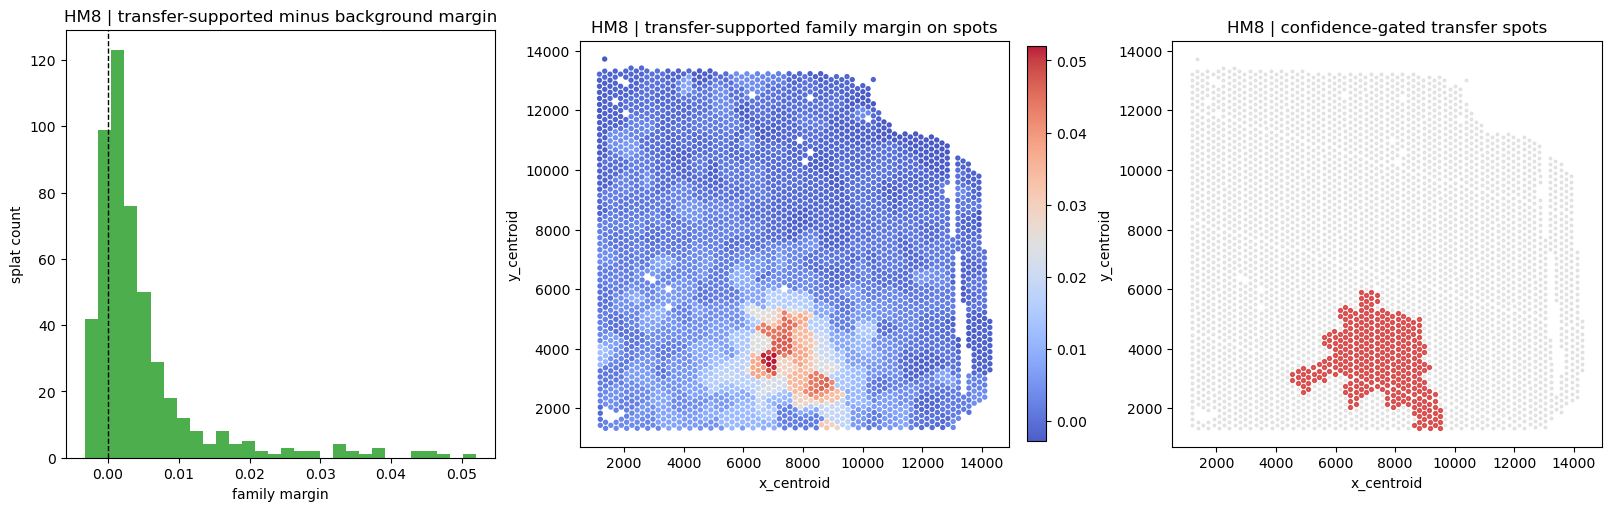

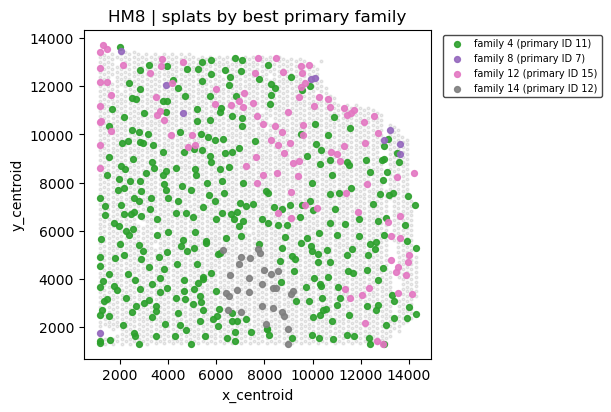

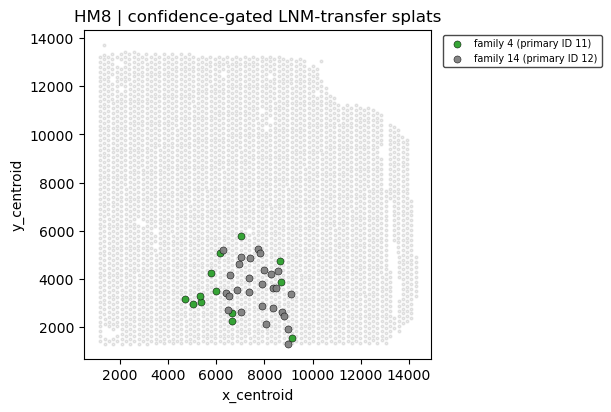

In [34]:
hm_xy_raw = hm_bundle['xy_raw']
hm_xy_norm_np = hm_bundle['xy_norm'].numpy()
hm_means_np = hm_model.means.detach().cpu().numpy()
hm_xmin, hm_xmax = float(hm_xy_raw[:, 0].min()), float(hm_xy_raw[:, 0].max())
hm_ymin, hm_ymax = float(hm_xy_raw[:, 1].min()), float(hm_xy_raw[:, 1].max())
hm_means_raw = np.column_stack([
    hm_means_np[:, 0] * (hm_xmax - hm_xmin) + hm_xmin,
    hm_means_np[:, 1] * (hm_ymax - hm_ymin) + hm_ymin,
])
hm_display_family_ranks = sorted(int(rank) for rank in np.unique(hm_best_family_rank_np))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

axes[0].hist(hm_family_margin, bins=30, color='tab:green', alpha=0.85)
axes[0].axvline(0.0, color='black', linestyle='--', linewidth=1)
axes[0].set_title('HM8 | transfer-supported minus background margin')
axes[0].set_xlabel('family margin')
axes[0].set_ylabel('splat count')

scatter = axes[1].scatter(hm_xy_raw[:, 0], hm_xy_raw[:, 1], c=hm_spot_family_margin, s=8, cmap='coolwarm', alpha=0.9)
axes[1].set_aspect('equal')
axes[1].set_title('HM8 | transfer-supported family margin on spots')
axes[1].set_xlabel('x_centroid')
axes[1].set_ylabel('y_centroid')
plt.colorbar(scatter, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].scatter(hm_xy_raw[:, 0], hm_xy_raw[:, 1], s=4, alpha=0.08, color='black')
axes[2].scatter(hm_xy_raw[hm_spot_positive_mask, 0], hm_xy_raw[hm_spot_positive_mask, 1], s=8, alpha=0.7, color='tab:red')
axes[2].set_aspect('equal')
axes[2].set_title('HM8 | confidence-gated transfer spots')
axes[2].set_xlabel('x_centroid')
axes[2].set_ylabel('y_centroid')

export_figure_axes(fig, fallback_prefix='liver_transfer')
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(6, 5), constrained_layout=True)
ax.scatter(hm_xy_raw[:, 0], hm_xy_raw[:, 1], s=4, alpha=0.08, color='black')
for family_rank in hm_display_family_ranks:
    splat_mask = hm_best_family_rank_np == family_rank
    if np.any(splat_mask):
        primary_family_id = int(family_records[family_rank]['family_id'])
        ax.scatter(hm_means_raw[splat_mask, 0], hm_means_raw[splat_mask, 1], s=18, alpha=0.9, color=family_rank_to_color[family_rank], label=f'family {family_rank} (primary ID {primary_family_id})')
ax.set_aspect('equal')
ax.set_title('HM8 | splats by best primary family')
ax.set_xlabel('x_centroid')
ax.set_ylabel('y_centroid')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=7)
export_figure_axes(fig, fallback_prefix='liver_family_assignments')
plt.show()


hm_confident_family_ranks = sorted(int(rank) for rank in np.unique(hm_best_family_rank_np[hm_confident_positive_splat_mask]))
fig, ax = plt.subplots(1, 1, figsize=(6, 5), constrained_layout=True)
ax.scatter(hm_xy_raw[:, 0], hm_xy_raw[:, 1], s=4, alpha=0.08, color='black')
for family_rank in hm_confident_family_ranks:
    splat_mask = hm_confident_positive_splat_mask & (hm_best_family_rank_np == family_rank)
    if np.any(splat_mask):
        primary_family_id = int(family_records[family_rank]['family_id'])
        ax.scatter(
            hm_means_raw[splat_mask, 0],
            hm_means_raw[splat_mask, 1],
            s=26,
            alpha=0.95,
            color=family_rank_to_color[family_rank],
            edgecolor='black',
            linewidth=0.35,
            label=f'family {family_rank} (primary ID {primary_family_id})',
        )
ax.set_aspect('equal')
ax.set_title('HM8 | confidence-gated LNM-transfer splats')
ax.set_xlabel('x_centroid')
ax.set_ylabel('y_centroid')
if hm_confident_family_ranks:
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=7)
else:
    ax.text(0.5, 0.5, 'No confidence-gated splats', transform=ax.transAxes, ha='center', va='center')
export_figure_axes(fig, fallback_prefix='liver_confident_transfer_family_assignments')
plt.show()


## Family Marker / Blend Inspection

Inspect whether the retained primary families are tumor-leaning, context-heavy, or immune-dominant. 
This section is interpretive and summarizes the family compositions rather than changing the transfer logic.


Family marker / blend summary
{'available_tumor_markers': ['KRT8', 'KRT18', 'EPCAM', 'SPINK1', 'OLFM4', 'MUC1', 'ELF3', 'MSLN', 'SPINT2'], 'available_context_markers': ['IGKC', 'IGHA1', 'IGHG1', 'LYZ', 'B2M', 'FN1', 'COL1A1', 'COL1A2', 'FTH1', 'FTL', 'ALB', 'APOA1', 'TTR'], 'available_immune_markers': ['IGKC', 'IGHA1', 'IGHG1', 'IGHG2', 'IGHG3', 'IGLC1', 'JCHAIN', 'IGHJ6', 'LYZ', 'B2M', 'MS4A1', 'CD79A'], 'n_positive_families': 5, 'n_positive_families_marker_light_or_blended': 5}
Family marker / blend examples
{'tumor_core_like_examples': [{'family_rank': 14, 'primary_family_id': 12, 'role': 'transfer_supported', 'size_in_primary': 3, 'tumor_marker_mass': 0.7873, 'context_marker_mass': 0.9985, 'immune_marker_mass': 0.5756, 'tumor_to_context_ratio': 0.7885, 'immune_to_tumor_ratio': 0.7311, 'matched_lnm_spots': 276, 'matched_hm_spots': 231, 'tumor_first_fraction_in_lnm_matches': 0.6848, 'tumor_first_fraction_in_hm_matches': 0.8139, 'top_genes': ['S100A6', 'FTL', 'UBC', 'TMSB4X', 'ACTB', 

,family_rank,primary_family_id,role,size_in_primary,matched_lnm_spots,matched_hm_spots,tumor_first_fraction_in_lnm_matches,tumor_first_fraction_in_hm_matches,tumor_marker_mass,context_marker_mass,immune_marker_mass,tumor_to_context_ratio,immune_to_tumor_ratio,top_genes
0,17,18,background_like,3,0,0,NaN,NaN,0.105153,1.310680,1.821613,0.080227,17.323515,"[IGKC, IGHG3, IGHA1, IGHG1, IGHJ6, UBC, IGLC1,..."
1,5,4,background_like,30,1340,0,0.078358,NaN,0.189406,1.559844,1.662751,0.121426,8.778758,"[IGKC, IGHA1, IGHG1, UBC, S100A6, IGHG3, TMSB4..."
2,6,0,transfer_supported,29,195,0,0.153846,NaN,0.340766,1.808622,1.476218,0.188412,4.332060,"[IGKC, IGHA1, UBC, ACTB, TMSB4X, FTL, COL1A2, ..."
3,16,17,background_like,3,106,0,0.688679,NaN,0.485194,1.472227,1.644493,0.329565,3.389353,"[IGKC, S100A6, IGHG3, LYZ, UBC, TMSB4X, IGHA1,..."
4,7,6,transfer_supported,22,719,0,0.602225,NaN,0.548846,1.637869,1.451739,0.335098,2.645075,"[IGKC, UBC, S100A6, IGHA1, FTL, OLFM4, TMSB4X,..."
5,15,16,background_like,3,178,0,0.848315,NaN,0.645520,1.337329,1.404942,0.482694,2.176450,"[IGKC, S100A6, LYZ, UBC, TMSB4X, IGHG3, SPINK1..."
6,3,3,transfer_supported,44,556,0,0.647482,NaN,0.637174,1.561062,1.106101,0.408167,1.735948,"[IGKC, FTL, S100A6, UBC, TMSB4X, OLFM4, ACTB, ..."
7,0,5,background_like,84,0,0,NaN,NaN,0.770907,1.375786,0.961846,0.560339,1.247680,"[IGKC, UBC, OLFM4, S100A6, TMSB4X, FTL, ACTB, ..."
8,4,11,transfer_supported,34,37,2912,0.108108,0.048077,0.597295,1.493803,0.727689,0.399849,1.218308,"[UBC, FTL, IGKC, ACTB, S100A6, TMSB4X, OLFM4, ..."
9,8,7,background_like,18,0,61,NaN,0.000000,0.444215,1.687817,0.518387,0.263189,1.166972,"[FN1, COL1A2, UBC, FTL, ACTB, COL1A1, TMSB4X, ..."


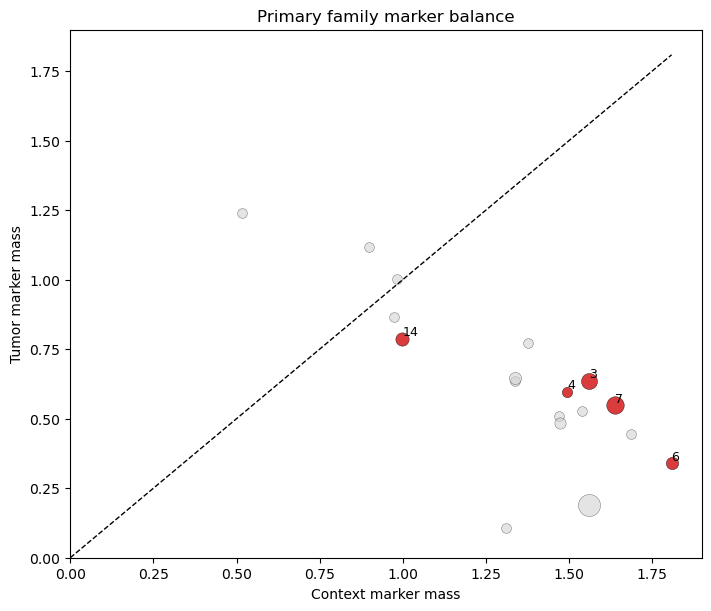

In [35]:
canonical_tumor_markers = [
    'KRT8', 'KRT18', 'KRT19', 'EPCAM', 'SPINK1', 'OLFM4', 'MUC1', 'ELF3', 'MSLN', 'SPINT2'
]
canonical_context_markers = [
    'IGKC', 'IGHA1', 'IGHG1', 'LYZ', 'B2M', 'FN1', 'COL1A1', 'COL1A2', 'FTH1', 'FTL',
    'ALB', 'APOA1', 'TTR'
]
canonical_immune_markers = [
    'IGKC', 'IGHA1', 'IGHG1', 'IGHG2', 'IGHG3', 'IGLC1', 'JCHAIN', 'IGHJ6',
    'LYZ', 'B2M', 'MS4A1', 'CD79A'
]

family_gene_to_idx = {str(g): i for i, g in enumerate(primary_gene_names)}
available_tumor_markers = [g for g in canonical_tumor_markers if g in family_gene_to_idx]
available_context_markers = [g for g in canonical_context_markers if g in family_gene_to_idx]
available_immune_markers = [g for g in canonical_immune_markers if g in family_gene_to_idx]

def marker_mass(vec: np.ndarray, genes: list[str]) -> float:
    if not genes:
        return float('nan')
    idx = [family_gene_to_idx[g] for g in genes]
    return float(vec[idx].sum())

family_inspection_records = []
for family_rank, rec in enumerate(family_records):
    proto = family_prototypes[family_rank].detach().cpu().numpy()
    tumor_marker_mass = marker_mass(proto, available_tumor_markers)
    context_marker_mass = marker_mass(proto, available_context_markers)
    immune_marker_mass = marker_mass(proto, available_immune_markers)
    marker_ratio = tumor_marker_mass / max(context_marker_mass, 1e-8) if np.isfinite(tumor_marker_mass) and np.isfinite(context_marker_mass) else float('nan')
    immune_ratio = immune_marker_mass / max(tumor_marker_mass, 1e-8) if np.isfinite(tumor_marker_mass) and np.isfinite(immune_marker_mass) else float('nan')
    role = family_role_records[family_rank]['role'] if family_rank < len(family_role_records) else 'unassigned'
    lnm_spots = lnm_family_summary.get(f'family_{family_rank}', {}).get('matched_lnm_spots', 0)
    hm_spots = hm_family_summary.get(f'family_{family_rank}', {}).get('matched_hm_spots', 0)
    family_inspection_records.append({
        'family_rank': int(family_rank),
        'primary_family_id': int(rec['family_id']),
        'role': role,
        'size_in_primary': int(rec['size']),
        'tumor_marker_mass': tumor_marker_mass,
        'context_marker_mass': context_marker_mass,
        'immune_marker_mass': immune_marker_mass,
        'tumor_to_context_ratio': marker_ratio,
        'immune_to_tumor_ratio': immune_ratio,
        'matched_lnm_spots': int(lnm_spots),
        'matched_hm_spots': int(hm_spots),
        'tumor_first_fraction_in_lnm_matches': lnm_family_summary.get(f'family_{family_rank}', {}).get('tumor_first_fraction_in_matched_spots', float('nan')),
        'tumor_first_fraction_in_hm_matches': hm_family_summary.get(f'family_{family_rank}', {}).get('tumor_first_fraction_in_matched_spots', float('nan')),
        'top_genes': rec['top_genes'],
    })

positive_inspection = [rec for rec in family_inspection_records if rec['role'] in {'tumor_like', 'transfer_supported'}]
positive_sorted = sorted(positive_inspection, key=lambda rec: (-(rec['tumor_to_context_ratio'] if np.isfinite(rec['tumor_to_context_ratio']) else -1), -rec['matched_hm_spots']))
blended_sorted = sorted(positive_inspection, key=lambda rec: ((rec['tumor_to_context_ratio'] if np.isfinite(rec['tumor_to_context_ratio']) else 1e9), -rec['matched_hm_spots']))
immune_sorted = sorted(family_inspection_records, key=lambda rec: (-(rec['immune_to_tumor_ratio'] if np.isfinite(rec['immune_to_tumor_ratio']) else -1), -rec['matched_lnm_spots']))

family_marker_blend_summary = {
    'available_tumor_markers': available_tumor_markers,
    'available_context_markers': available_context_markers,
    'available_immune_markers': available_immune_markers,
    'n_positive_families': int(len(positive_inspection)),
    'n_positive_families_marker_light_or_blended': int(sum((rec['tumor_to_context_ratio'] < 1.0) if np.isfinite(rec['tumor_to_context_ratio']) else False for rec in positive_inspection)),
}
family_marker_blend_examples = {
    'tumor_core_like_examples': positive_sorted[:min(4, len(positive_sorted))],
    'blended_or_marker_light_examples': blended_sorted[:min(4, len(blended_sorted))],
    'most_immune_like_examples': immune_sorted[:min(6, len(immune_sorted))],
}

family_composition_table = pd.DataFrame(family_inspection_records)
family_composition_table = family_composition_table[[
    'family_rank',
    'primary_family_id',
    'role',
    'size_in_primary',
    'matched_lnm_spots',
    'matched_hm_spots',
    'tumor_first_fraction_in_lnm_matches',
    'tumor_first_fraction_in_hm_matches',
    'tumor_marker_mass',
    'context_marker_mass',
    'immune_marker_mass',
    'tumor_to_context_ratio',
    'immune_to_tumor_ratio',
    'top_genes',
]]
family_composition_table = family_composition_table.sort_values(
    ['immune_to_tumor_ratio', 'matched_lnm_spots'],
    ascending=[False, False],
).reset_index(drop=True)

print('Family marker / blend summary')
print(format_for_display(family_marker_blend_summary))
print('Family marker / blend examples')
print(format_for_display(family_marker_blend_examples))
print('Per-family composition table')
display(family_composition_table)

fig, ax = plt.subplots(1, 1, figsize=(7, 6), constrained_layout=True)
for rec in family_inspection_records:
    x = rec['context_marker_mass']
    y = rec['tumor_marker_mass']
    color = 'tab:red' if rec['role'] in {'tumor_like', 'transfer_supported'} else 'lightgray'
    alpha = 0.9 if rec['role'] in {'tumor_like', 'transfer_supported'} else 0.6
    size = 50 + 0.15 * rec['matched_lnm_spots']
    ax.scatter(x, y, s=size, alpha=alpha, color=color, edgecolor='black', linewidth=0.3)
    if rec['role'] in {'tumor_like', 'transfer_supported'}:
        ax.text(x, y, str(rec['family_rank']), fontsize=9, ha='left', va='bottom')

lim = max(
    [rec['context_marker_mass'] for rec in family_inspection_records] +
    [rec['tumor_marker_mass'] for rec in family_inspection_records] +
    [1.0]
)
ax.plot([0, lim], [0, lim], linestyle='--', color='black', linewidth=1)
ax.set_xlim(0, lim * 1.05)
ax.set_ylim(0, lim * 1.05)
ax.set_xlabel('Context marker mass')
ax.set_ylabel('Tumor marker mass')
ax.set_title('Primary family marker balance')

export_figure_axes(fig, fallback_prefix='family_marker_balance')
plt.show()


## Copyable Family Transfer Audit Table

Print a compact table with one row per retained pancreatic family. This is meant for sanity-checking family rank versus primary cluster ID, LNM evidence, liver evidence, and the current positive/background assignment.


In [36]:
audit_score_threshold = globals().get('lnm_family_score_threshold', 0.9)
audit_margin_threshold = globals().get('lnm_family_margin_threshold', 0.02)
audit_min_lnm_splats = globals().get('lnm_family_min_splats_for_support', 3)

family_transfer_audit_rows = []
for family_rank, rec in enumerate(family_records):
    lnm_splat_mask = lnm_best_family_rank_np == family_rank
    lnm_spot_mask = lnm_spot_top_family == family_rank
    hm_splat_mask = hm_best_family_rank_np == family_rank
    hm_spot_mask = hm_spot_top_family == family_rank

    lnm_median_score = float(np.median(lnm_best_family_score_np[lnm_splat_mask])) if np.any(lnm_splat_mask) else float('nan')
    lnm_q75_assignment_margin = float(np.quantile(lnm_assignment_margin_np[lnm_splat_mask], 0.75)) if np.any(lnm_splat_mask) else float('nan')
    hm_median_score = float(np.median(hm_best_family_score_np[hm_splat_mask])) if np.any(hm_splat_mask) else float('nan')
    hm_median_margin = float(np.median(hm_family_margin[hm_splat_mask])) if np.any(hm_splat_mask) else float('nan')

    tumor_marker_mass = marker_mass(family_prototypes[family_rank].detach().cpu().numpy(), available_tumor_markers)
    immune_marker_mass = marker_mass(family_prototypes[family_rank].detach().cpu().numpy(), available_immune_markers)
    context_marker_mass = marker_mass(family_prototypes[family_rank].detach().cpu().numpy(), available_context_markers)

    unsup_lnm_candidate = (
        int(lnm_splat_mask.sum()) >= audit_min_lnm_splats
        and np.isfinite(lnm_median_score)
        and lnm_median_score >= audit_score_threshold
        and np.isfinite(lnm_q75_assignment_margin)
        and lnm_q75_assignment_margin >= audit_margin_threshold
    )

    immune_to_tumor_ratio = immune_marker_mass / max(tumor_marker_mass, 1e-8) if np.isfinite(immune_marker_mass) and np.isfinite(tumor_marker_mass) else float('nan')
    immune_to_context_ratio = immune_marker_mass / max(context_marker_mass, 1e-8) if np.isfinite(immune_marker_mass) and np.isfinite(context_marker_mass) else float('nan')
    lnm_spot_fraction = float(lnm_spot_mask.mean())
    lnm_high_conf_splats = int((lnm_splat_mask & lnm_high_conf_splat_mask).sum()) if 'lnm_high_conf_splat_mask' in globals() else 0

    family_transfer_audit_rows.append({
        'family_rank': int(family_rank),
        'primary_id': int(rec['family_id']),
        'current_role': family_role_records[family_rank]['role'],
        'current_positive': bool(family_rank in set(positive_family_ranks.tolist())),
        'unsup_lnm_candidate': bool(unsup_lnm_candidate),
        'ig_top_gene_fraction': round(family_role_records[family_rank].get('ig_top_gene_fraction', np.nan), 3) if np.isfinite(family_role_records[family_rank].get('ig_top_gene_fraction', np.nan)) else np.nan,
        'is_ig_dominant': bool(family_role_records[family_rank].get('is_ig_dominant', False)),
        'lnm_splats': int(lnm_splat_mask.sum()),
        'lnm_high_conf_splats': int(lnm_high_conf_splats),
        'lnm_spots': int(lnm_spot_mask.sum()),
        'lnm_spot_fraction': round(lnm_spot_fraction, 3),
        'lnm_median_score': round(lnm_median_score, 3) if np.isfinite(lnm_median_score) else np.nan,
        'lnm_q75_margin': round(lnm_q75_assignment_margin, 3) if np.isfinite(lnm_q75_assignment_margin) else np.nan,
        'lnm_tumor_first_frac': round(family_role_records[family_rank]['tumor_first_fraction_in_matched_spots'], 3) if np.isfinite(family_role_records[family_rank]['tumor_first_fraction_in_matched_spots']) else np.nan,
        'hm_splats': int(hm_splat_mask.sum()),
        'hm_confident_positive_splats': int((hm_splat_mask & hm_confident_positive_splat_mask).sum()),
        'hm_spots': int(hm_spot_mask.sum()),
        'hm_median_score': round(hm_median_score, 3) if np.isfinite(hm_median_score) else np.nan,
        'hm_median_margin': round(hm_median_margin, 3) if np.isfinite(hm_median_margin) else np.nan,
        'hm_tumor_first_frac': round(float(hm_obs.loc[hm_spot_mask, 'first_type'].astype(str).eq(tumor_label).mean()), 3) if np.any(hm_spot_mask) else np.nan,
        'tumor_marker_mass': round(tumor_marker_mass, 3) if np.isfinite(tumor_marker_mass) else np.nan,
        'immune_marker_mass': round(immune_marker_mass, 3) if np.isfinite(immune_marker_mass) else np.nan,
        'context_marker_mass': round(context_marker_mass, 3) if np.isfinite(context_marker_mass) else np.nan,
        'immune_to_tumor_ratio': round(immune_to_tumor_ratio, 3) if np.isfinite(immune_to_tumor_ratio) else np.nan,
        'immune_to_context_ratio': round(immune_to_context_ratio, 3) if np.isfinite(immune_to_context_ratio) else np.nan,
        'top_genes': ','.join(rec['top_genes'][:6]),
    })

family_transfer_audit_table = pd.DataFrame(family_transfer_audit_rows)
family_transfer_audit_table = family_transfer_audit_table.sort_values(
    ['hm_splats', 'hm_spots', 'lnm_splats'],
    ascending=[False, False, False],
).reset_index(drop=True)

print('Readable family transfer audit table')
print(family_transfer_audit_table.to_string(index=False))
print('\nTSV copy/paste version')
print(family_transfer_audit_table.to_csv(sep='\t', index=False))


Readable family transfer audit table
 family_rank  primary_id       current_role  current_positive  unsup_lnm_candidate  ig_top_gene_fraction  is_ig_dominant  lnm_splats  lnm_high_conf_splats  lnm_spots  lnm_spot_fraction  lnm_median_score  lnm_q75_margin  lnm_tumor_first_frac  hm_splats  hm_confident_positive_splats  hm_spots  hm_median_score  hm_median_margin  hm_tumor_first_frac  tumor_marker_mass  immune_marker_mass  context_marker_mass  immune_to_tumor_ratio  immune_to_context_ratio                           top_genes
           4          11 transfer_supported              True                 True                   0.1           False           5                     1         37              0.011             0.929           0.011                 0.108        357                            13      2912            0.201             0.003                0.048              0.597               0.728                1.494                  1.218                    0.487     UBC,FTL,IGK

## Liver Verification

Compare the confidence-gated liver transfer regions against the existing liver spot annotations. This is not a strict ground-truth test, but it tells us whether the confidence-gated transfer regions are enriched for tumor labels and depleted for hepatocyte-dominant labels relative to the liver baseline.


In [37]:
hm_tumor_first_mask = hm_obs['first_type'].astype(str).eq(tumor_label).to_numpy()
hm_tumor_interface_mask = (
    hm_obs['first_type'].astype(str).eq(tumor_label)
    | hm_obs['second_type'].astype(str).eq(tumor_label)
).to_numpy()
hm_hepatocyte_first_mask = hm_obs['first_type'].astype(str).eq('Hepatocytes').to_numpy()
hm_hepatocyte_interface_mask = (
    hm_obs['first_type'].astype(str).eq('Hepatocytes')
    | hm_obs['second_type'].astype(str).eq('Hepatocytes')
).to_numpy()
hm_non_reject_mask = ~hm_obs['spot_class'].astype(str).eq('reject').to_numpy()

hm_verification_mask = hm_non_reject_mask
hm_pred_mask = hm_spot_positive_mask & hm_verification_mask

hm_verification_summary = {
    'tumor_first': binary_overlap_summary(hm_pred_mask, hm_tumor_first_mask & hm_verification_mask, label='tumor_first'),
    'tumor_interface': binary_overlap_summary(hm_pred_mask, hm_tumor_interface_mask & hm_verification_mask, label='tumor_interface'),
    'hepatocyte_first': binary_overlap_summary(hm_pred_mask, hm_hepatocyte_first_mask & hm_verification_mask, label='hepatocyte_first'),
    'hepatocyte_interface': binary_overlap_summary(hm_pred_mask, hm_hepatocyte_interface_mask & hm_verification_mask, label='hepatocyte_interface'),
}

print('Liver verification summary')
print(format_for_display(hm_verification_summary))


Liver verification summary
{'tumor_first': {'label': 'tumor_first', 'n_eval_spots': 4032, 'tp': 239, 'fp': 82, 'fn': 89, 'tn': 3622, 'precision': 0.7445, 'recall': 0.7287, 'specificity': 0.9779, 'baseline_positive_fraction': 0.08135, 'predicted_positive_fraction': 0.07961, 'precision_enrichment_over_baseline': 9.152}, 'tumor_interface': {'label': 'tumor_interface', 'n_eval_spots': 4032, 'tp': 268, 'fp': 53, 'fn': 1621, 'tn': 2090, 'precision': 0.8349, 'recall': 0.1419, 'specificity': 0.9753, 'baseline_positive_fraction': 0.4685, 'predicted_positive_fraction': 0.07961, 'precision_enrichment_over_baseline': 1.782}, 'hepatocyte_first': {'label': 'hepatocyte_first', 'n_eval_spots': 4032, 'tp': 20, 'fp': 301, 'fn': 3577, 'tn': 134, 'precision': 0.06231, 'recall': 0.00556, 'specificity': 0.308, 'baseline_positive_fraction': 0.8921, 'predicted_positive_fraction': 0.07961, 'precision_enrichment_over_baseline': 0.06984}, 'hepatocyte_interface': {'label': 'hepatocyte_interface', 'n_eval_spots': 

## Liver Transfer ROC and Precision-Recall Diagnostics

Report how well the continuous confidence-gated transfer score ranks held-out `tumor_first` reference spots in `HM8`. These labels are used only for retrospective evaluation, not for selecting families, gates, or thresholds.


HM8 confidence-gated transfer curve summary
{'reference_label': 'tumor_first', 'score': 'hm_spot_positive_vote', 'selection_uses_reference_labels': False, 'n_eval_spots': 4032, 'n_reference_positive': 328, 'reference_positive_fraction': 0.08135, 'average_precision': 0.7501, 'auroc': 0.9696, 'operating_precision': 0.7445, 'operating_recall': 0.7287, 'operating_fpr': 0.02214, 'operating_predicted_positive_fraction': 0.07961}


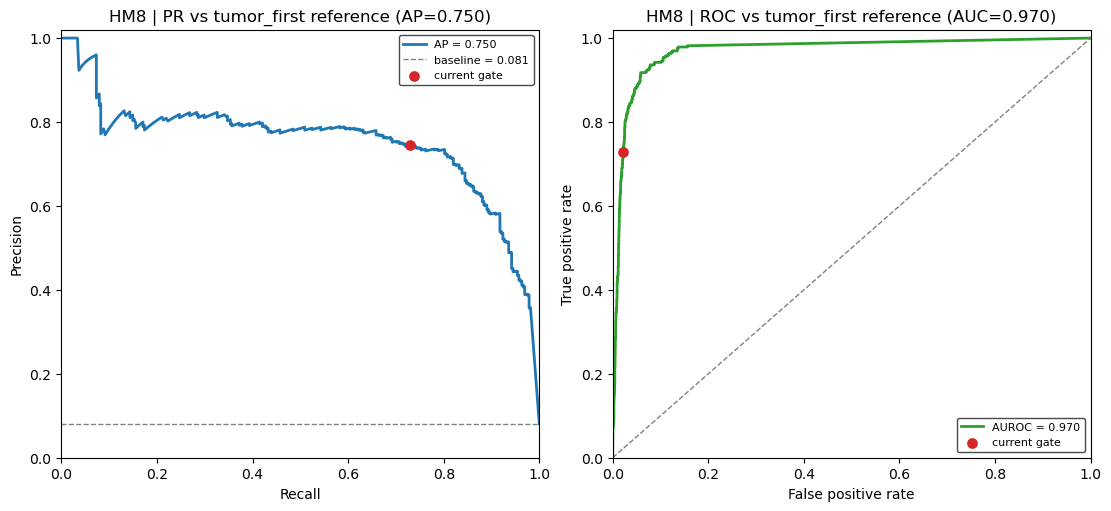

In [38]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

hm_eval_mask = hm_verification_mask
hm_eval_truth = (hm_tumor_first_mask & hm_eval_mask).astype(bool)
hm_eval_score = hm_spot_positive_vote.astype(float)
hm_eval_pred = (hm_spot_positive_mask & hm_eval_mask).astype(bool)

if hm_eval_truth.sum() == 0 or hm_eval_truth.sum() == hm_eval_mask.sum():
    raise RuntimeError('Cannot compute PR/ROC because the HM8 tumor_first reference has only one class in the evaluation mask.')

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    hm_eval_truth[hm_eval_mask],
    hm_eval_score[hm_eval_mask],
)
fpr_curve, tpr_curve, roc_thresholds = roc_curve(
    hm_eval_truth[hm_eval_mask],
    hm_eval_score[hm_eval_mask],
)
hm_average_precision = float(average_precision_score(hm_eval_truth[hm_eval_mask], hm_eval_score[hm_eval_mask]))
hm_auroc = float(roc_auc_score(hm_eval_truth[hm_eval_mask], hm_eval_score[hm_eval_mask]))

hm_operating_tp = int((hm_eval_pred & hm_eval_truth).sum())
hm_operating_fp = int((hm_eval_pred & ~hm_eval_truth & hm_eval_mask).sum())
hm_operating_fn = int((~hm_eval_pred & hm_eval_truth).sum())
hm_operating_tn = int((~hm_eval_pred & ~hm_eval_truth & hm_eval_mask).sum())
hm_operating_precision = hm_operating_tp / max(hm_operating_tp + hm_operating_fp, 1)
hm_operating_recall = hm_operating_tp / max(hm_operating_tp + hm_operating_fn, 1)
hm_operating_fpr = hm_operating_fp / max(hm_operating_fp + hm_operating_tn, 1)
hm_operating_tpr = hm_operating_recall

hm_curve_summary = {
    'reference_label': 'tumor_first',
    'score': 'hm_spot_positive_vote',
    'selection_uses_reference_labels': False,
    'n_eval_spots': int(hm_eval_mask.sum()),
    'n_reference_positive': int(hm_eval_truth.sum()),
    'reference_positive_fraction': float(hm_eval_truth[hm_eval_mask].mean()),
    'average_precision': hm_average_precision,
    'auroc': hm_auroc,
    'operating_precision': float(hm_operating_precision),
    'operating_recall': float(hm_operating_recall),
    'operating_fpr': float(hm_operating_fpr),
    'operating_predicted_positive_fraction': float(hm_eval_pred[hm_eval_mask].mean()),
}

print('HM8 confidence-gated transfer curve summary')
print(format_for_display(hm_curve_summary))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)

baseline_precision = float(hm_eval_truth[hm_eval_mask].mean())
axes[0].plot(recall_curve, precision_curve, color='tab:blue', linewidth=2, label=f'AP = {hm_average_precision:.3f}')
axes[0].axhline(baseline_precision, color='gray', linestyle='--', linewidth=1, label=f'baseline = {baseline_precision:.3f}')
axes[0].scatter([hm_operating_recall], [hm_operating_precision], color='tab:red', s=45, zorder=3, label='current gate')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title(f'HM8 | PR vs tumor_first reference (AP={hm_average_precision:.3f})')
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8)

axes[1].plot(fpr_curve, tpr_curve, color='tab:green', linewidth=2, label=f'AUROC = {hm_auroc:.3f}')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1)
axes[1].scatter([hm_operating_fpr], [hm_operating_tpr], color='tab:red', s=45, zorder=3, label='current gate')
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].set_title(f'HM8 | ROC vs tumor_first reference (AUC={hm_auroc:.3f})')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8)

export_figure_axes(fig, fallback_prefix='liver_confidence_curves')
plt.show()


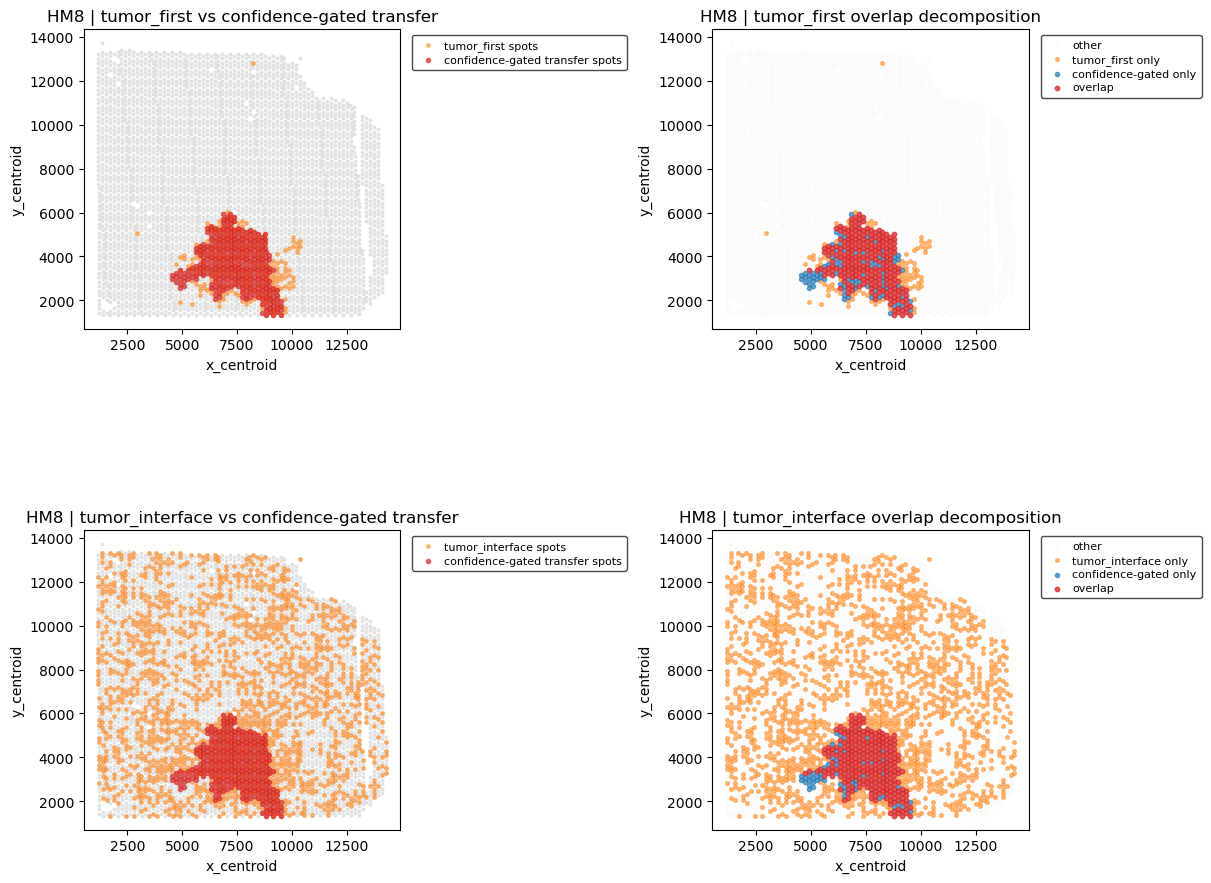

In [39]:
hm_true_tumor_first_mask = hm_tumor_first_mask & hm_verification_mask
hm_true_tumor_interface_mask = hm_tumor_interface_mask & hm_verification_mask

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

hm_other_first_mask = ~(hm_pred_mask | hm_true_tumor_first_mask)
hm_true_only_first_mask = hm_true_tumor_first_mask & ~hm_pred_mask
hm_pred_only_first_mask = hm_pred_mask & ~hm_true_tumor_first_mask
hm_overlap_first_mask = hm_pred_mask & hm_true_tumor_first_mask

axes[0, 0].scatter(hm_xy_raw[hm_verification_mask, 0], hm_xy_raw[hm_verification_mask, 1], s=4, alpha=0.08, color='black')
axes[0, 0].scatter(hm_xy_raw[hm_true_tumor_first_mask, 0], hm_xy_raw[hm_true_tumor_first_mask, 1], s=7, alpha=0.45, color='tab:orange', label='tumor_first spots')
axes[0, 0].scatter(hm_xy_raw[hm_pred_mask, 0], hm_xy_raw[hm_pred_mask, 1], s=9, alpha=0.65, color='tab:red', label='confidence-gated transfer spots')
axes[0, 0].set_aspect('equal')
axes[0, 0].set_title('HM8 | tumor_first vs confidence-gated transfer')
axes[0, 0].set_xlabel('x_centroid')
axes[0, 0].set_ylabel('y_centroid')
axes[0, 0].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

axes[0, 1].scatter(hm_xy_raw[hm_other_first_mask, 0], hm_xy_raw[hm_other_first_mask, 1], s=4, alpha=0.06, color='lightgray', label='other')
axes[0, 1].scatter(hm_xy_raw[hm_true_only_first_mask, 0], hm_xy_raw[hm_true_only_first_mask, 1], s=7, alpha=0.5, color='tab:orange', label='tumor_first only')
axes[0, 1].scatter(hm_xy_raw[hm_pred_only_first_mask, 0], hm_xy_raw[hm_pred_only_first_mask, 1], s=9, alpha=0.65, color='tab:blue', label='confidence-gated only')
axes[0, 1].scatter(hm_xy_raw[hm_overlap_first_mask, 0], hm_xy_raw[hm_overlap_first_mask, 1], s=10, alpha=0.75, color='tab:red', label='overlap')
axes[0, 1].set_aspect('equal')
axes[0, 1].set_title('HM8 | tumor_first overlap decomposition')
axes[0, 1].set_xlabel('x_centroid')
axes[0, 1].set_ylabel('y_centroid')
axes[0, 1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

hm_other_interface_mask = ~(hm_pred_mask | hm_true_tumor_interface_mask)
hm_true_only_interface_mask = hm_true_tumor_interface_mask & ~hm_pred_mask
hm_pred_only_interface_mask = hm_pred_mask & ~hm_true_tumor_interface_mask
hm_overlap_interface_mask = hm_pred_mask & hm_true_tumor_interface_mask

axes[1, 0].scatter(hm_xy_raw[hm_verification_mask, 0], hm_xy_raw[hm_verification_mask, 1], s=4, alpha=0.08, color='black')
axes[1, 0].scatter(hm_xy_raw[hm_true_tumor_interface_mask, 0], hm_xy_raw[hm_true_tumor_interface_mask, 1], s=7, alpha=0.45, color='tab:orange', label='tumor_interface spots')
axes[1, 0].scatter(hm_xy_raw[hm_pred_mask, 0], hm_xy_raw[hm_pred_mask, 1], s=9, alpha=0.65, color='tab:red', label='confidence-gated transfer spots')
axes[1, 0].set_aspect('equal')
axes[1, 0].set_title('HM8 | tumor_interface vs confidence-gated transfer')
axes[1, 0].set_xlabel('x_centroid')
axes[1, 0].set_ylabel('y_centroid')
axes[1, 0].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

axes[1, 1].scatter(hm_xy_raw[hm_other_interface_mask, 0], hm_xy_raw[hm_other_interface_mask, 1], s=4, alpha=0.06, color='lightgray', label='other')
axes[1, 1].scatter(hm_xy_raw[hm_true_only_interface_mask, 0], hm_xy_raw[hm_true_only_interface_mask, 1], s=7, alpha=0.5, color='tab:orange', label='tumor_interface only')
axes[1, 1].scatter(hm_xy_raw[hm_pred_only_interface_mask, 0], hm_xy_raw[hm_pred_only_interface_mask, 1], s=9, alpha=0.65, color='tab:blue', label='confidence-gated only')
axes[1, 1].scatter(hm_xy_raw[hm_overlap_interface_mask, 0], hm_xy_raw[hm_overlap_interface_mask, 1], s=10, alpha=0.75, color='tab:red', label='overlap')
axes[1, 1].set_aspect('equal')
axes[1, 1].set_title('HM8 | tumor_interface overlap decomposition')
axes[1, 1].set_xlabel('x_centroid')
axes[1, 1].set_ylabel('y_centroid')
axes[1, 1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True, facecolor='white', framealpha=0.95, edgecolor='0.25', fontsize=8, borderpad=0.45, handletextpad=0.4, labelspacing=0.35)

export_figure_axes(fig, fallback_prefix='liver_verification')
plt.show()


## Next Step

The liver transfer and verification are now in place. The next useful additions are:

1. compare liver versus lymph-node margin distributions and transfer-supported fractions directly
2. inspect whether the confidence-gated liver transfer regions are spatially sparse and annotation-enriched in the way a harder infiltration case should be
3. summarize what the transferable splat families reveal about metastasis versus infiltration across the patient-8 triad
